<a href="https://colab.research.google.com/github/SofiaP2002/SeminarioDeGradoII/blob/main/Cod_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
pip install sentence-transformers

## 1. Carga del Dataset


In [ ]:
import pandas as pd

filepath = 'consolidado_actualizado.csv'
try:
    df = pd.read_csv(filepath, encoding='latin1')
    print(f"El dataset '{filepath}' se ha cargado exitosamente.")
except FileNotFoundError:
    print(f"Error: El archivo '{filepath}' no se encontró. Asegúrate de que está en el directorio correcto.")
except Exception as e:
    print(f"Ocurrió  error al cargar o procesar el dataset: {e}")

El dataset 'consolidado_actualizado.csv' se ha cargado exitosamente.


## 2. Visión General del Dataset


In [ ]:
print("Primeras 5 filas del dataset:")
display(df.head())
print("\n--- Información general del dataset ---")
df.info()


Primeras 5 filas del dataset:


,ID,Issue_Key,Title_Estimacion_Inicial,Description_Estimacion_Inicial,Type,Priority,Creation_Date,Estimation_Date,Story_Point_Original,Story_Point_Final,...,Total_Effort_Minutes,Resolution_Time_Minutes,Creator_ID,Reporter_ID,Assignee_ID,Sprint_ID,Project_ID,Cantidad_Comentarios_Previos,Cantidad_Components,Components_Lista
0,68,XD-3765,Fix stream failover on YARN,"""""""See https://github.com/spring-projects/spri...",Story,Minor,3/21/2017 16:54,3/21/2017 16:54,8.0,8.0,...,0,0,72,72,71.0,NaN,1,0,0,NaN
1,77,XD-3756,"""wordcount failed to run in cloudera VM 5.7""","""""""I download the spring XD example projects, ...",Story,Blocker,5/23/2016 10:11,5/23/2016 9:11,3.0,3.0,...,0,0,83,83,NaN,NaN,1,0,0,NaN
2,109,XD-3724,"""Add Job RDBMS config in Ambari plugin""","""""""Spring XD Ambari plugin only supports HDB a...",Story,Minor,12/16/2015 18:38,12/16/2015 18:38,2.0,2.0,...,0,0,99,99,NaN,NaN,1,0,1,UI
3,118,XD-3715,Move K8s SPI to a separate repo,"""""""As a developer, I'd like to move k8s SPI to...",Story,Minor,11/30/2015 15:11,11/30/2015 15:11,5.0,5.0,...,1725,11833,78,78,94.0,4.0,1,0,0,NaN
4,119,XD-3714,"""Upgrade XD Ambari release to 1.3 ""","""""""As a developer, I'd like to upgrade Spring ...",Story,Minor,11/30/2015 14:33,11/30/2015 14:33,3.0,3.0,...,1108,3006,78,78,71.0,4.0,1,0,0,NaN



--- Información general del dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21733 entries, 0 to 21732
Data columns (total 25 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   ID                                    21733 non-null  int64  
 1   Issue_Key                             21733 non-null  object 
 2   Title_Estimacion_Inicial              21733 non-null  object 
 3   Description_Estimacion_Inicial        18942 non-null  object 
 4   Type                                  21733 non-null  object 
 5   Priority                              5764 non-null   object 
 6   Creation_Date                         21733 non-null  object 
 7   Estimation_Date                       21733 non-null  object 
 8   Story_Point_Original                  21733 non-null  float64
 9   Story_Point_Final                     21733 non-null  float64
 10  Story_Point_Changed_After_Estimation  217

## 3. Estadísticas Descriptivas


In [ ]:
if 'df' in locals() and df is not None:
    print("--- Estadísticas descriptivas del dataset ---")
    display(df.describe())
else:
    print("No se pudieron mostrar las estadísticas descriptivas porque el DataFrame no se cargó correctamente.")

--- Estadísticas descriptivas del dataset ---


,ID,Story_Point_Original,Story_Point_Final,Story_Point_Changed_After_Estimation,Title_Changed_After_Estimation,Description_Changed_After_Estimation,Timespent,In_Progress_Minutes,Total_Effort_Minutes,Resolution_Time_Minutes,Creator_ID,Reporter_ID,Assignee_ID,Sprint_ID,Project_ID,Cantidad_Comentarios_Previos,Cantidad_Components
count,21733.000000,21733.000000,21733.000000,21733.000000,21733.000000,21733.0,202.000000,2.173300e+04,2.173300e+04,2.173300e+04,21733.000000,21733.000000,19627.000000,9460.000000,21733.000000,21733.000000,21733.000000
mean,211252.187319,4.443907,4.337716,0.178070,0.144619,0.0,707.272277,1.592044e+04,2.353175e+04,1.183720e+05,124856.726683,124851.209313,127986.955113,2549.671670,23.341508,0.000322,0.603184
std,99820.679662,12.703157,5.398429,0.382581,0.351724,0.0,692.429884,6.244727e+04,8.717325e+04,3.018779e+05,54035.903221,54033.243147,50058.371178,1297.979075,9.941679,0.026270,0.718976
min,68.000000,-1.000000,0.000000,0.000000,0.000000,0.0,1.000000,0.000000e+00,0.000000e+00,0.000000e+00,71.000000,71.000000,71.000000,4.000000,1.000000,0.000000,0.000000
25%,223815.000000,1.000000,1.000000,0.000000,0.000000,0.0,240.000000,0.000000e+00,0.000000e+00,1.519000e+03,145722.000000,145722.000000,145723.000000,2898.000000,28.000000,0.000000,0.000000
50%,232631.000000,3.000000,3.000000,0.000000,0.000000,0.0,480.000000,3.400000e+01,1.378000e+03,2.148400e+04,145765.000000,145765.000000,145763.000000,3047.000000,28.000000,0.000000,1.000000
75%,241257.000000,5.000000,5.000000,0.000000,0.000000,0.0,960.000000,8.498000e+03,1.524900e+04,9.492300e+04,145867.000000,145819.000000,145820.000000,3174.000000,28.000000,0.000000,1.000000
max,460229.000000,1010.000000,105.000000,1.000000,1.000000,0.0,4020.000000,2.201680e+06,2.324198e+06,4.295834e+06,199934.000000,199934.000000,199341.000000,4970.000000,42.000000,3.000000,19.000000


## 4. Conteo de Valores Nulos

In [ ]:
print("--- Conteo de valores nulos por columna ---")
print(df.isnull().sum())

--- Conteo de valores nulos por columna ---
ID                                          0
Issue_Key                                   0
Title_Estimacion_Inicial                    0
Description_Estimacion_Inicial           2791
Type                                        0
Priority                                15969
Creation_Date                               0
Estimation_Date                             0
Story_Point_Original                        0
Story_Point_Final                           0
Story_Point_Changed_After_Estimation        0
Title_Changed_After_Estimation              0
Description_Changed_After_Estimation        0
Timespent                               21531
In_Progress_Minutes                         0
Total_Effort_Minutes                        0
Resolution_Time_Minutes                     0
Creator_ID                                  0
Reporter_ID                                 0
Assignee_ID                              2106
Sprint_ID                           

## 5. Frecuencia de Columnas Categóricas

In [ ]:
categorical_columns = ['Priority', 'Type', 'Sprint_ID', 'Project_ID', 'Assignee_ID', 'Reporter_ID', 'Creator_ID']

for col in categorical_columns:
  print(f"\n--- Frecuencia de la columna '{col}' ---")

  display(df[col].value_counts().head())



--- Frecuencia de la columna 'Priority' ---


,count
Priority,
Minor,2592
High,967
Medium,827
Major,718
Critical,258



--- Frecuencia de la columna 'Type' ---


,count
Type,
Story,21733



--- Frecuencia de la columna 'Sprint_ID' ---


...

,count
Assignee_ID,
145769.0,512
145726.0,461
145778.0,442
145720.0,442
145748.0,404



--- Frecuencia de la columna 'Reporter_ID' ---


,count
Reporter_ID,
145778,854
145726,763
145807,739
145770,651
78,596



--- Frecuencia de la columna 'Creator_ID' ---


,count
Creator_ID,
145778,854
145726,763
145807,730
78,595
145874,568


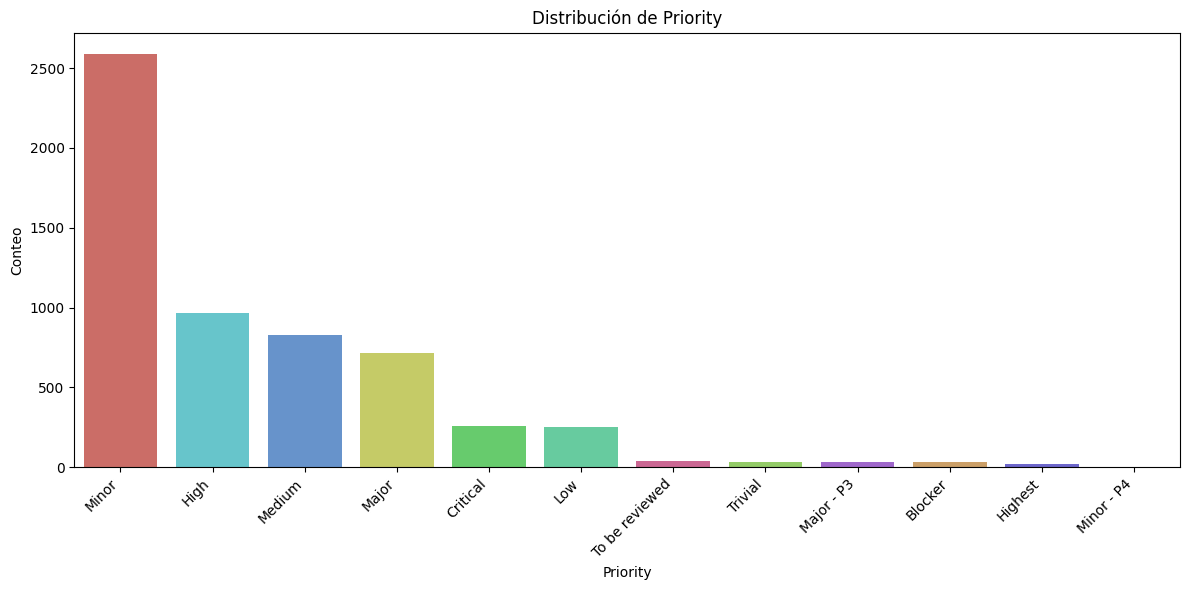

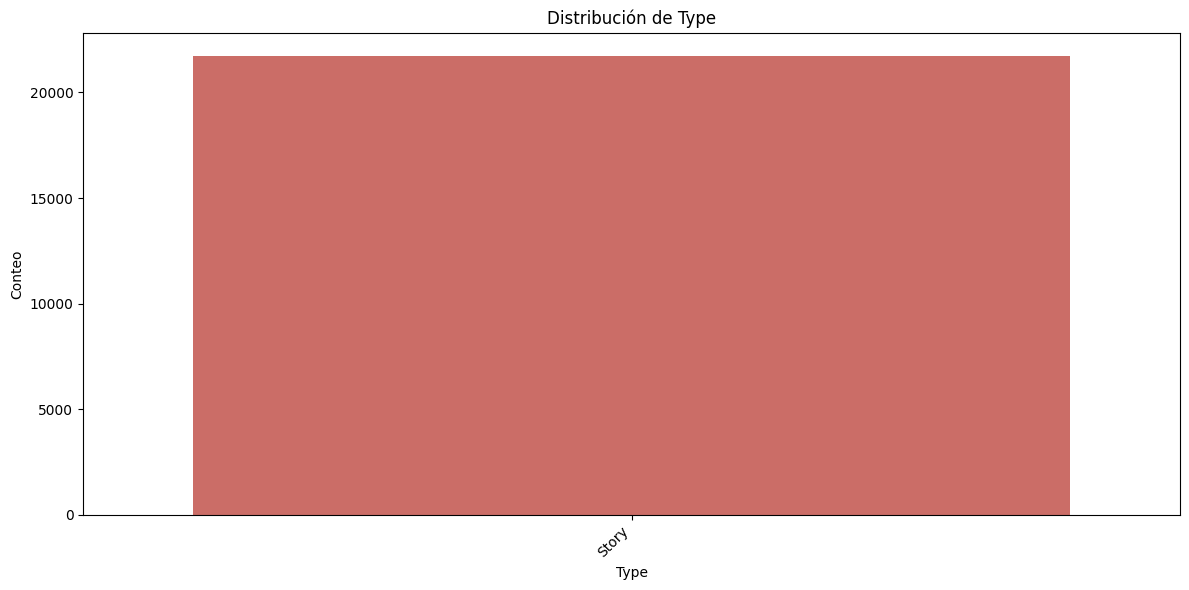

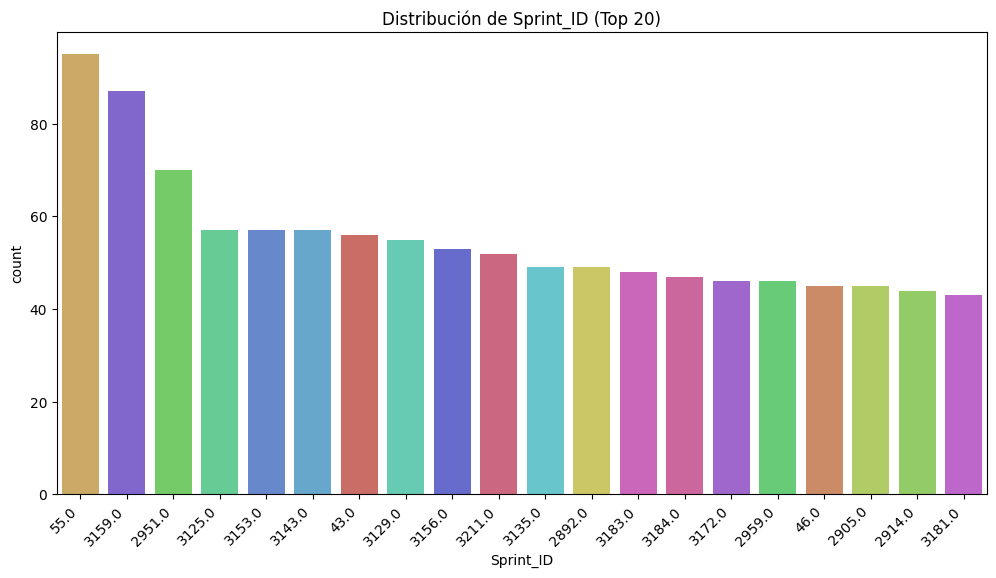

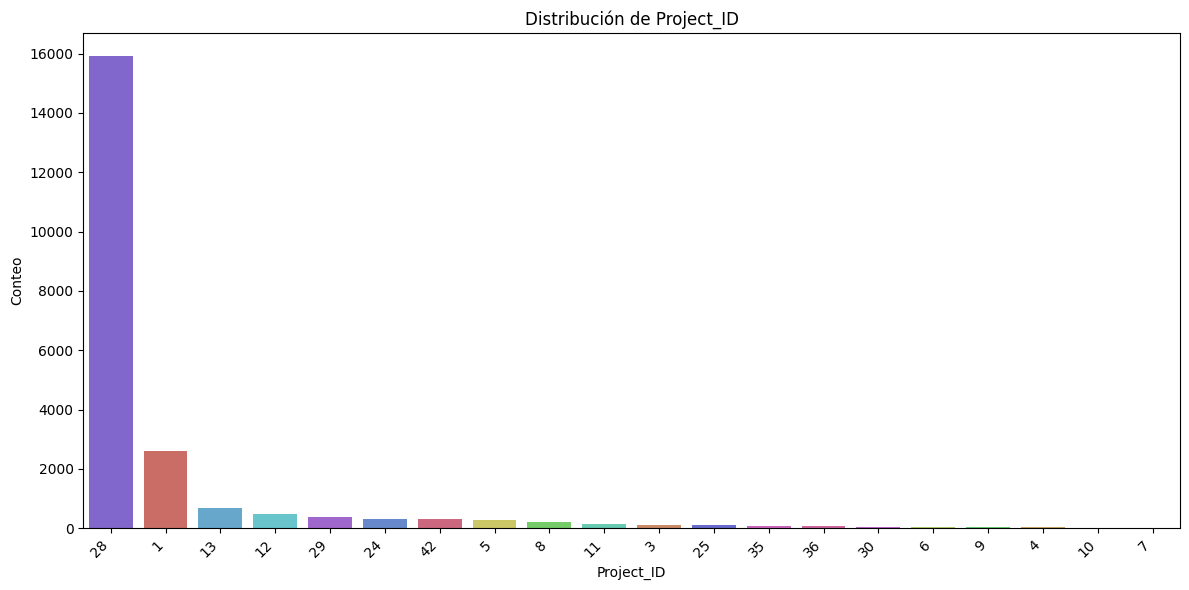

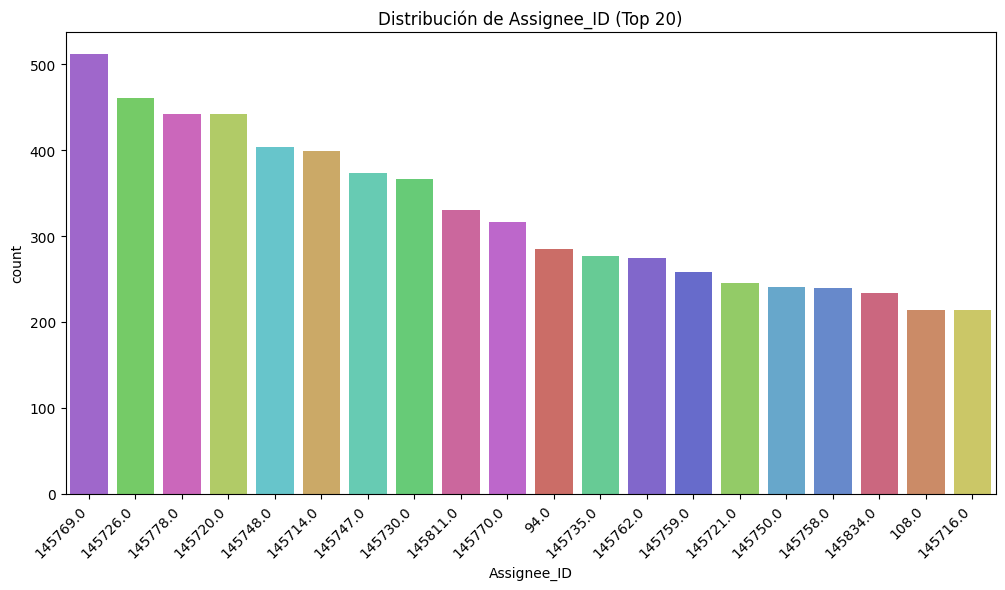

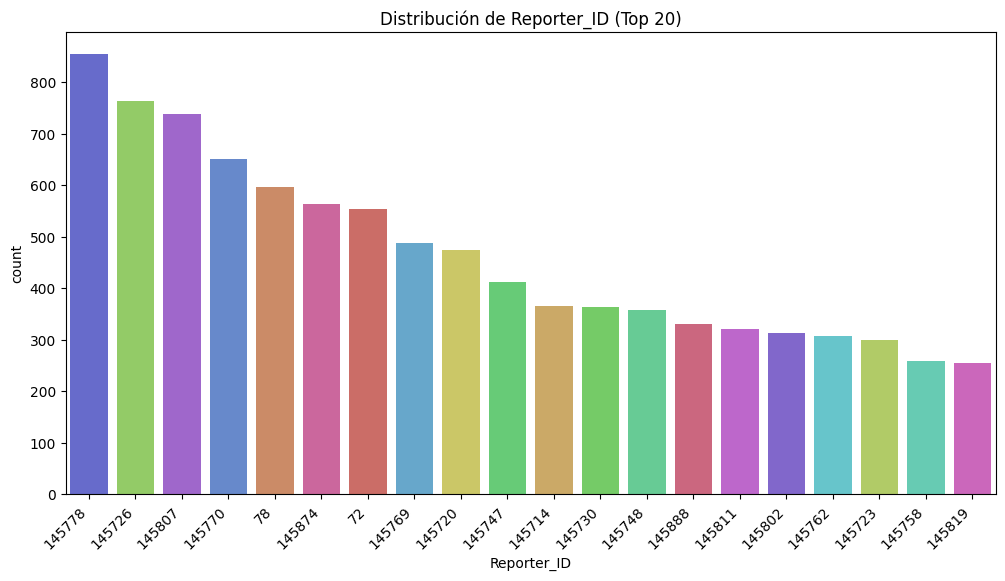

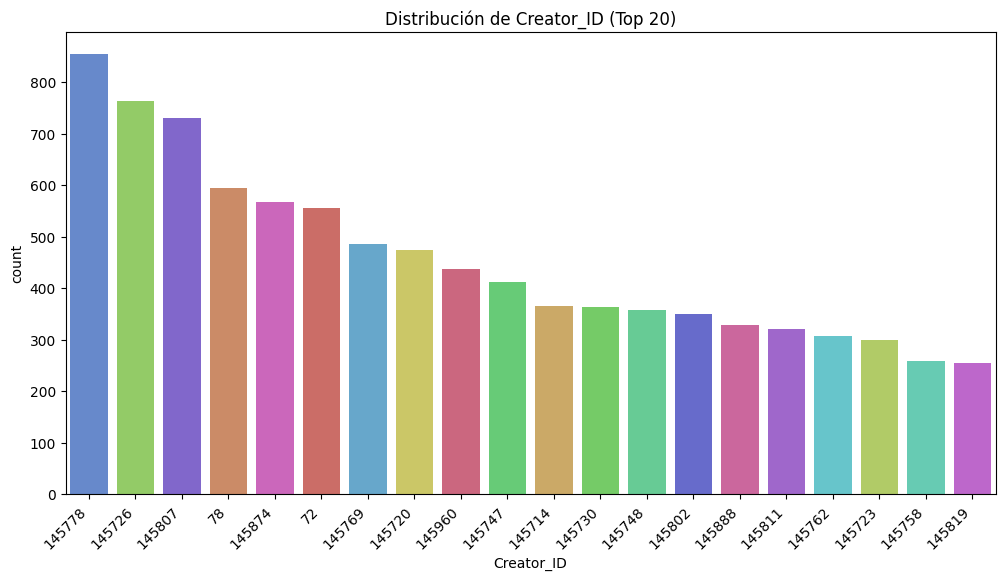

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

categorical_columns = ['Priority', 'Type', 'Sprint_ID', 'Project_ID', 'Assignee_ID', 'Reporter_ID', 'Creator_ID']

for col in categorical_columns:
  plt.figure(figsize=(12, 6))
  if df[col].nunique() > 20:

    top_categories = df[col].value_counts().nlargest(20).index
    n_colors_to_use = len(top_categories)
    current_palette = sns.color_palette("hls", n_colors=n_colors_to_use)
    sns.countplot(data=df[df[col].isin(top_categories)], x=col, order=top_categories, palette=current_palette, hue=col, legend=False)
    plt.title(f'Distribución de {col} (Top 20)')
    plt.xticks(rotation=45, ha='right')
  else:
    n_colors_to_use = df[col].nunique()
    current_palette = sns.color_palette("hls", n_colors=n_colors_to_use)
    sns.countplot(data=df, x=col, order=df[col].value_counts().index, palette=current_palette, hue=col, legend=False)
    plt.title(f'Distribución de {col}')
    plt.xticks(rotation=45, ha='right')
    plt.xlabel(col)
    plt.ylabel('Conteo')
    plt.tight_layout()
    plt.show()


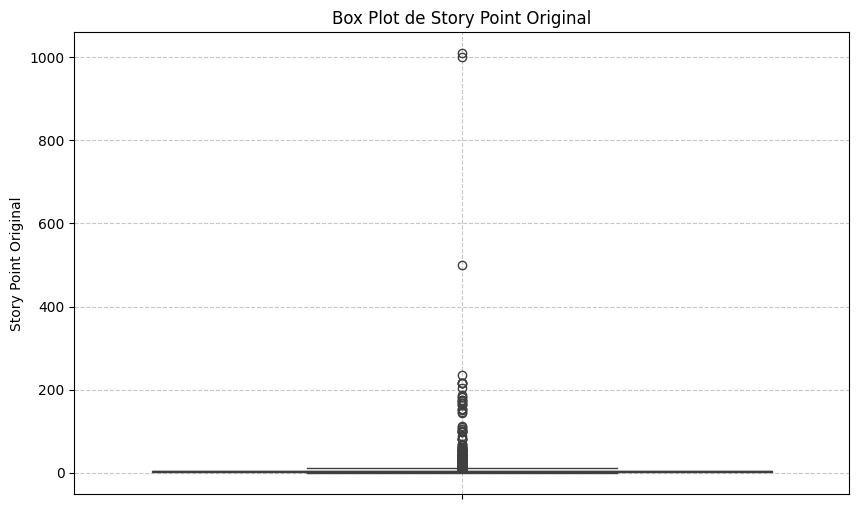

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.boxplot(y=df['Story_Point_Original'])
plt.title('Box Plot de Story Point Original')
plt.ylabel('Story Point Original')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()


Generando box plot para 'Story_Point_Original' con escala logarítmica en el eje Y...


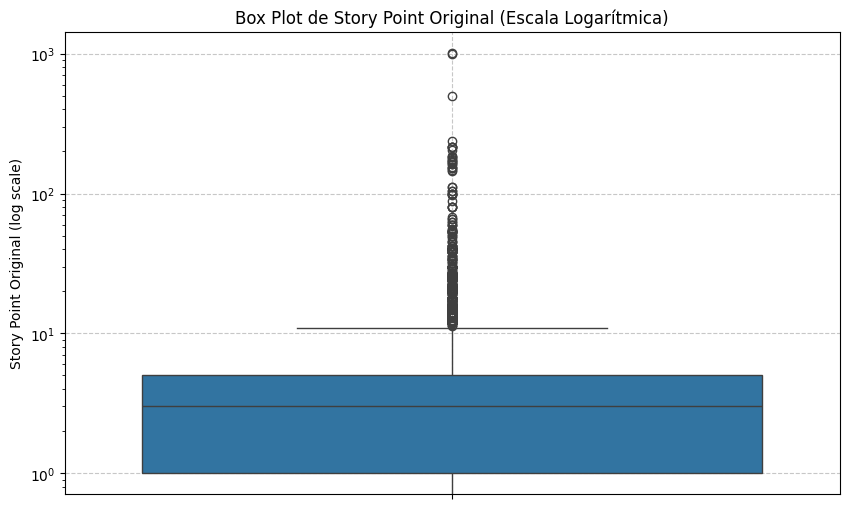

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

print("Generando box plot para 'Story_Point_Original' con escala logarítmica en el eje Y...")
plt.figure(figsize=(10, 6))
sns.boxplot(y=df['Story_Point_Original'])
plt.title('Box Plot de Story Point Original (Escala Logarítmica)')
plt.ylabel('Story Point Original (log scale)')
plt.yscale('log') # Aplicar escala logarítmica al eje Y
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()


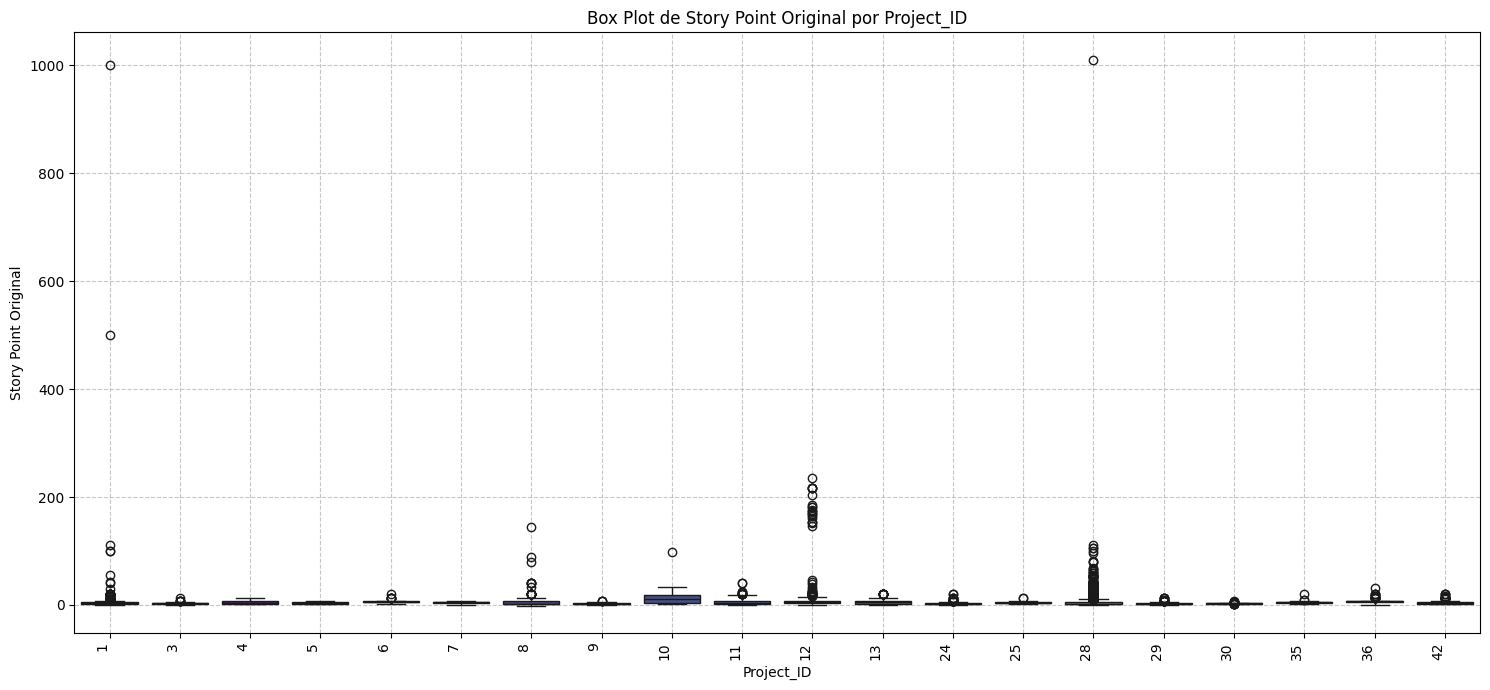

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(15, 7))
sns.boxplot(x='Project_ID', y='Story_Point_Original', data=df, palette='viridis', hue='Project_ID', legend=False)
plt.title('Box Plot de Story Point Original por Project_ID')
plt.xlabel('Project_ID')
plt.ylabel('Story Point Original')
plt.xticks(rotation=90, ha='right')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


/tmp/ipykernel_5635/4082567863.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Story_Point_Original'], palette='viridis')


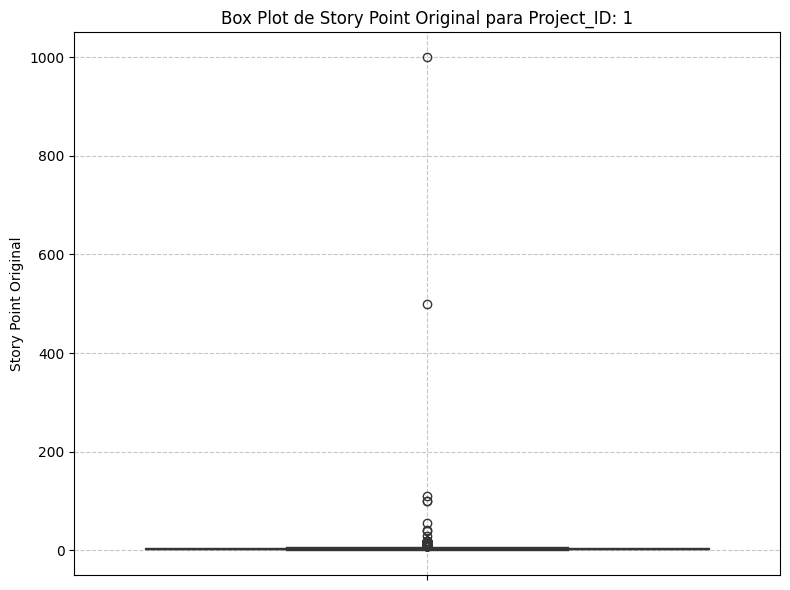

/tmp/ipykernel_5635/4082567863.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Story_Point_Original'], palette='viridis')


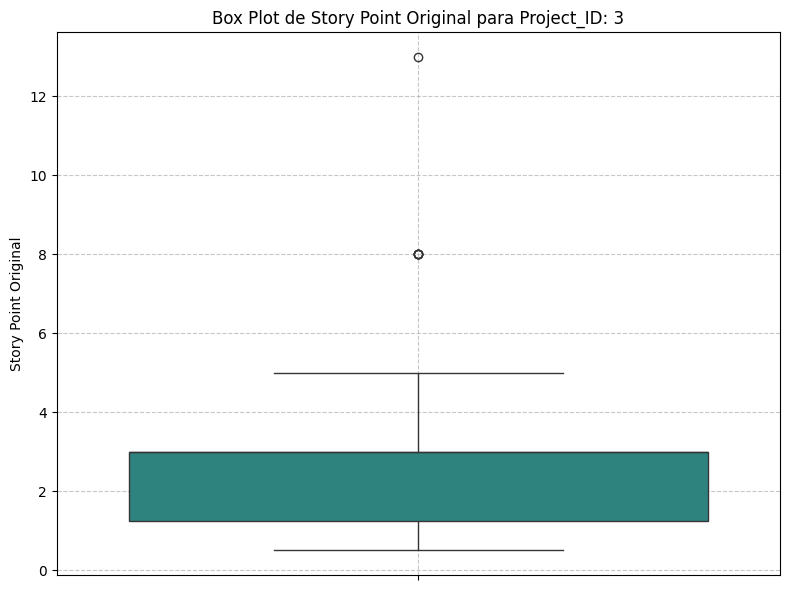

/tmp/ipykernel_5635/4082567863.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Story_Point_Original'], palette='viridis')


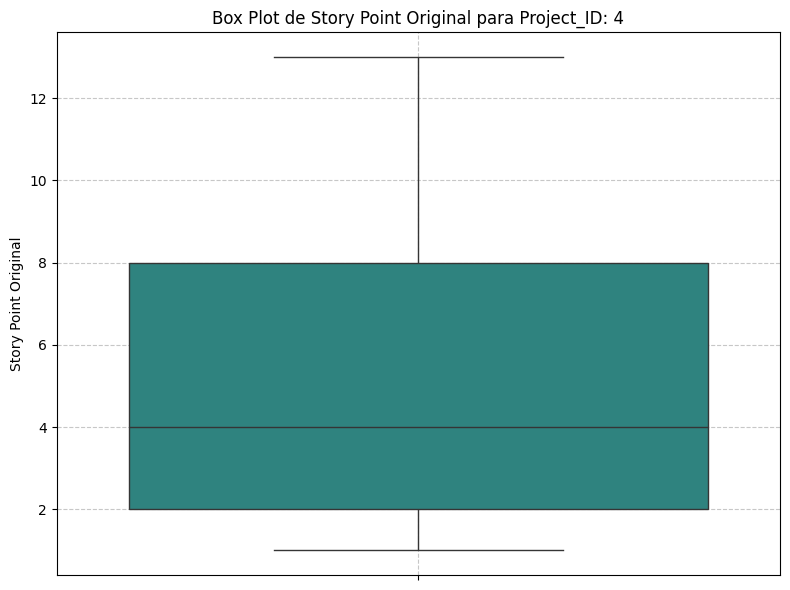

/tmp/ipykernel_5635/4082567863.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Story_Point_Original'], palette='viridis')


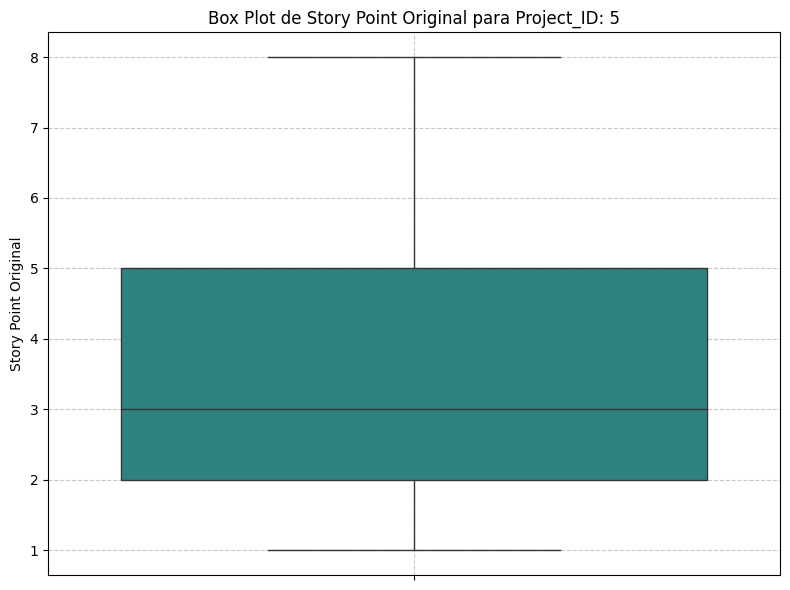

/tmp/ipykernel_5635/4082567863.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Story_Point_Original'], palette='viridis')


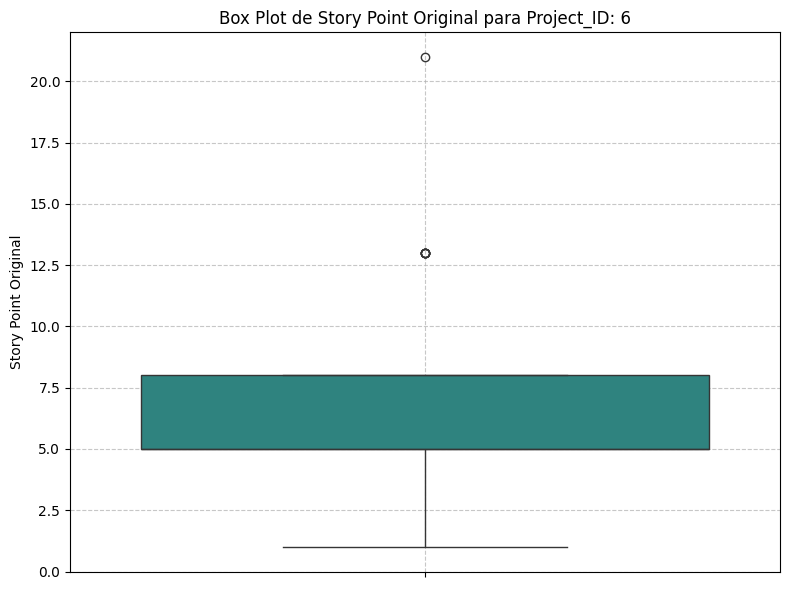

/tmp/ipykernel_5635/4082567863.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Story_Point_Original'], palette='viridis')


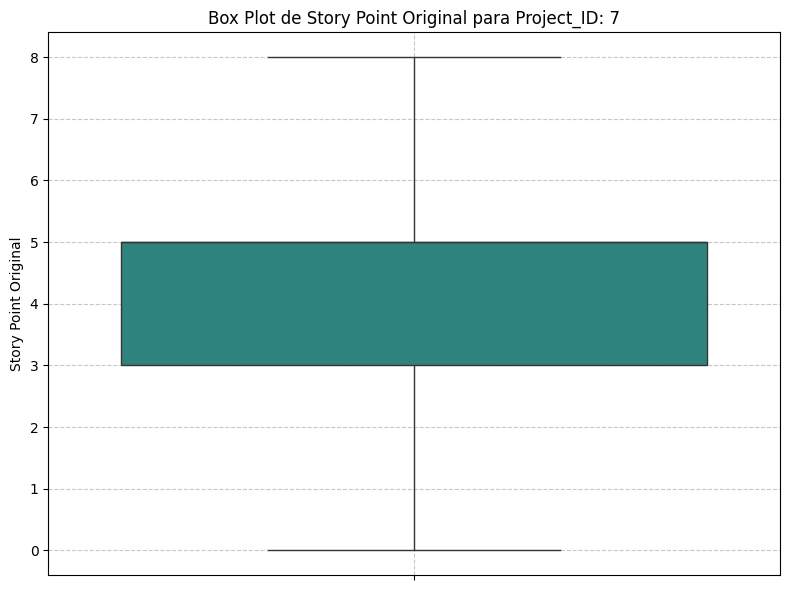

/tmp/ipykernel_5635/4082567863.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Story_Point_Original'], palette='viridis')


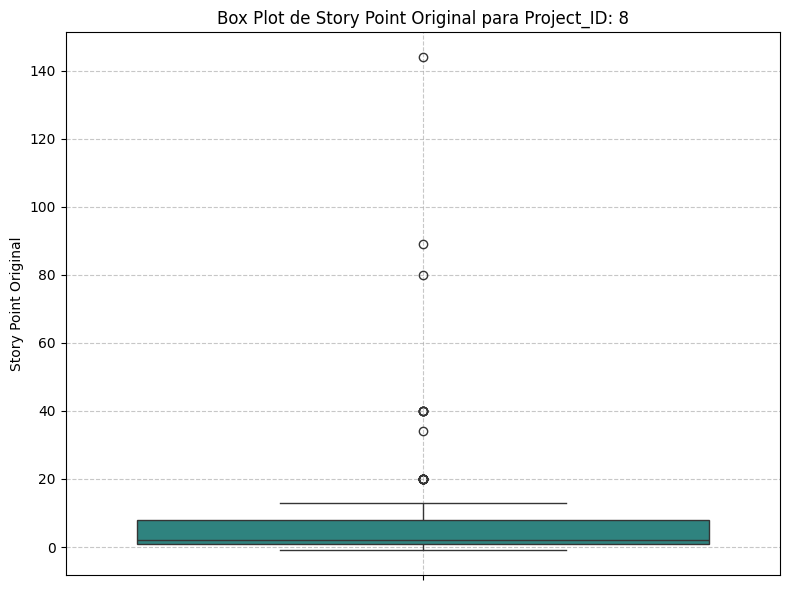

/tmp/ipykernel_5635/4082567863.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Story_Point_Original'], palette='viridis')


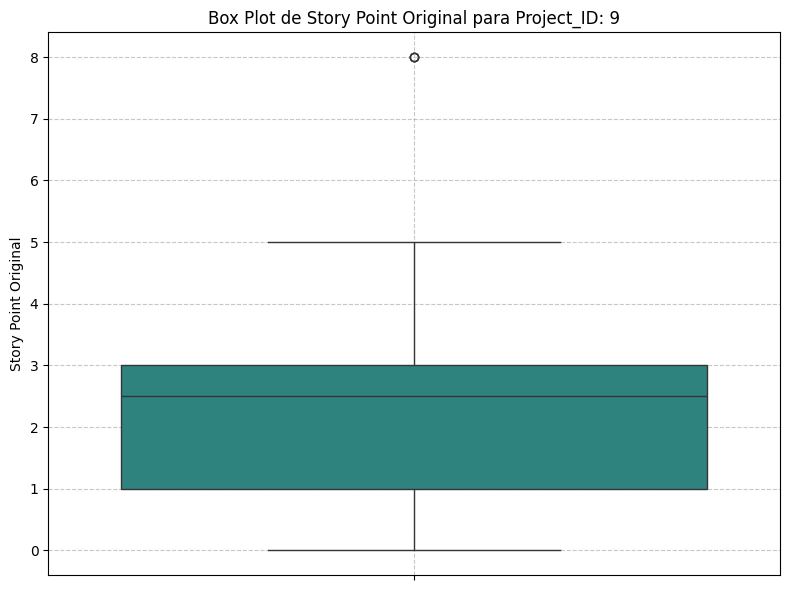

/tmp/ipykernel_5635/4082567863.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Story_Point_Original'], palette='viridis')


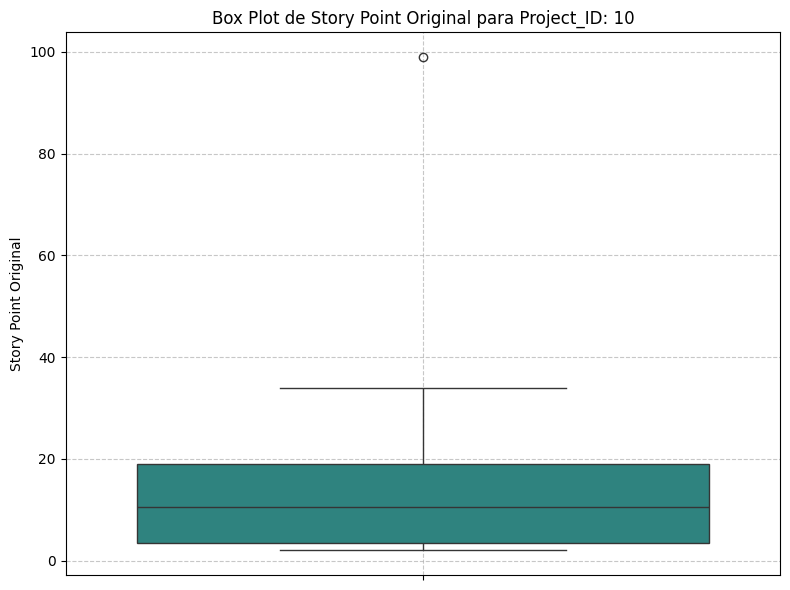

/tmp/ipykernel_5635/4082567863.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Story_Point_Original'], palette='viridis')


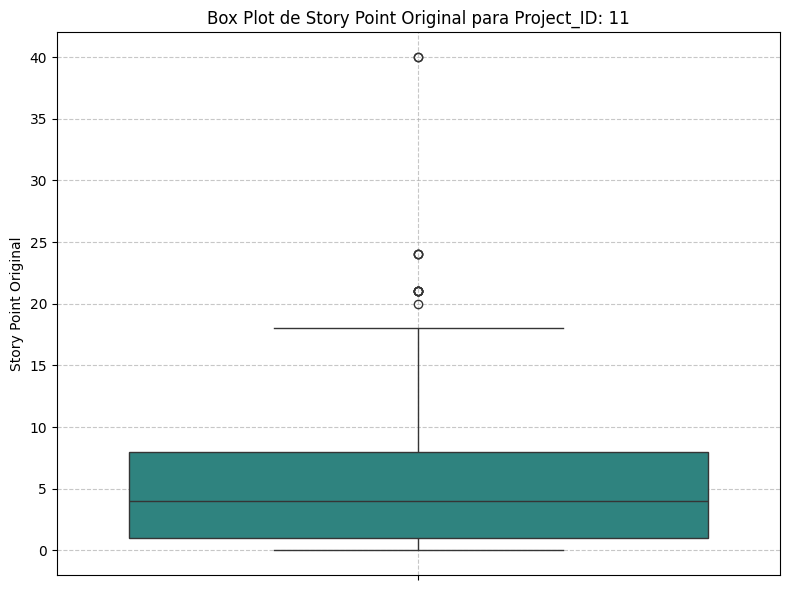

/tmp/ipykernel_5635/4082567863.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Story_Point_Original'], palette='viridis')


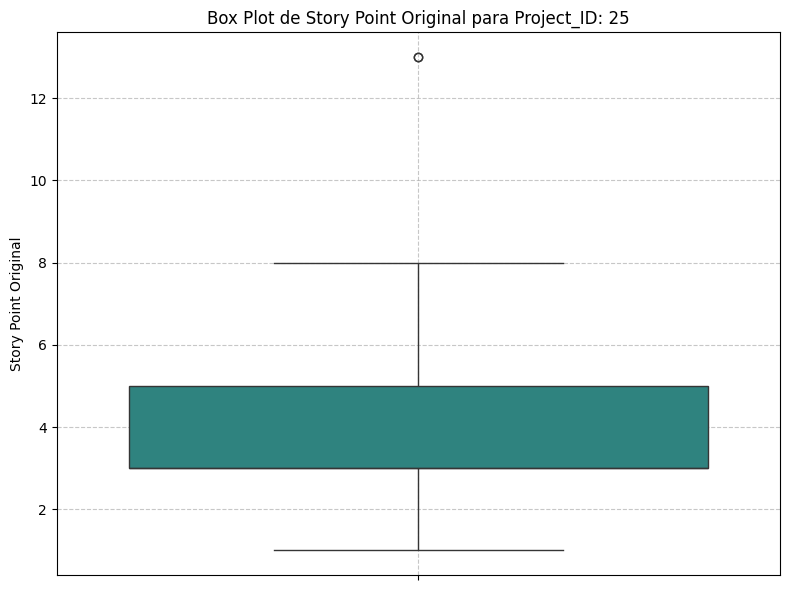

/tmp/ipykernel_5635/4082567863.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Story_Point_Original'], palette='viridis')


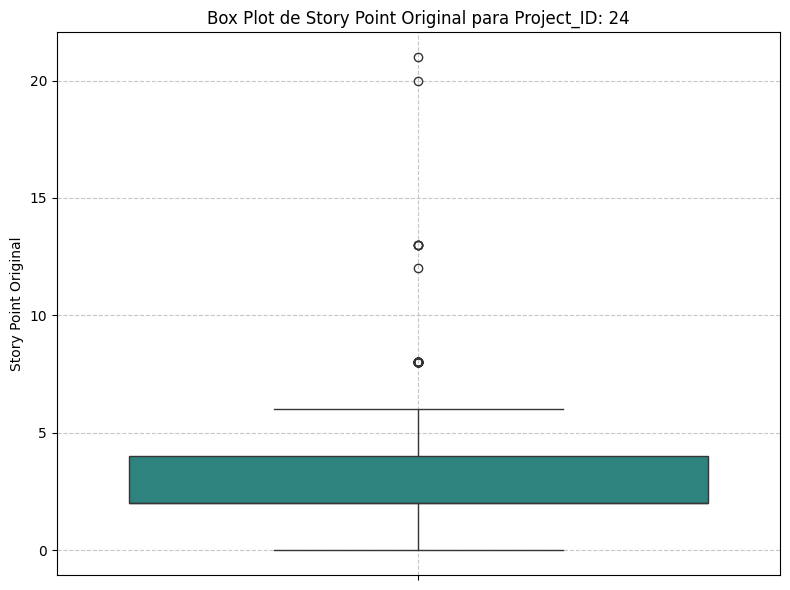

/tmp/ipykernel_5635/4082567863.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Story_Point_Original'], palette='viridis')


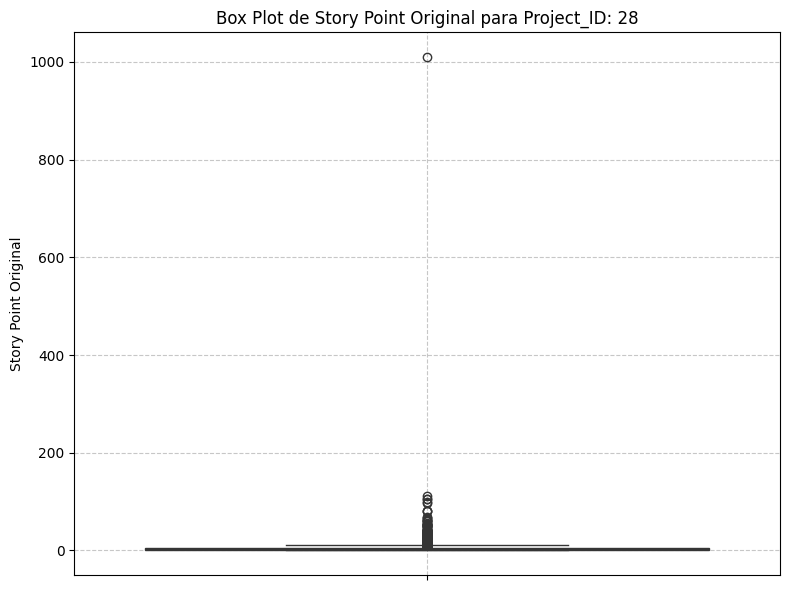

/tmp/ipykernel_5635/4082567863.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Story_Point_Original'], palette='viridis')


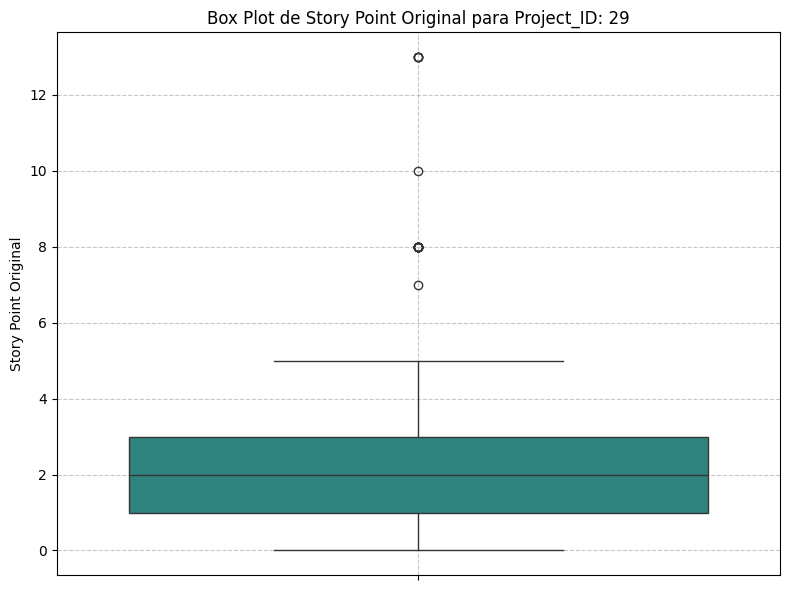

/tmp/ipykernel_5635/4082567863.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Story_Point_Original'], palette='viridis')


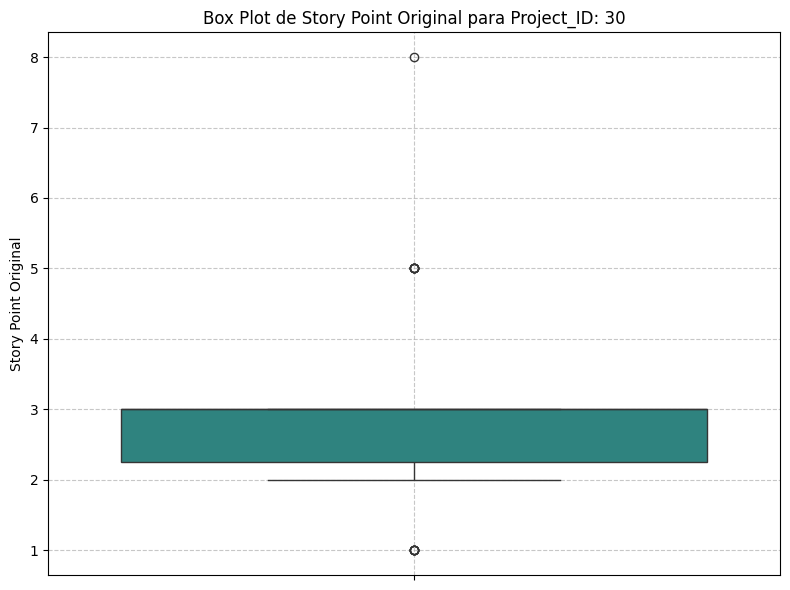

/tmp/ipykernel_5635/4082567863.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Story_Point_Original'], palette='viridis')


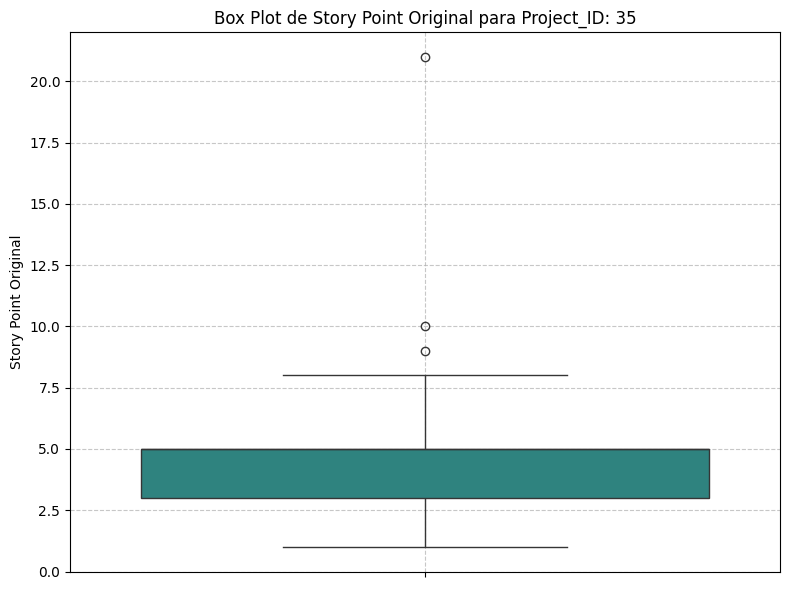

/tmp/ipykernel_5635/4082567863.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Story_Point_Original'], palette='viridis')


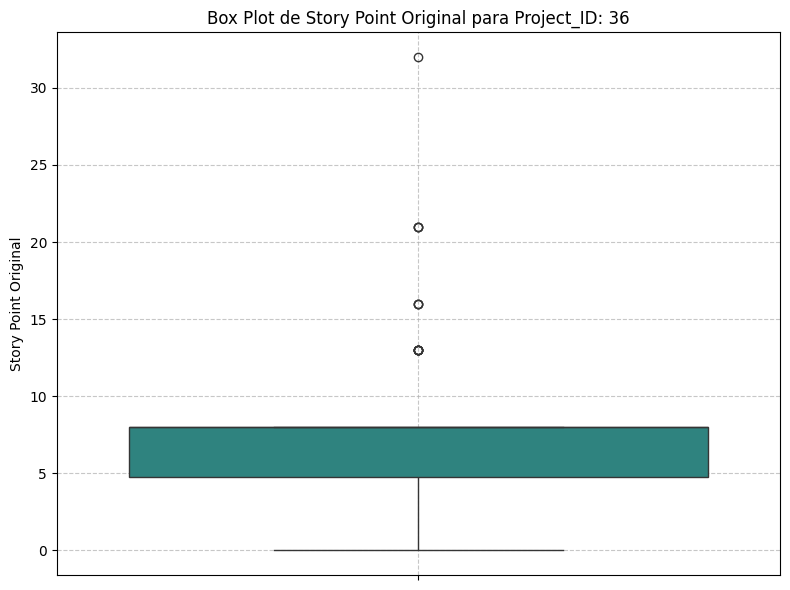

/tmp/ipykernel_5635/4082567863.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Story_Point_Original'], palette='viridis')


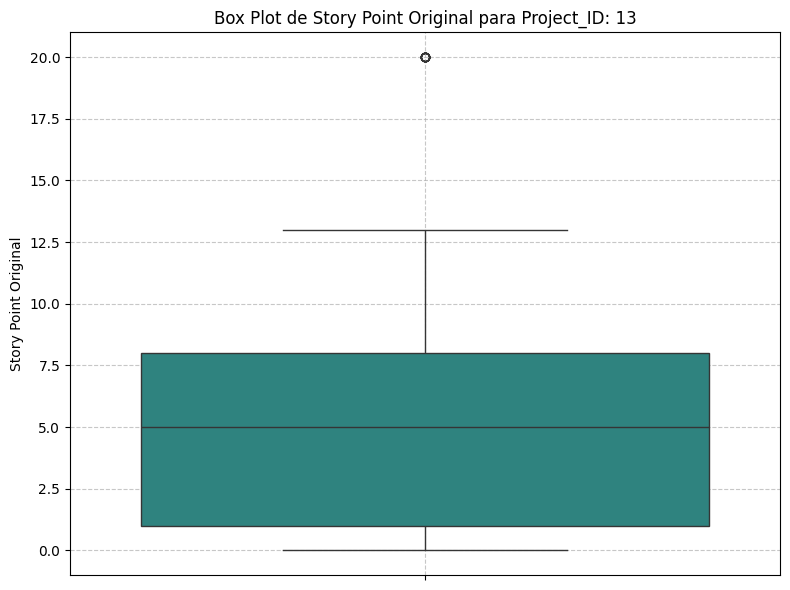

/tmp/ipykernel_5635/4082567863.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Story_Point_Original'], palette='viridis')


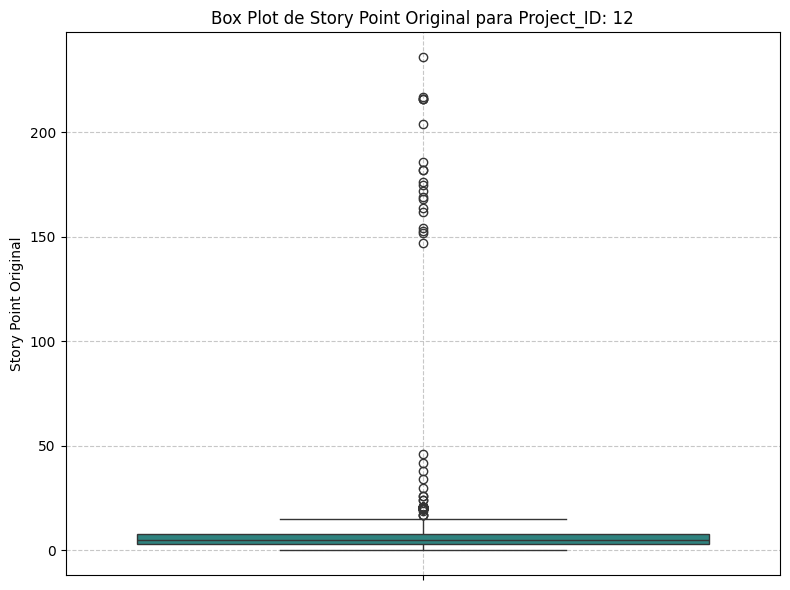

/tmp/ipykernel_5635/4082567863.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Story_Point_Original'], palette='viridis')


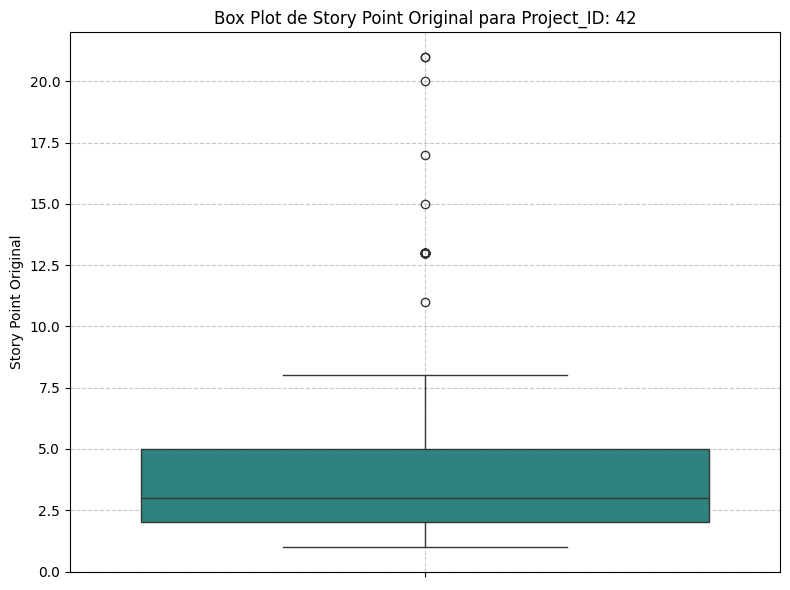

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

unique_project_ids = df['Project_ID'].unique()

for project_id in unique_project_ids:
    subset_df = df[df['Project_ID'] == project_id]

    if not subset_df.empty:
        plt.figure(figsize=(8, 6))
        sns.boxplot(y=subset_df['Story_Point_Original'], palette='viridis')
        plt.title(f'Box Plot de Story Point Original para Project_ID: {project_id}')
        plt.ylabel('Story Point Original')
        plt.grid(True, linestyle='--', alpha=0.7)
        plt.tight_layout()
        plt.show()

Generando histograma vertical para la columna 'Components_Lista' con colores distintos por barra...


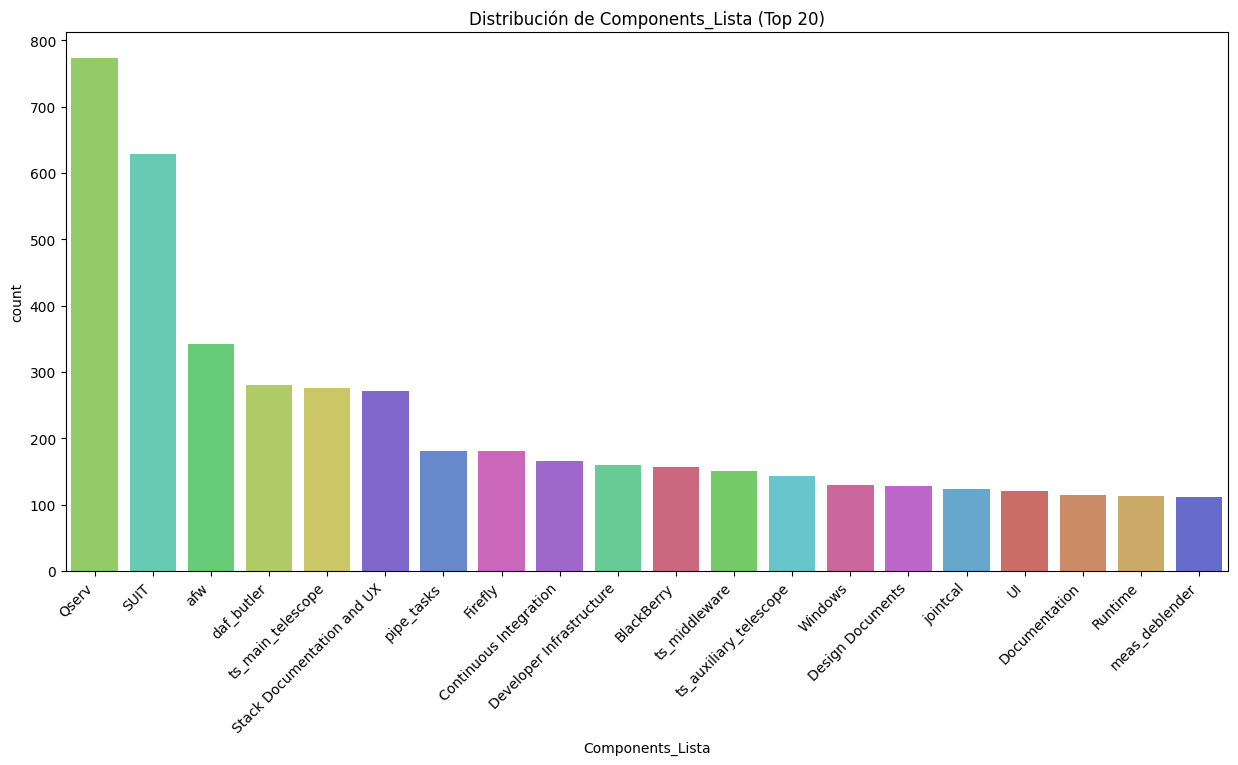

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

col = 'Components_Lista'
print(f"Generando histograma vertical para la columna '{col}' con colores distintos por barra...")

plt.figure(figsize=(15, 7))

if df[col].nunique() > 20:

  top_categories = df[col].value_counts().nlargest(20).index
  n_colors_to_use = len(top_categories)
  current_palette = sns.color_palette("hls", n_colors=n_colors_to_use)
  sns.countplot(data=df[df[col].isin(top_categories)], x=col, order=top_categories, palette=current_palette, hue=col, legend=False)
  plt.title(f'Distribución de {col} (Top 20)')
  plt.xticks(rotation=45, ha='right')
else:
  n_colors_to_use = df[col].nunique()
  current_palette = sns.color_palette("hls", n_colors=n_colors_to_use)
  sns.countplot(data=df, x=col, order=df[col].value_counts().index, palette=current_palette, hue=col, legend=False)
  plt.title(f'Distribución de {col}')
  plt.xticks(rotation=45, ha='right')

  plt.xlabel(col)
  plt.ylabel('Conteo')
  plt.tight_layout()
  plt.show()


### 6.1 Exploración de 'Components_Lista'


In [ ]:
if 'df' in locals() and df is not None:
    # Mostrar las primeras 10 entradas no nulas para identificar el delimitador
    display(df['Components_Lista'].dropna().head(10))
else:
    print("El DataFrame no se cargó correctamente.")

,Components_Lista
2,UI
15,Documentation
18,Batch
40,"Packaging, Configuration, Hadoop"
57,"Packaging, Hadoop"
81,Hadoop
96,"Packaging, Configuration, Hadoop"
97,Acceptance Testing
100,"Stream Module, Runtime"
150,REST


--- Frecuencia de Componentes Individuales ---


,count
Qserv,809
SUIT,729
afw,431
ts_main_telescope,355
daf_butler,339
Stack Documentation and UX,324
pipe_tasks,311
Firefly,280
Continuous Integration,247
Developer Infrastructure,225


/tmp/ipykernel_5635/3011295880.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=component_counts.head(20).values, y=component_counts.head(20).index, palette='viridis')


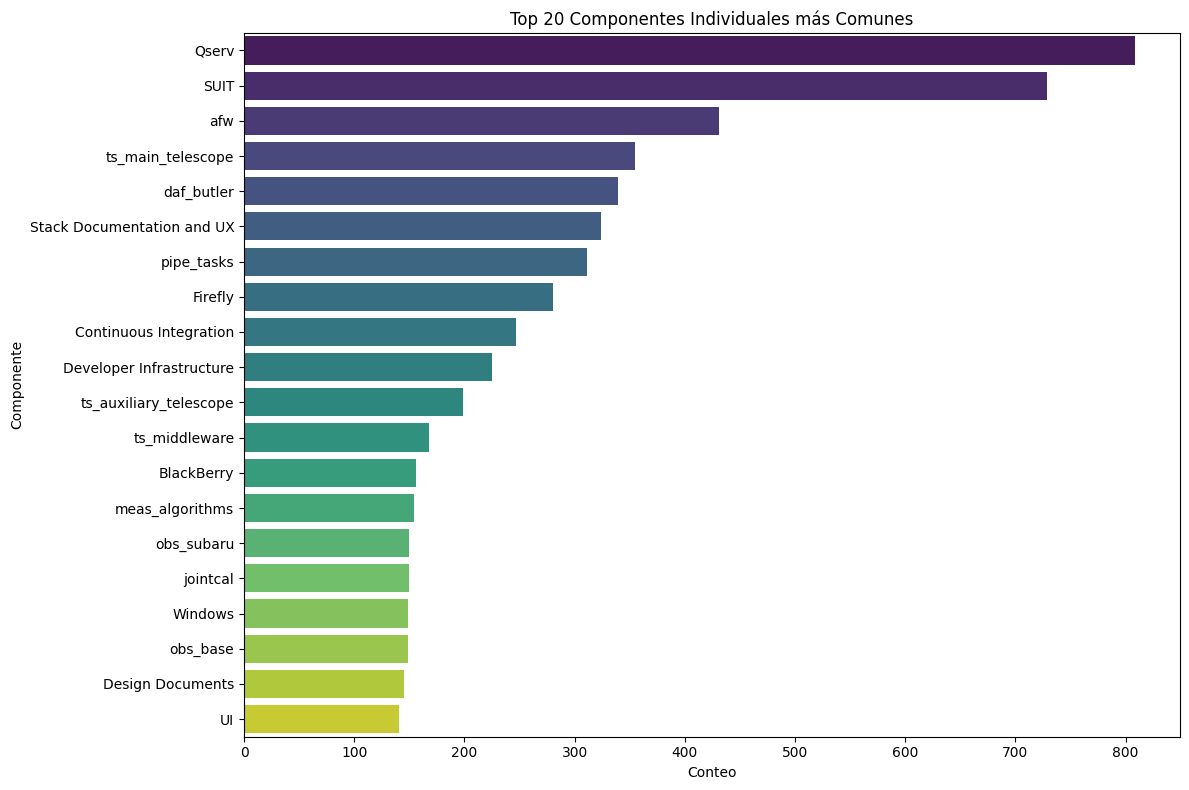

In [ ]:
all_components = df['Components_Lista'].fillna('').astype(str).str.split(', ')
flat_components = [component.strip() for sublist in all_components for component in sublist if component.strip()]
# Contar la frecuencia de cada componente
component_counts = pd.Series(flat_components).value_counts()
print("--- Frecuencia de Componentes Individuales ---")
display(component_counts.head(20))

# Visualizar los top 20 componentes
plt.figure(figsize=(12, 8))
sns.barplot(x=component_counts.head(20).values, y=component_counts.head(20).index, palette='viridis')
plt.title('Top 20 Componentes Individuales más Comunes')
plt.xlabel('Conteo')
plt.ylabel('Componente')
plt.tight_layout()
plt.show()


Generando countplot para la columna 'Story_Point_Changed_After_Estimation'...


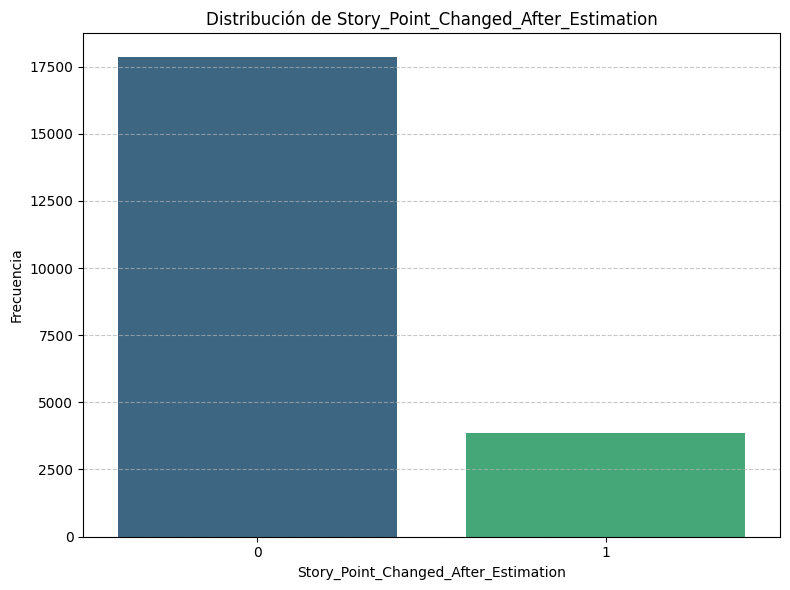

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

column_name = 'Story_Point_Changed_After_Estimation'
print(f"Generando countplot para la columna '{column_name}'...")
plt.figure(figsize=(8, 6))
# Apply the recommended change to address the FutureWarning
sns.countplot(x=column_name, data=df, palette='viridis', hue=column_name, legend=False)
plt.title(f'Distribución de {column_name}')
plt.xlabel(column_name)
plt.ylabel('Frecuencia')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


In [ ]:
count_table = df.groupby(['Project_ID', 'Story_Point_Changed_After_Estimation']).size().unstack(fill_value=0)

print("--- Conteo de Story Point Changed After Estimation por Project_ID ---")
display(count_table)


--- Conteo de Story Point Changed After Estimation por Project_ID ---


Story_Point_Changed_After_Estimation,0,1
Project_ID,,
1,2226,366
3,88,22
4,20,3
5,237,45
6,30,3
7,10,1
8,177,25
9,25,1
10,18,0


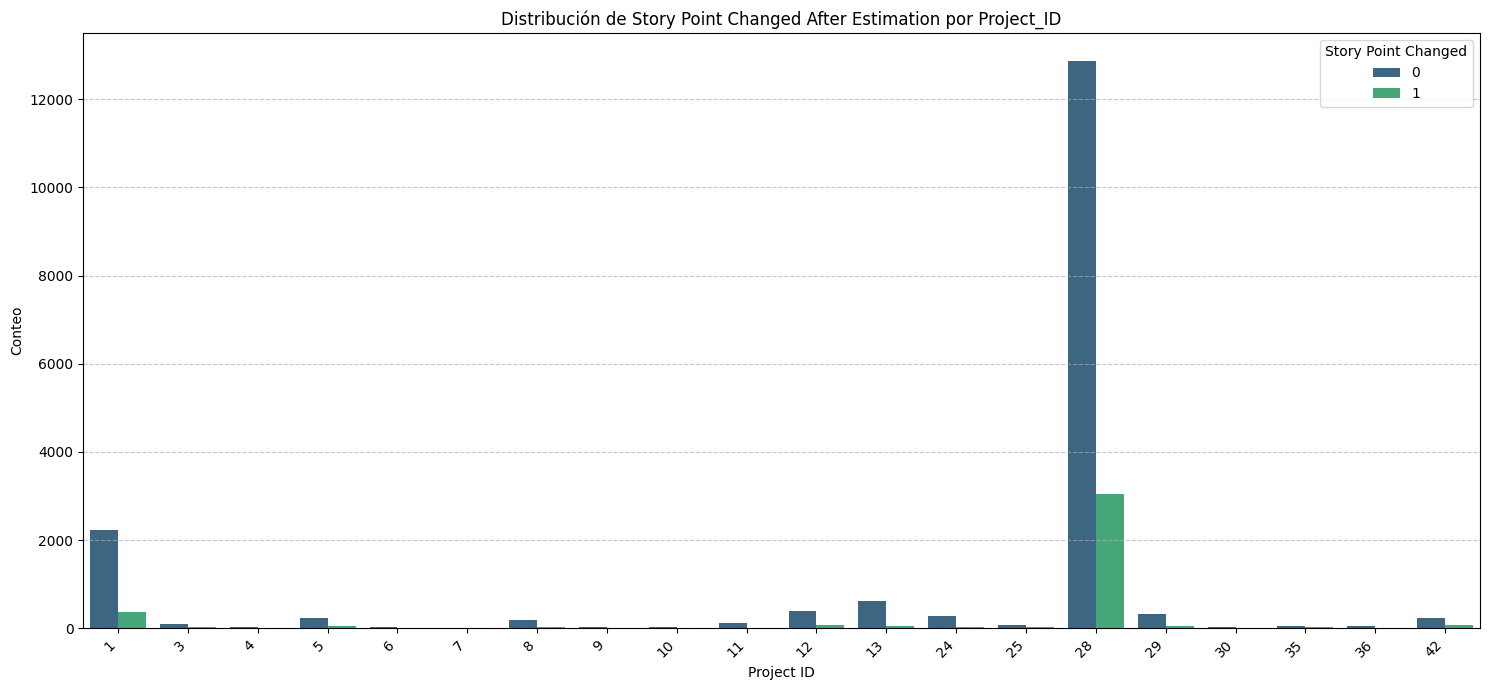

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns


plt.figure(figsize=(15, 7))

sns.countplot(data=df, x='Project_ID', hue='Story_Point_Changed_After_Estimation', palette='viridis')

plt.title('Distribución de Story Point Changed After Estimation por Project_ID')
plt.xlabel('Project ID')
plt.ylabel('Conteo')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Story Point Changed')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


Generando gráficos individuales de distribución de 'Story_Point_Changed_After_Estimation' por cada 'Project_ID'...


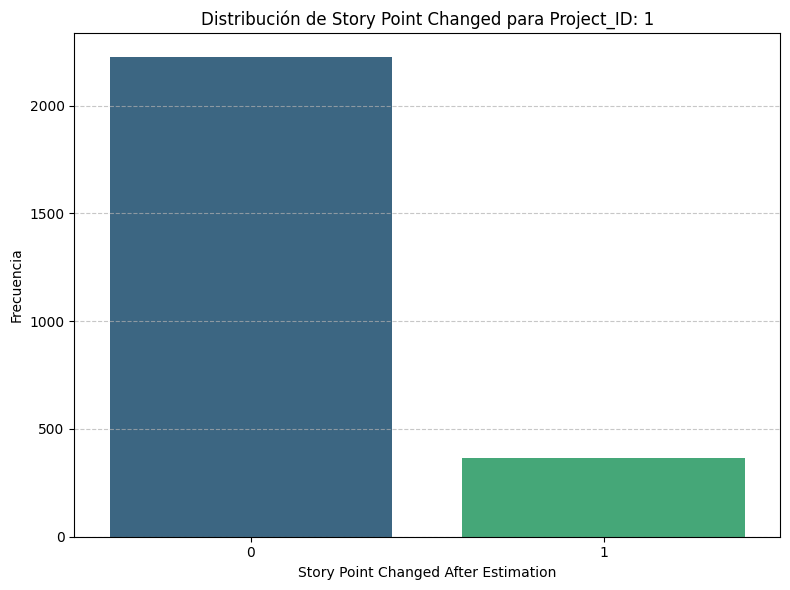

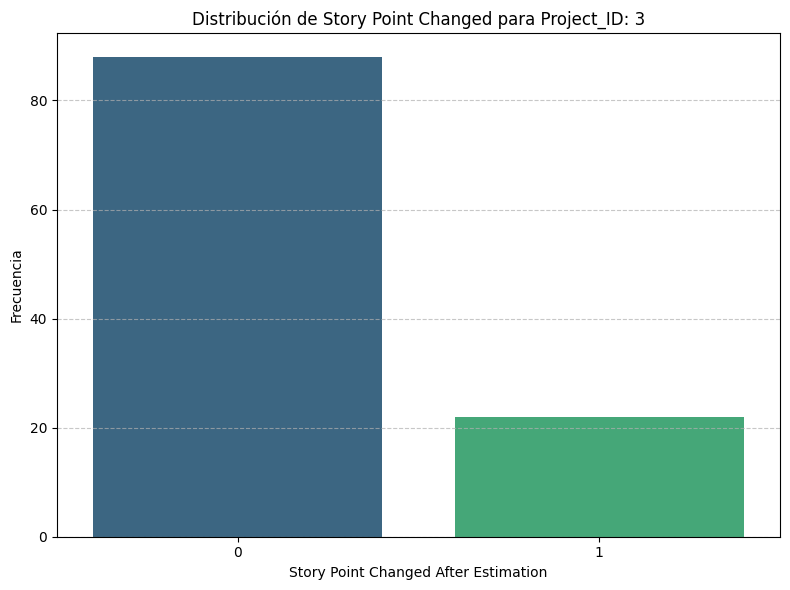

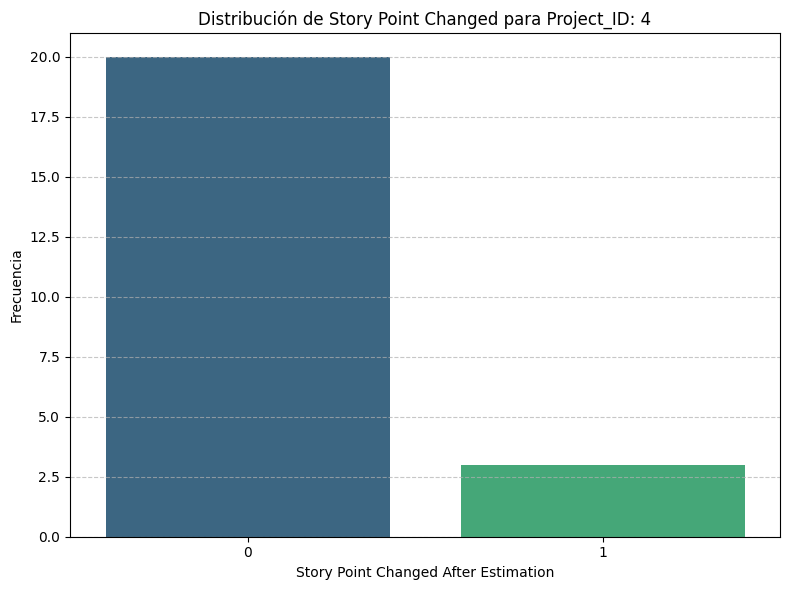

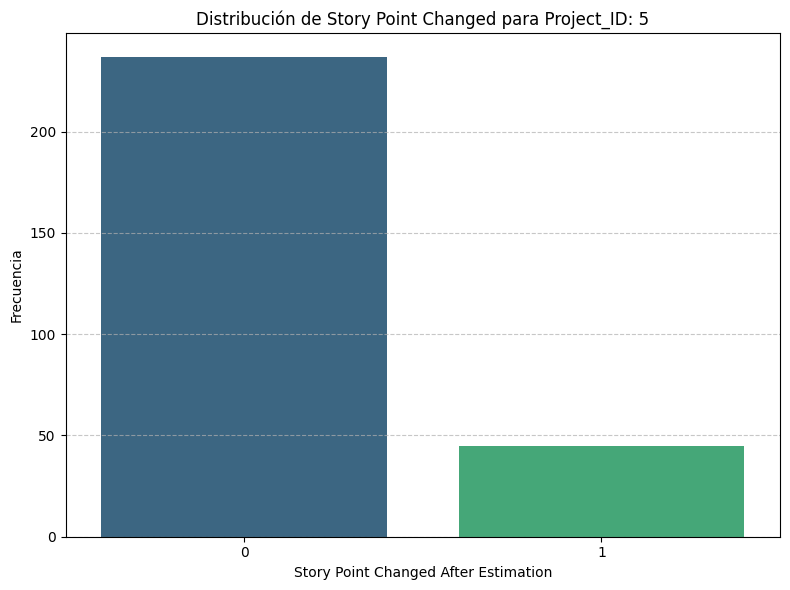

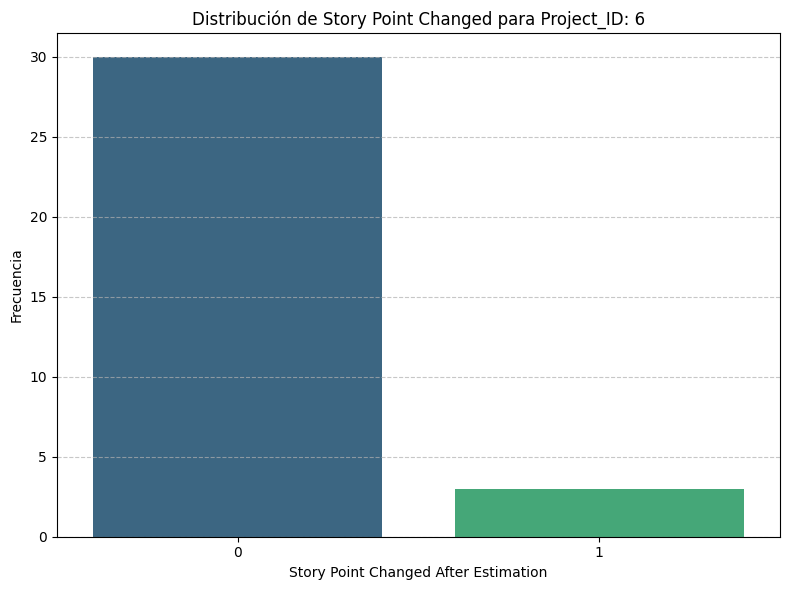

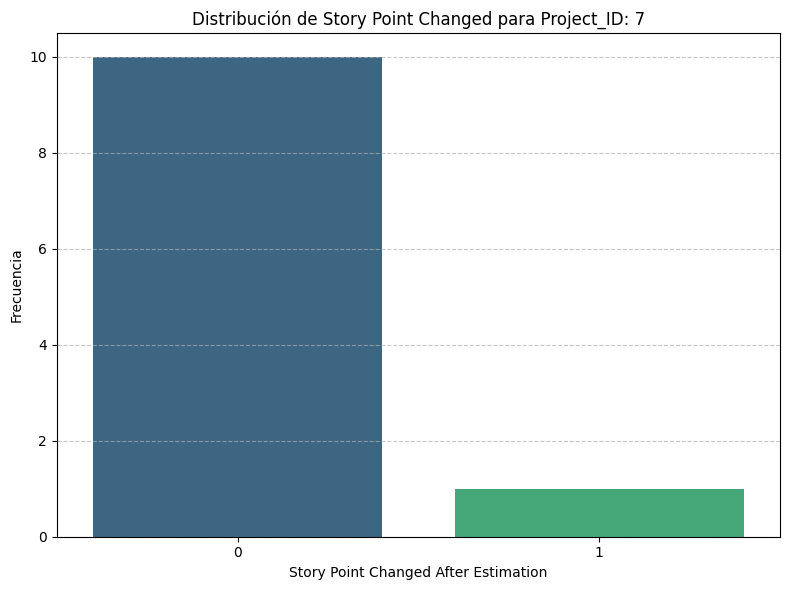

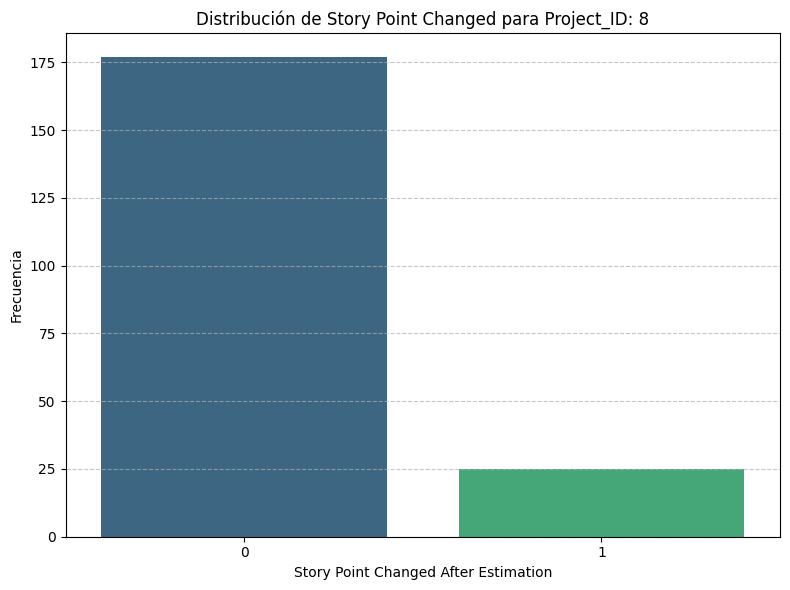

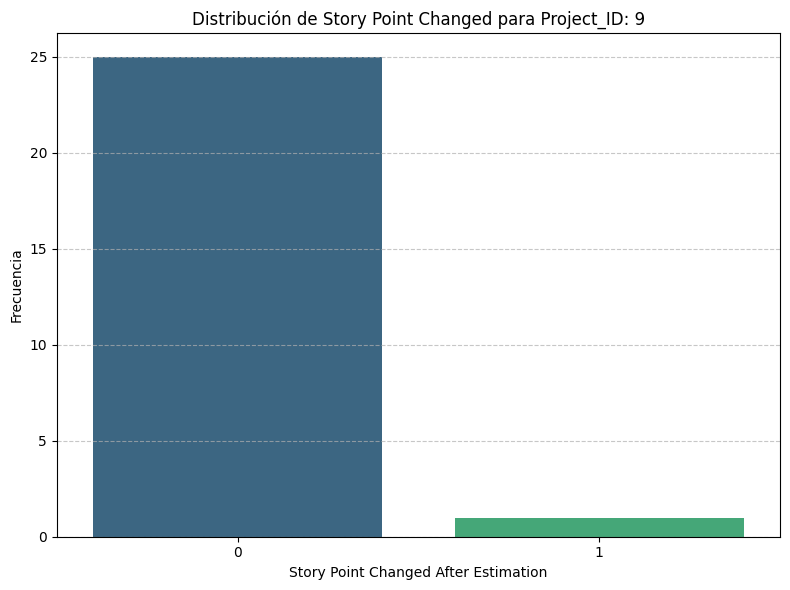

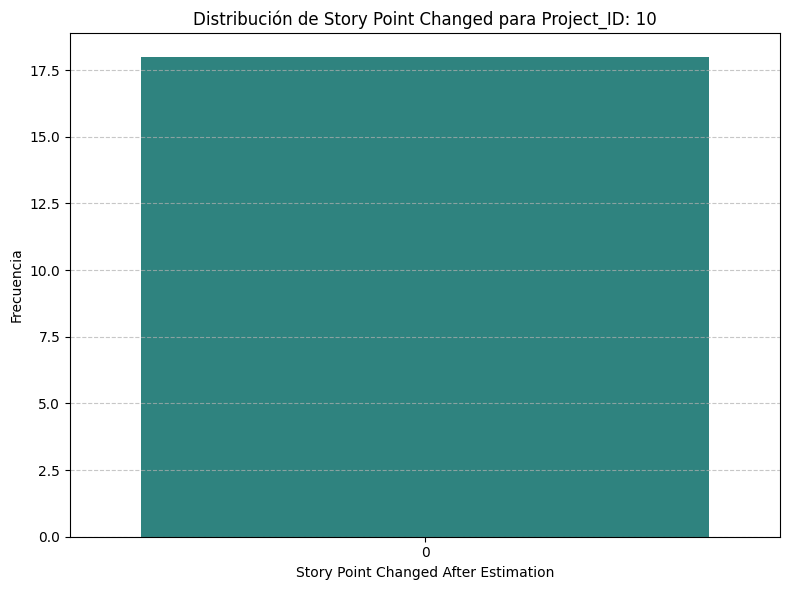

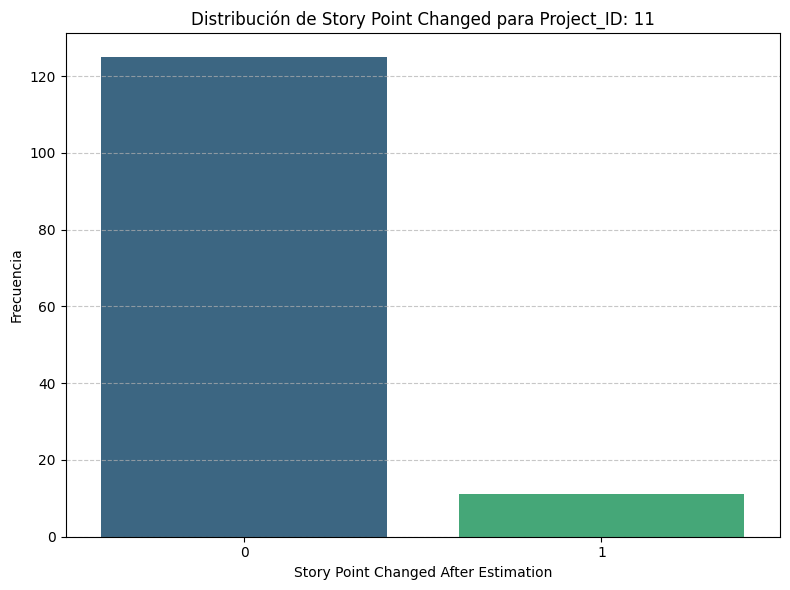

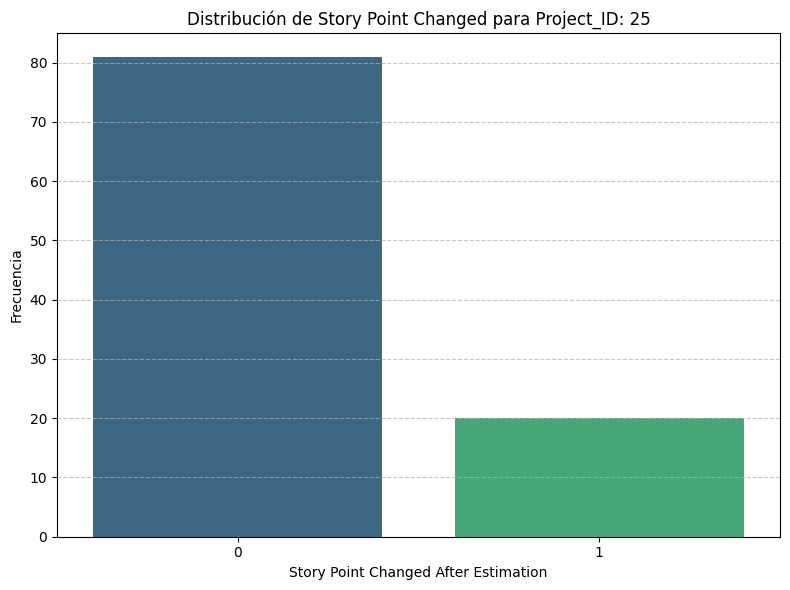

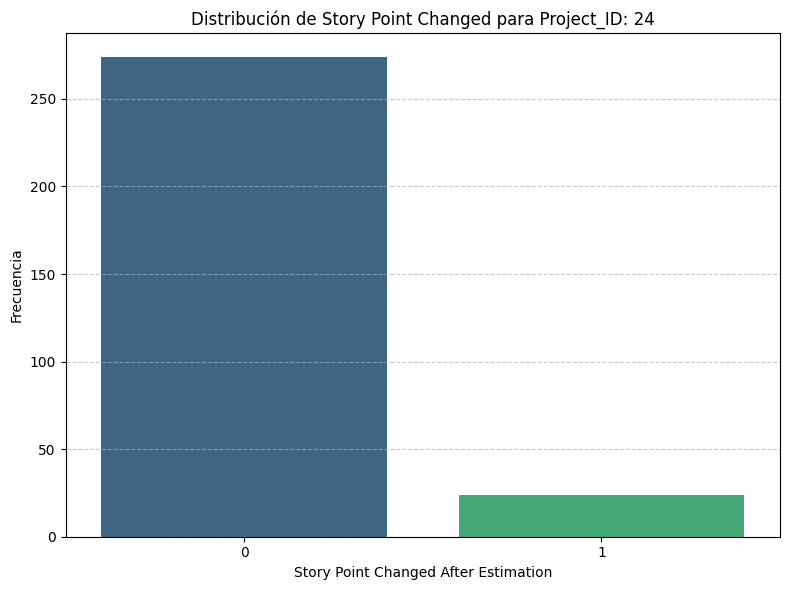

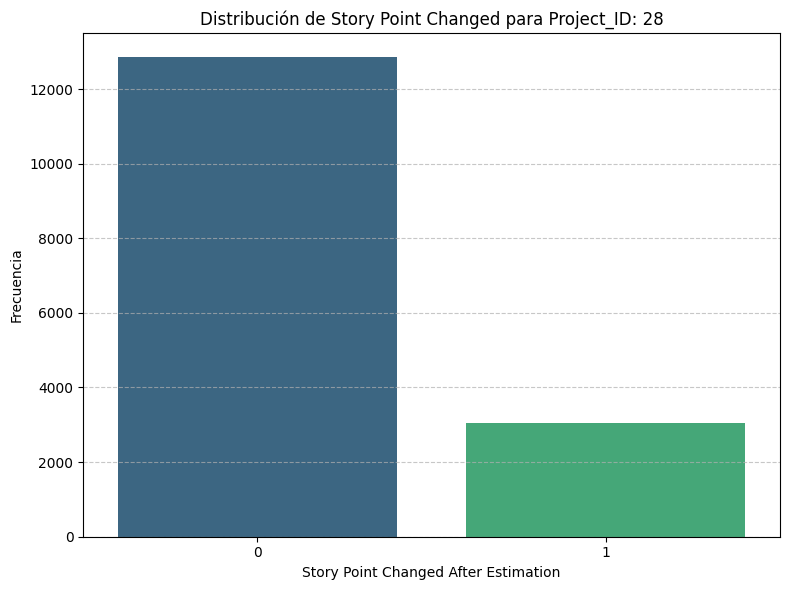

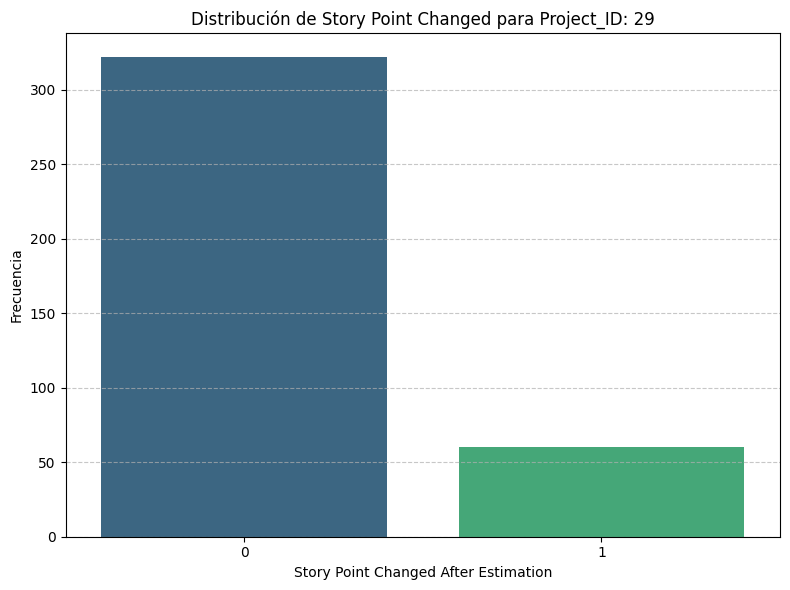

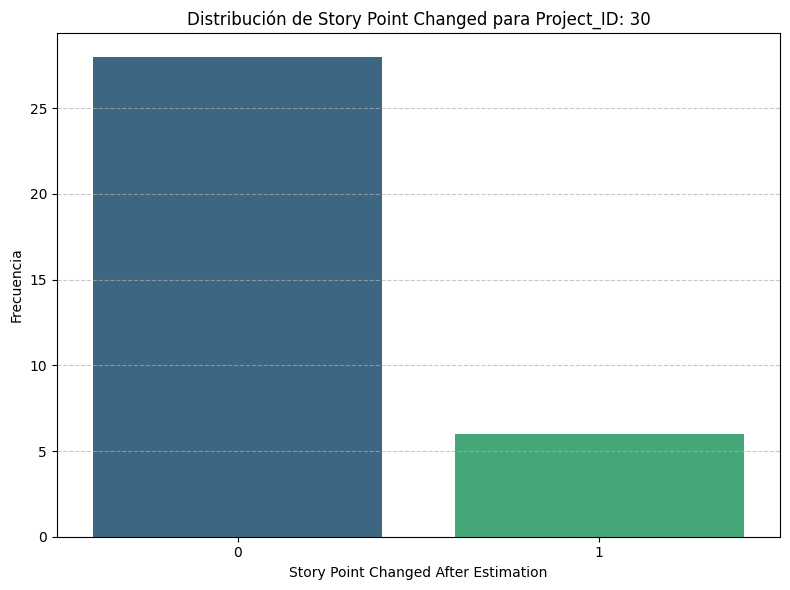

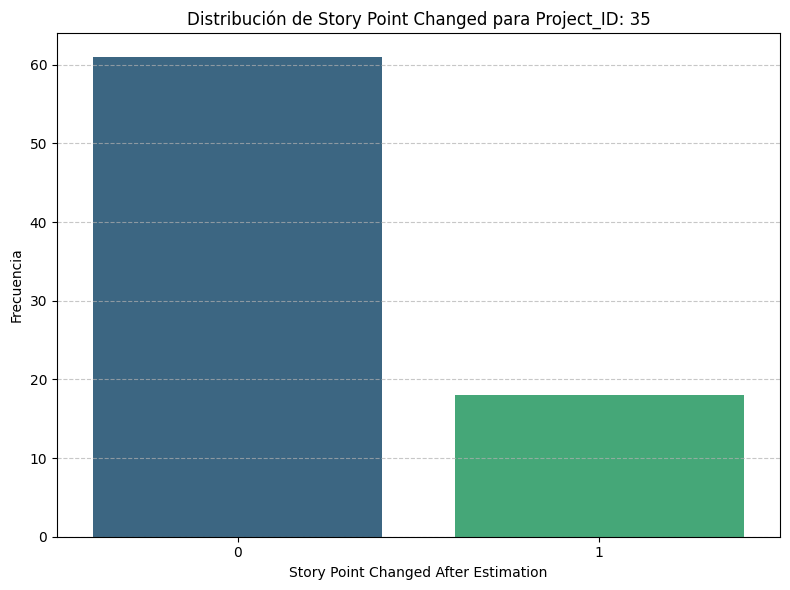

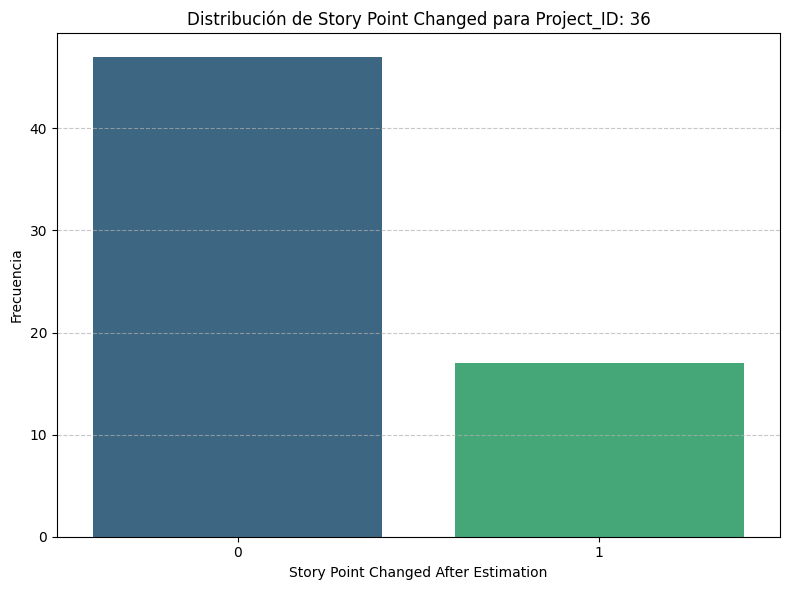

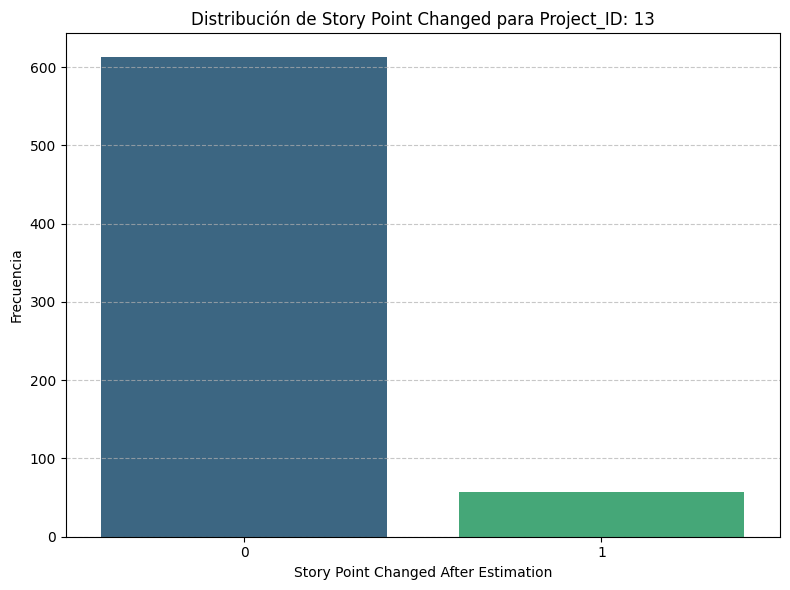

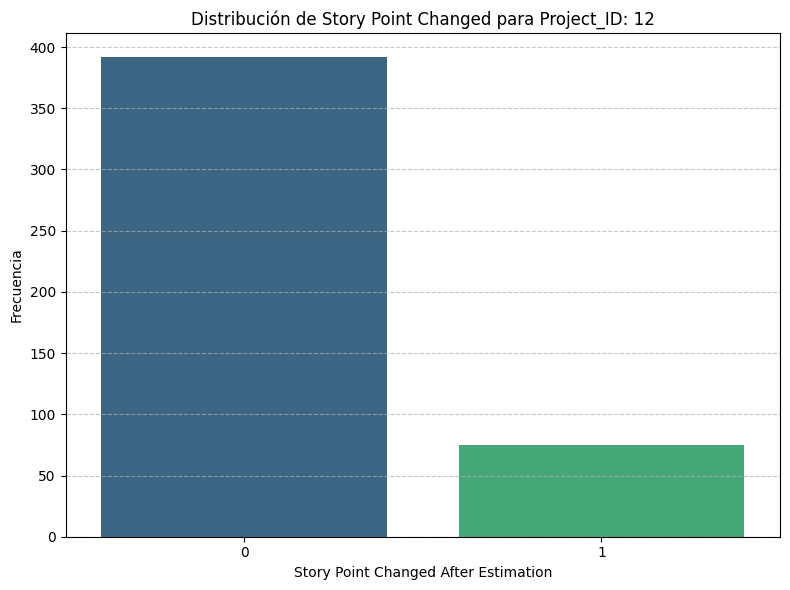

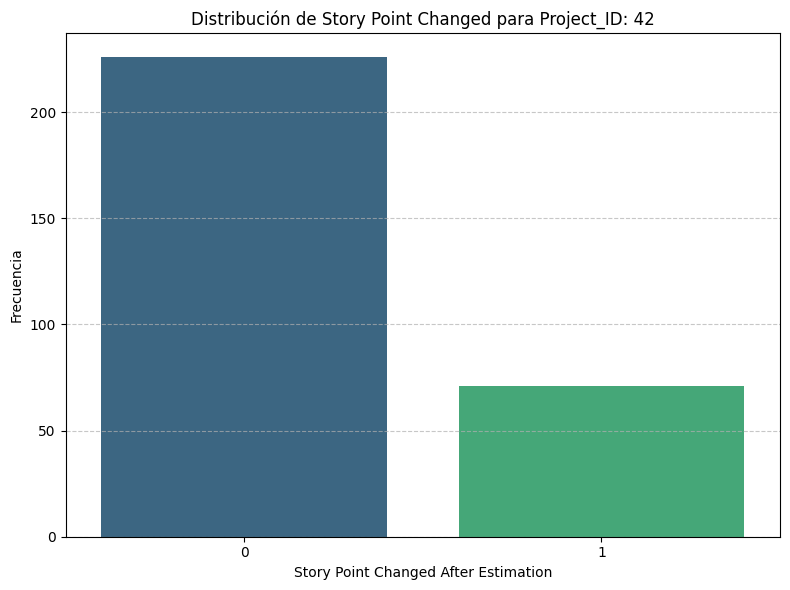

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

print("Generando gráficos individuales de distribución de 'Story_Point_Changed_After_Estimation' por cada 'Project_ID'...")

unique_project_ids = df['Project_ID'].unique()

for project_id in unique_project_ids:
    subset_df = df[df['Project_ID'] == project_id]

    if not subset_df.empty:
        plt.figure(figsize=(8, 6))
        # Use hue and legend=False to comply with future seaborn updates
        sns.countplot(x='Story_Point_Changed_After_Estimation', data=subset_df, palette='viridis', hue='Story_Point_Changed_After_Estimation', legend=False)
        plt.title(f'Distribución de Story Point Changed para Project_ID: {project_id}')
        plt.xlabel('Story Point Changed After Estimation')
        plt.ylabel('Frecuencia')
        plt.grid(axis='y', linestyle='--', alpha=0.7)
        plt.tight_layout()
        plt.show()
    else:
        print(f"No hay datos para Project_ID: {project_id}")



In [ ]:
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency

variables = ['Creator_ID', 'Reporter_ID', 'Assignee_ID', 'Priority', 'Components_Lista', 'Project_ID']
target = 'Story_Point_Changed_After_Estimation'

# Asegurar que existan en el df
variables_validas = [col for col in variables if col in df.columns]

resultados_cramer = []

for col in variables_validas:
  # Imputar nulos con una categoría constante para mantener la consistencia del análisis anterior
  temp_series = df[col].fillna('No especificado/Nulo').astype(str)

  # Crear tabla de contingencia
  tabla_contingencia = pd.crosstab(temp_series, df[target])

  # Calcular Chi-cuadrado
  chi2, p_val, dof, expected = chi2_contingency(tabla_contingencia)

  # Calcular V de Cramér
  n = tabla_contingencia.sum().sum()
  r, c = tabla_contingencia.shape
  v_cramer = np.sqrt(chi2 / (n * min(r - 1, c - 1)))

  resultados_cramer.append({
            'Variable': col,
            'Chi2 Stat': chi2,
            'p-valor': p_val,
            'V de Cramér': v_cramer
  })

  df_cramer = pd.DataFrame(resultados_cramer).sort_values(by='V de Cramér', ascending=False)

  print("--- ASOCIACIÓN CON V DE CRAMÉR RESPECTO AL TARGET ---")
  display(df_cramer)


--- ASOCIACIÓN CON V DE CRAMÉR RESPECTO AL TARGET ---


,Variable,Chi2 Stat,p-valor,V de Cramér
0,Creator_ID,1992.283744,1.270023e-146,0.302772


--- ASOCIACIÓN CON V DE CRAMÉR RESPECTO AL TARGET ---


,Variable,Chi2 Stat,p-valor,V de Cramér
0,Creator_ID,1992.283744,1.270023e-146,0.302772
1,Reporter_ID,1953.912786,4.028714e-142,0.299842


--- ASOCIACIÓN CON V DE CRAMÉR RESPECTO AL TARGET ---


...

,Variable,Chi2 Stat,p-valor,V de Cramér
0,Creator_ID,1992.283744,1.270023e-146,0.302772
1,Reporter_ID,1953.912786,4.028714e-142,0.299842
2,Assignee_ID,1788.677892,1.075703e-146,0.286884
3,Priority,92.386773,1.701075e-14,0.065200


--- ASOCIACIÓN CON V DE CRAMÉR RESPECTO AL TARGET ---


,Variable,Chi2 Stat,p-valor,V de Cramér
0,Creator_ID,1992.283744,1.270023e-146,0.302772
1,Reporter_ID,1953.912786,4.028714e-142,0.299842
4,Components_Lista,1848.669511,4.998723e-34,0.291655
2,Assignee_ID,1788.677892,1.075703e-146,0.286884
3,Priority,92.386773,1.701075e-14,0.065200


--- ASOCIACIÓN CON V DE CRAMÉR RESPECTO AL TARGET ---


,Variable,Chi2 Stat,p-valor,V de Cramér
0,Creator_ID,1992.283744,1.270023e-146,0.302772
1,Reporter_ID,1953.912786,4.028714e-142,0.299842
4,Components_Lista,1848.669511,4.998723e-34,0.291655
2,Assignee_ID,1788.677892,1.075703e-146,0.286884
5,Project_ID,140.885492,1.235997e-20,0.080514
3,Priority,92.386773,1.701075e-14,0.065200


--- ANÁLISIS DE CORRELACIÓN ENTRE STORY POINT ORIGINAL Y VARIABLE OBJETIVO ---

Estadísticas descriptivas de Story Point Original agrupado por la variable objetivo:


,count,mean,std,min,25%,50%,75%,max
Story_Point_Changed_After_Estimation,,,,,,,,
0,17863.0,4.033674,8.966969,0.0,1.0000,2.8,5.0,1010.0
1,3870.0,6.337443,23.039817,-1.0,1.7625,3.0,6.0,1000.0



Coeficiente de Correlación de Punto Biseriado: 0.0694
p-valor: 1.3096e-24
Existe una relación estadísticamente significativa (p < 0.05).


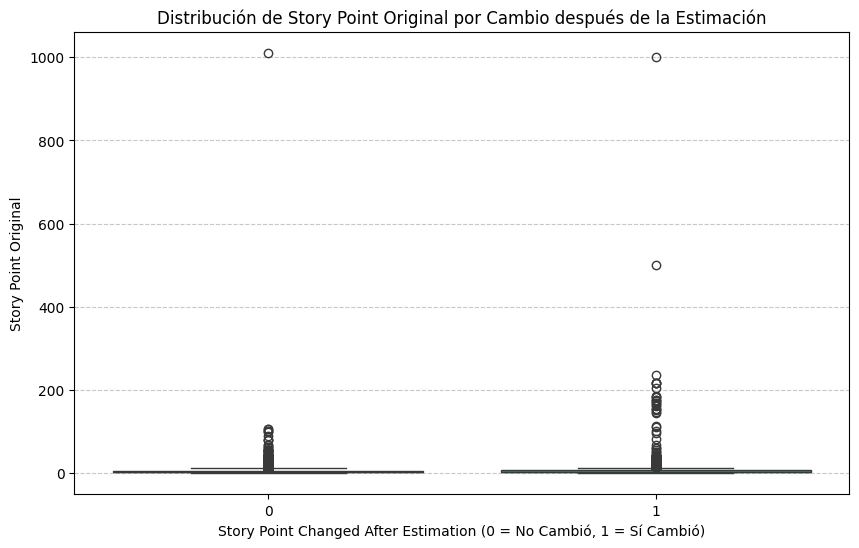

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

col_sp = 'Story_Point_Original'
col_target = 'Story_Point_Changed_After_Estimation'

print("--- ANÁLISIS DE CORRELACIÓN ENTRE STORY POINT ORIGINAL Y VARIABLE OBJETIVO ---\n")

# 1. Estadísticas descriptivas agrupadas
stats_grouped = df.groupby(col_target)[col_sp].describe()
print("Estadísticas descriptivas de Story Point Original agrupado por la variable objetivo:")
display(stats_grouped)

# 2. Correlación de Punto Biseriado
# Eliminamos nulos temporalmente en caso de que existan en estas columnas
df_clean = df[[col_sp, col_target]].dropna()

correlation, p_value = stats.pointbiserialr(df_clean[col_sp], df_clean[col_target])
print(f"\nCoeficiente de Correlación de Punto Biseriado: {correlation:.4f}")
print(f"p-valor: {p_value:.4e}")

# Interpretación
if p_value < 0.05:
  print("Existe una relación estadísticamente significativa (p < 0.05).")
else:
  print("No existe evidencia de una relación estadísticamente significativa (p >= 0.05).")

# 3. Visualización de la distribución
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_clean, x=col_target, y=col_sp, palette='viridis', hue=col_target, legend=False)
plt.title('Distribución de Story Point Original por Cambio después de la Estimación')
plt.xlabel('Story Point Changed After Estimation (0 = No Cambió, 1 = Sí Cambió)')
plt.ylabel('Story Point Original')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


In [ ]:
columns_to_keep = [
        'Title_Estimacion_Inicial',
        'Description_Estimacion_Inicial',
        'Priority',
        'Story_Point_Original',
        'Story_Point_Changed_After_Estimation',
        'Components_Lista',
        'Cantidad_Comentarios_Previos',
        'Cantidad_Components',
        'Project_ID'
    ]
# Filter the DataFrame to keep only the specified columns
df = df[columns_to_keep]
print(f"El DataFrame ahora contiene solo las siguientes columnas: {columns_to_keep}")
print("Primeras 5 filas del DataFrame con las columnas seleccionadas:")
display(df.head())
print("Información del DataFrame actualizado:")
df.info()


El DataFrame ahora contiene solo las siguientes columnas: ['Title_Estimacion_Inicial', 'Description_Estimacion_Inicial', 'Priority', 'Story_Point_Original', 'Story_Point_Changed_After_Estimation', 'Components_Lista', 'Cantidad_Comentarios_Previos', 'Cantidad_Components', 'Project_ID']
Primeras 5 filas del DataFrame con las columnas seleccionadas:


,Title_Estimacion_Inicial,Description_Estimacion_Inicial,Priority,Story_Point_Original,Story_Point_Changed_After_Estimation,Components_Lista,Cantidad_Comentarios_Previos,Cantidad_Components,Project_ID
0,Fix stream failover on YARN,"""""""See https://github.com/spring-projects/spri...",Minor,8.0,0,NaN,0,0,1
1,"""wordcount failed to run in cloudera VM 5.7""","""""""I download the spring XD example projects, ...",Blocker,3.0,0,NaN,0,0,1
2,"""Add Job RDBMS config in Ambari plugin""","""""""Spring XD Ambari plugin only supports HDB a...",Minor,2.0,0,UI,0,1,1
3,Move K8s SPI to a separate repo,"""""""As a developer, I'd like to move k8s SPI to...",Minor,5.0,0,NaN,0,0,1
4,"""Upgrade XD Ambari release to 1.3 ""","""""""As a developer, I'd like to upgrade Spring ...",Minor,3.0,0,NaN,0,0,1


Información del DataFrame actualizado:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21733 entries, 0 to 21732
Data columns (total 9 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Title_Estimacion_Inicial              21733 non-null  object 
 1   Description_Estimacion_Inicial        18942 non-null  object 
 2   Priority                              5764 non-null   object 
 3   Story_Point_Original                  21733 non-null  float64
 4   Story_Point_Changed_After_Estimation  21733 non-null  int64  
 5   Components_Lista                      11298 non-null  object 
 6   Cantidad_Comentarios_Previos          21733 non-null  int64  
 7   Cantidad_Components                   21733 non-null  int64  
 8   Project_ID                            21733 non-null  int64  
dtypes: float64(1), int64(4), object(4)
memory usage: 1.5+ MB


Generando gráficos individuales de distribución de 'Priority' por cada 'Project_ID'...


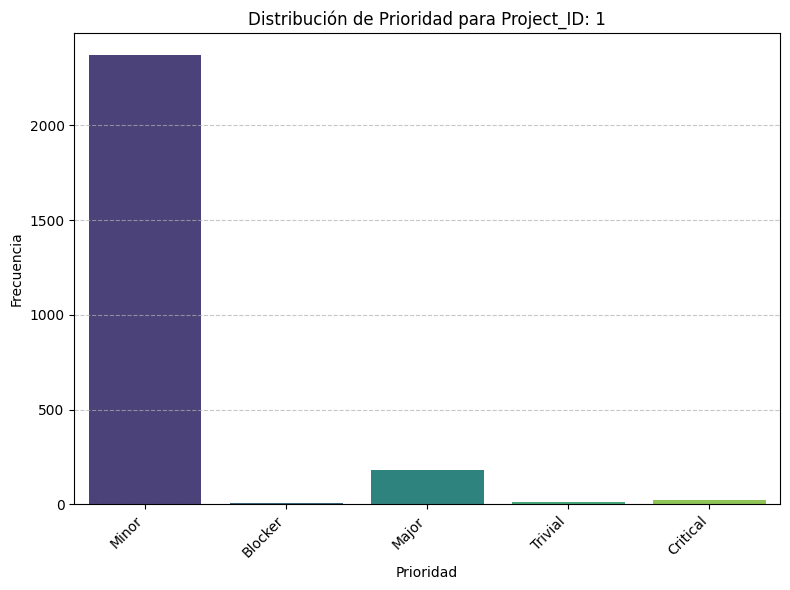

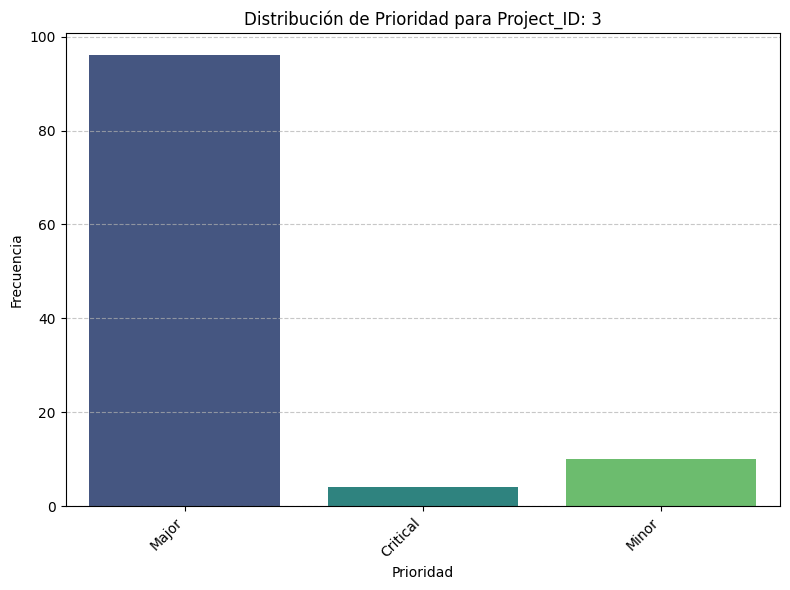

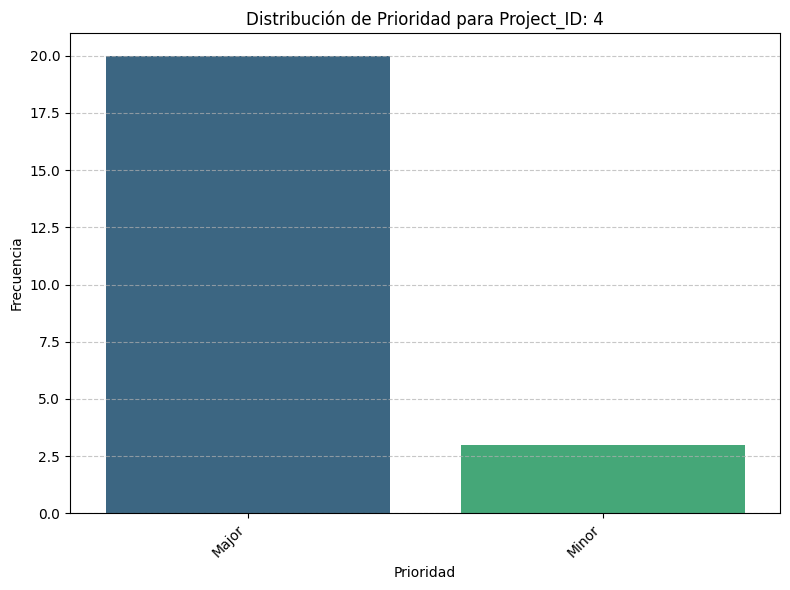

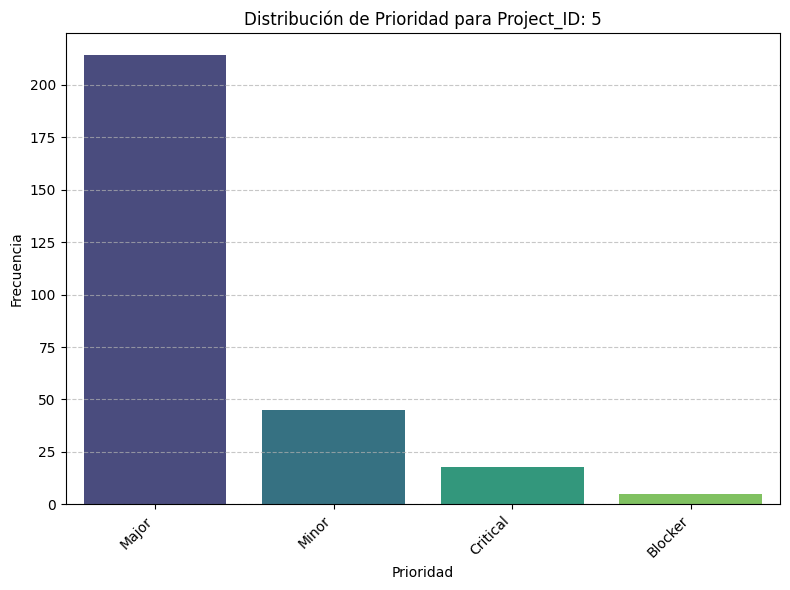

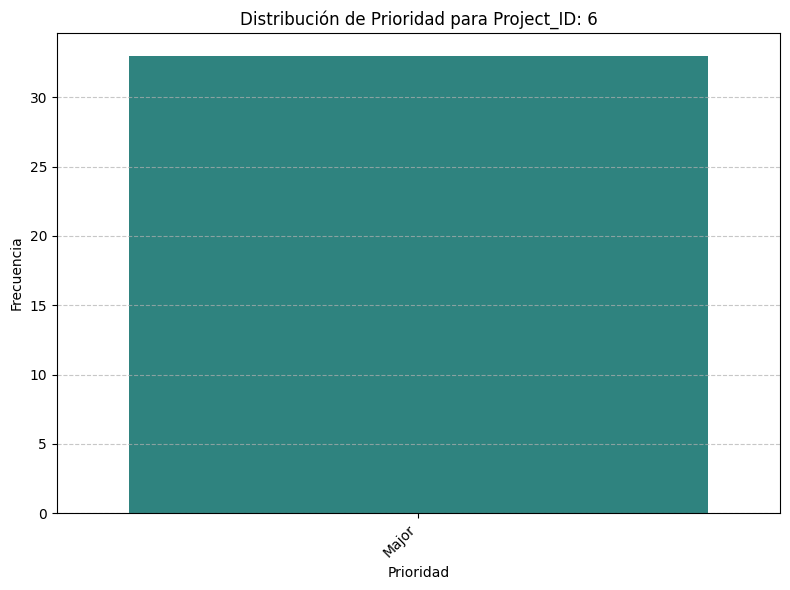

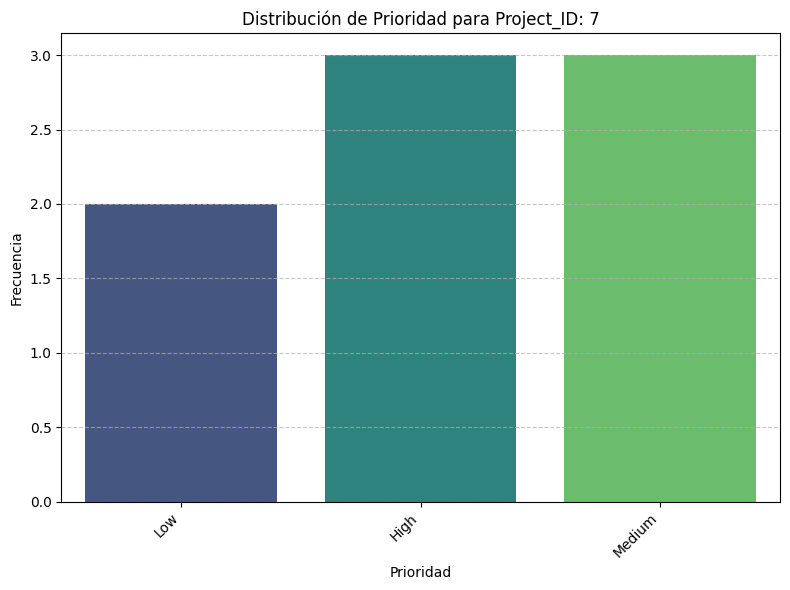

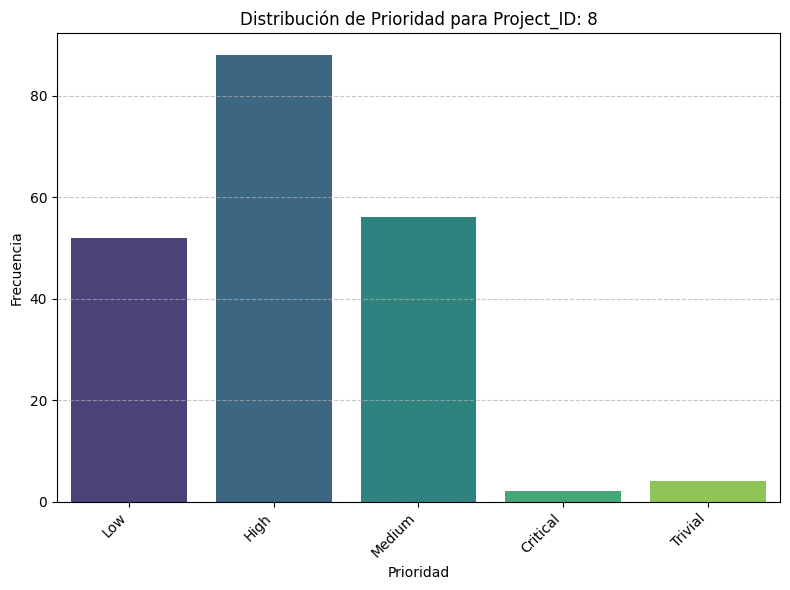

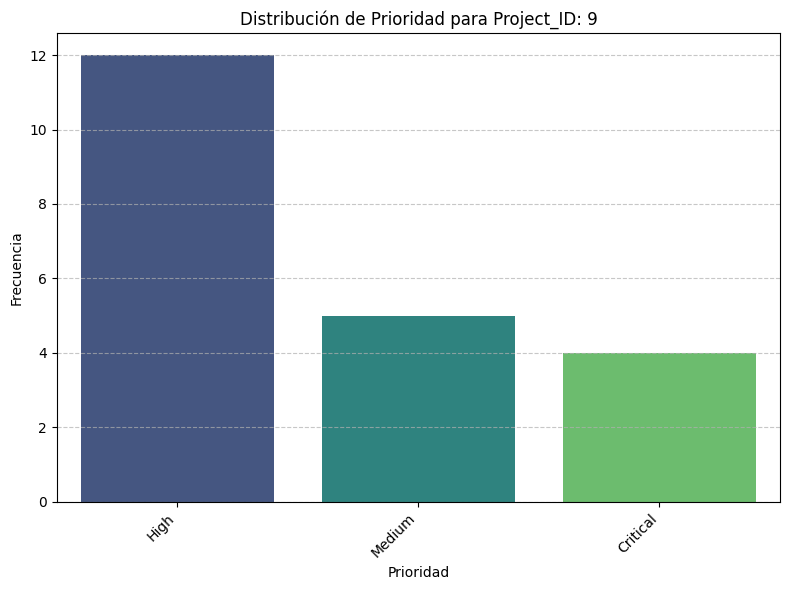

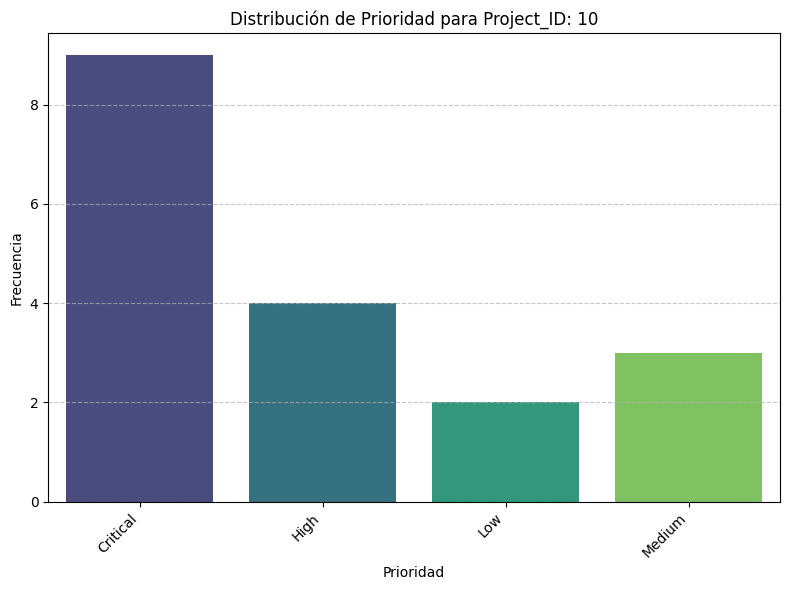

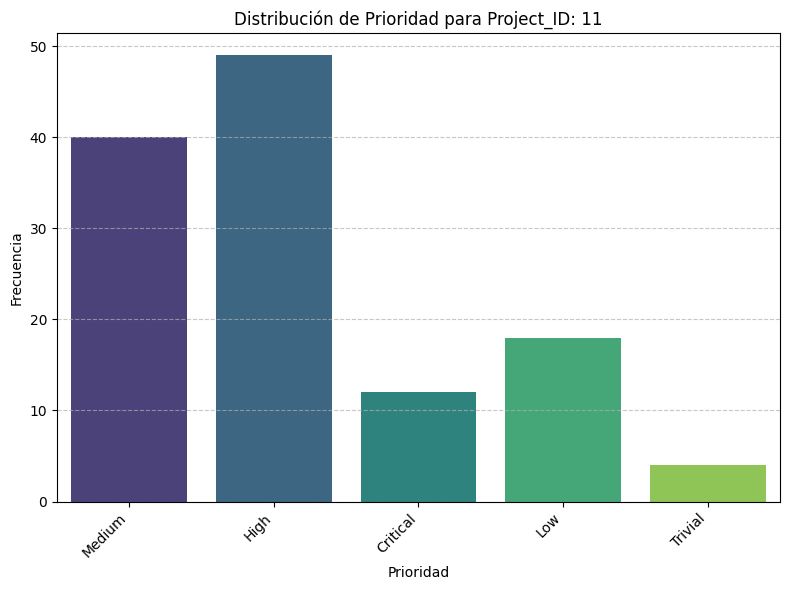

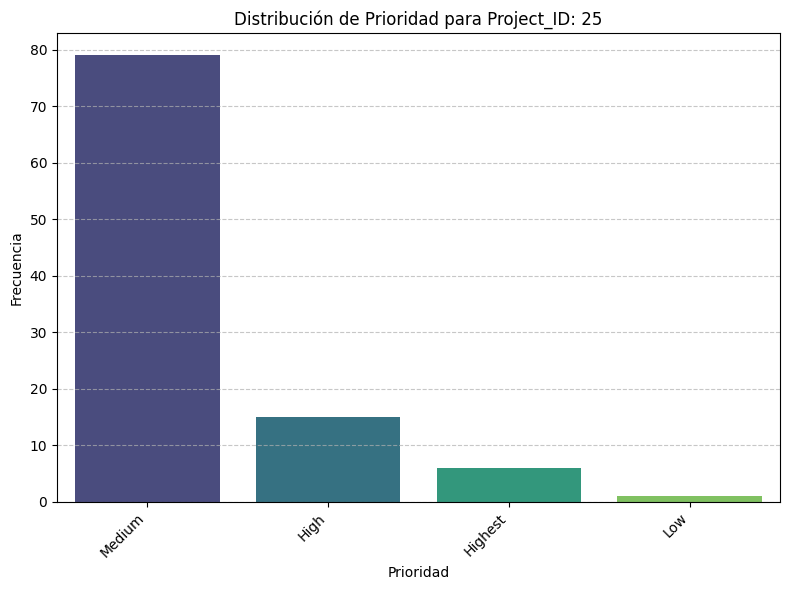

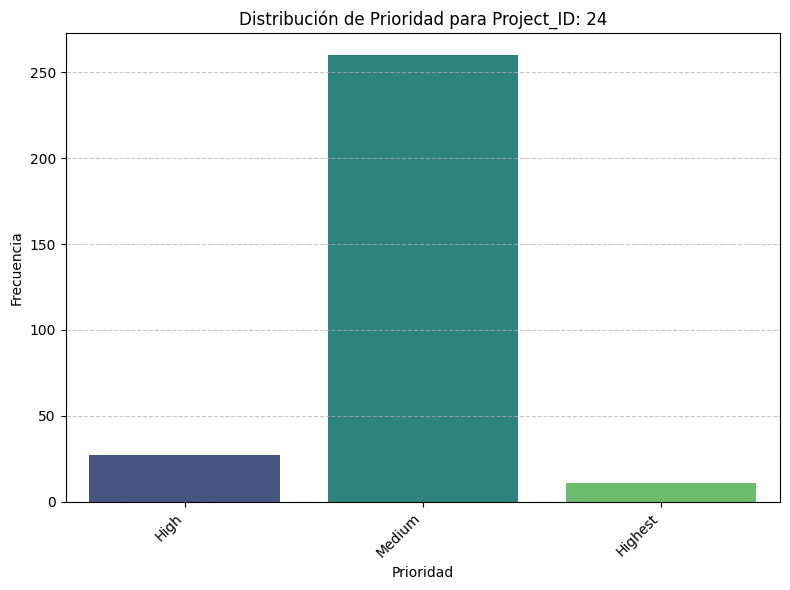

/tmp/ipykernel_5635/3746939273.py:11: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.countplot(x='Priority', data=subset_df, palette='viridis', hue='Priority', legend=False)


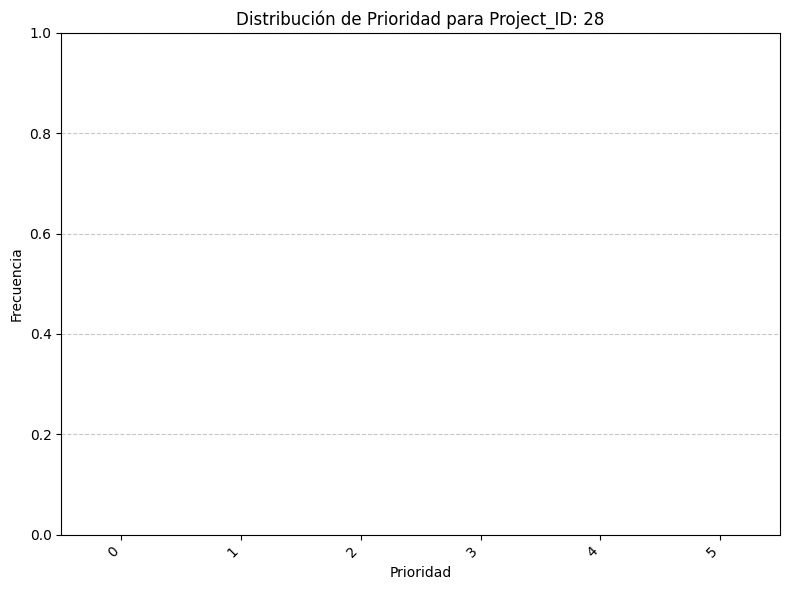

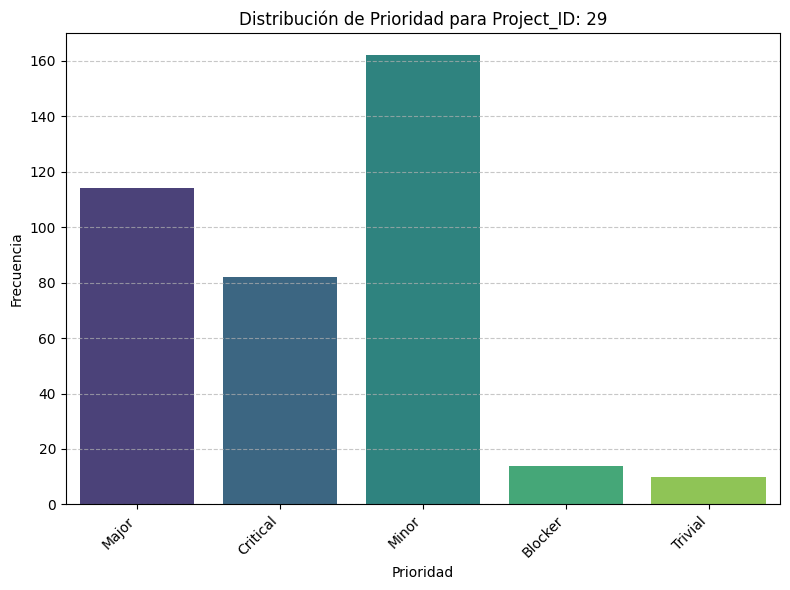

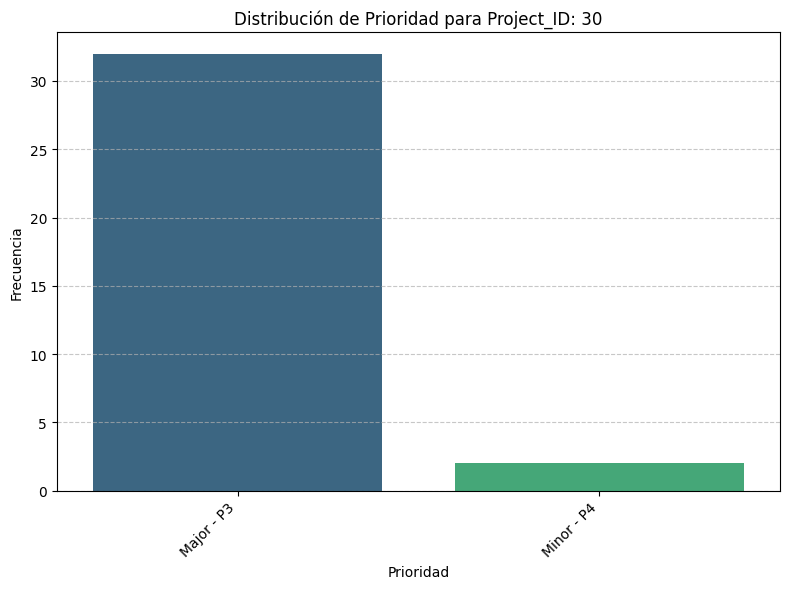

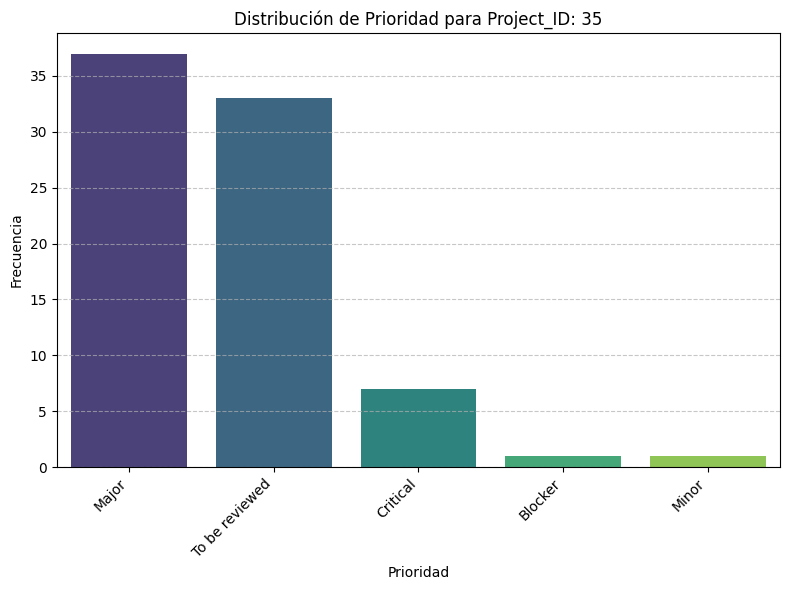

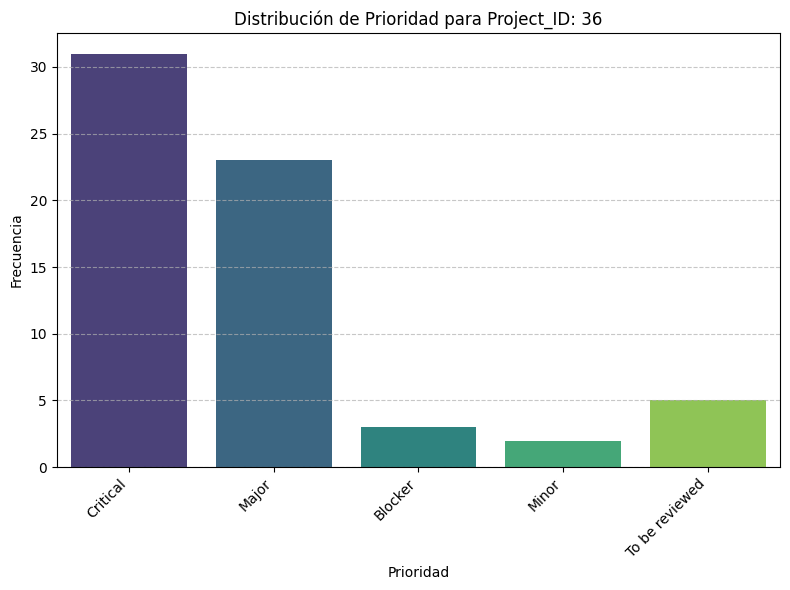

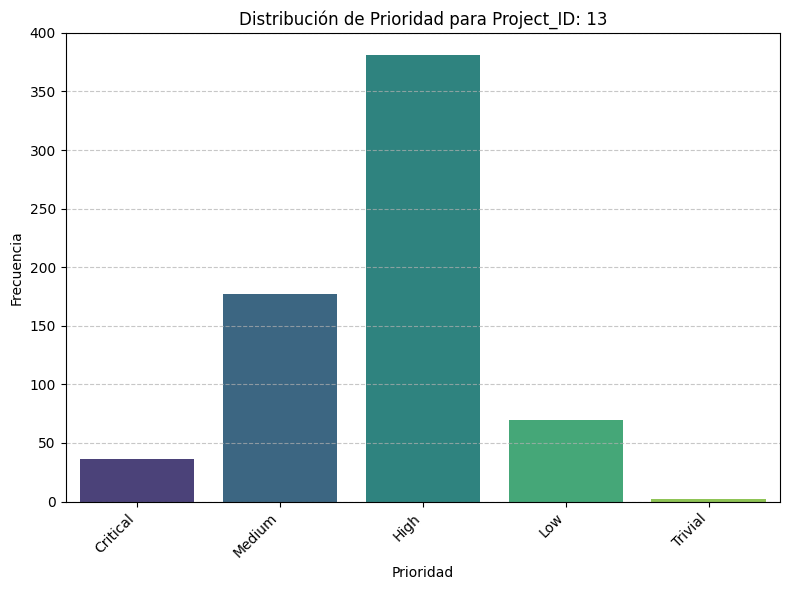

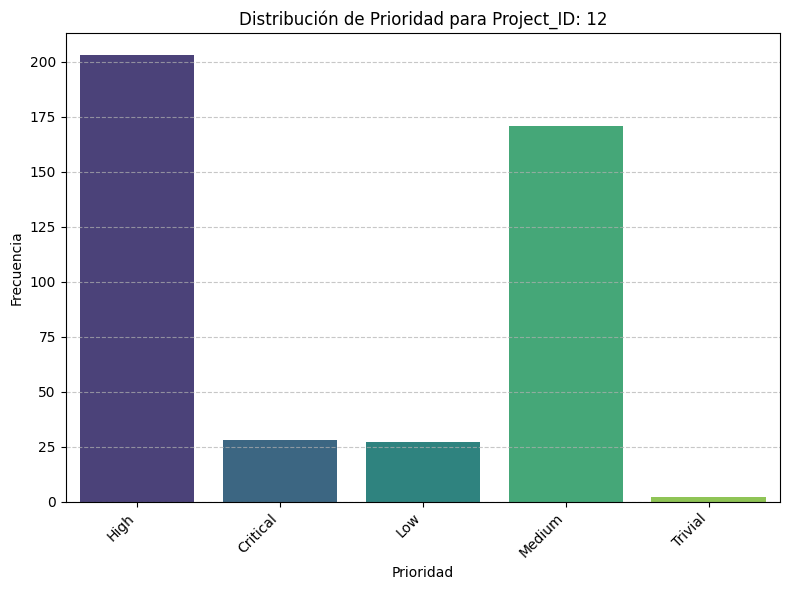

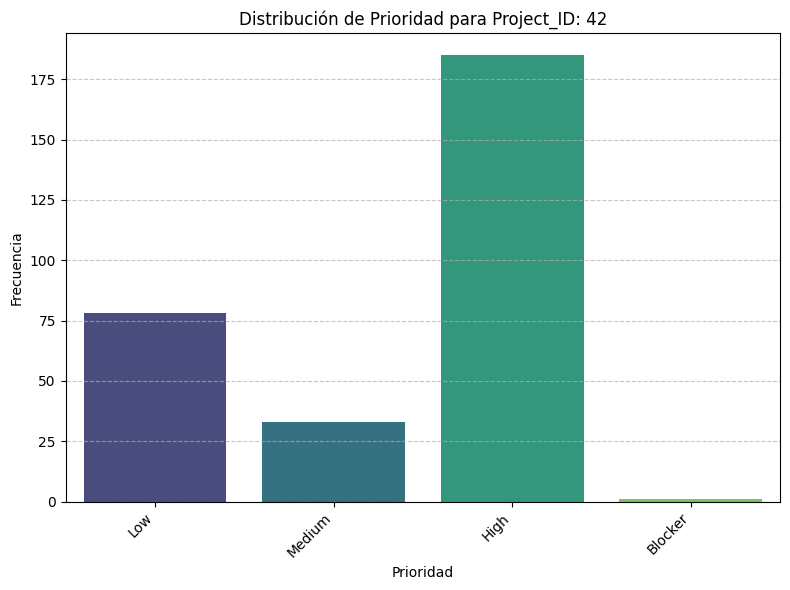

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
print("Generando gráficos individuales de distribución de 'Priority' por cada 'Project_ID'...")
unique_project_ids = df['Project_ID'].unique()

for project_id in unique_project_ids:
  subset_df = df[df['Project_ID'] == project_id]

  plt.figure(figsize=(8, 6))

  sns.countplot(x='Priority', data=subset_df, palette='viridis', hue='Priority', legend=False)
  plt.title(f'Distribución de Prioridad para Project_ID: {project_id}')
  plt.xlabel('Prioridad')
  plt.ylabel('Frecuencia')
  plt.xticks(rotation=45, ha='right')
  plt.grid(axis='y', linestyle='--', alpha=0.7)
  plt.tight_layout()
  plt.show()

In [ ]:
print("Consolidando 'Major - P3' en 'Major' y 'Minor - P4' en 'Minor' en la columna 'Priority'...")
# Replace 'Major - P3' with 'Major' and 'Minor - P4' with 'Minor'
df['Priority'] = df['Priority'].replace({
            'Major - P3': 'Major',
            'Minor - P4': 'Minor'
})
print("Consolidación completada. Mostrando el conteo de valores actualizados de 'Priority':")
display(df['Priority'].value_counts(dropna=False))

Consolidando 'Major - P3' en 'Major' y 'Minor - P4' en 'Minor' en la columna 'Priority'...
Consolidación completada. Mostrando el conteo de valores actualizados de 'Priority':


,count
Priority,
NaN,15969
Minor,2594
High,967
Medium,827
Major,750
Critical,258
Low,250
To be reviewed,38
Trivial,33


Generando box plot de 'Cantidad_Comentarios_Previos' individualmente por cada 'Project_ID'...


/tmp/ipykernel_5635/2851333979.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Cantidad_Comentarios_Previos'], palette='viridis')


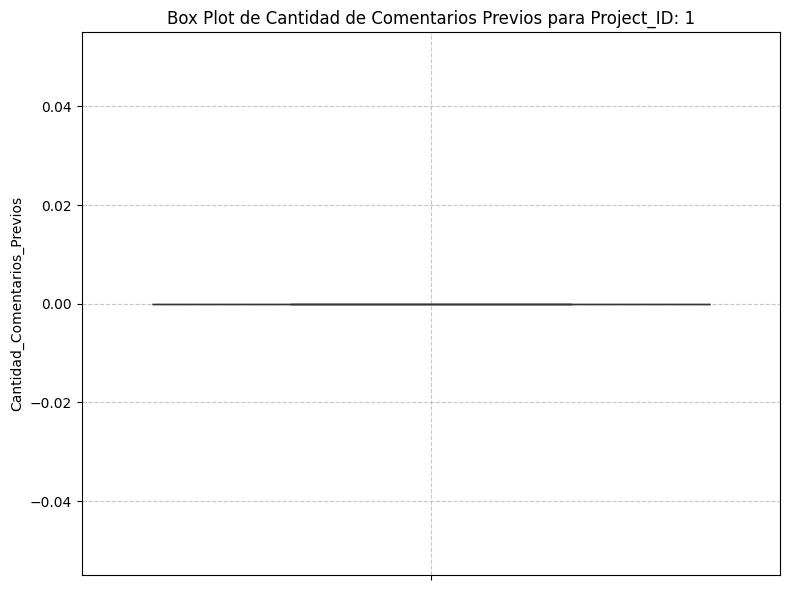

/tmp/ipykernel_5635/2851333979.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Cantidad_Comentarios_Previos'], palette='viridis')


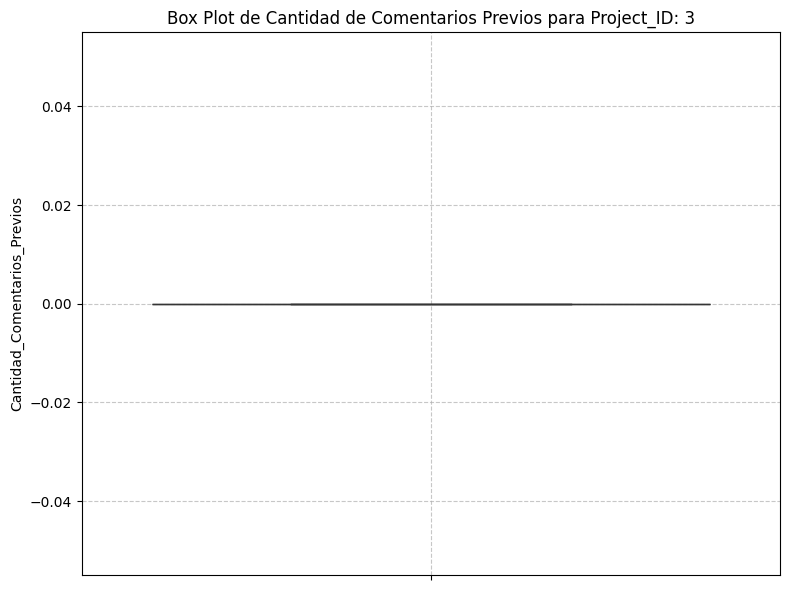

/tmp/ipykernel_5635/2851333979.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Cantidad_Comentarios_Previos'], palette='viridis')


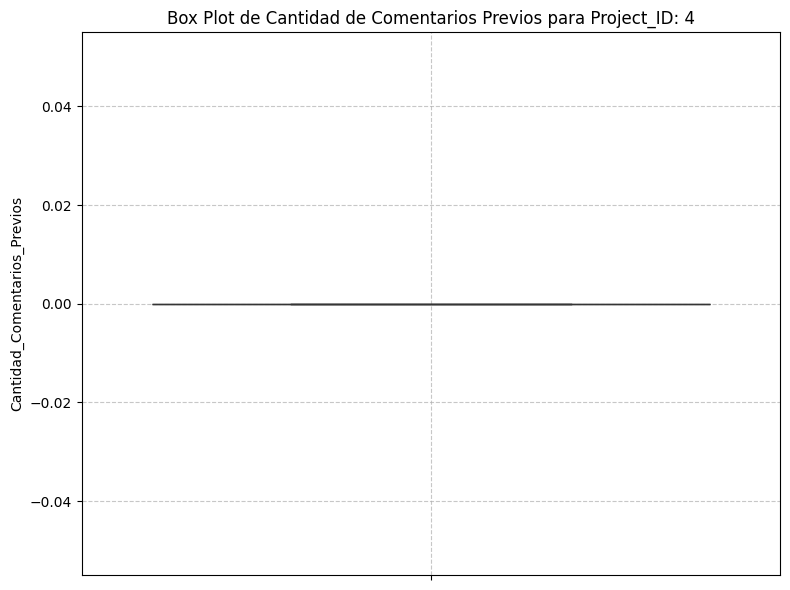

/tmp/ipykernel_5635/2851333979.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Cantidad_Comentarios_Previos'], palette='viridis')


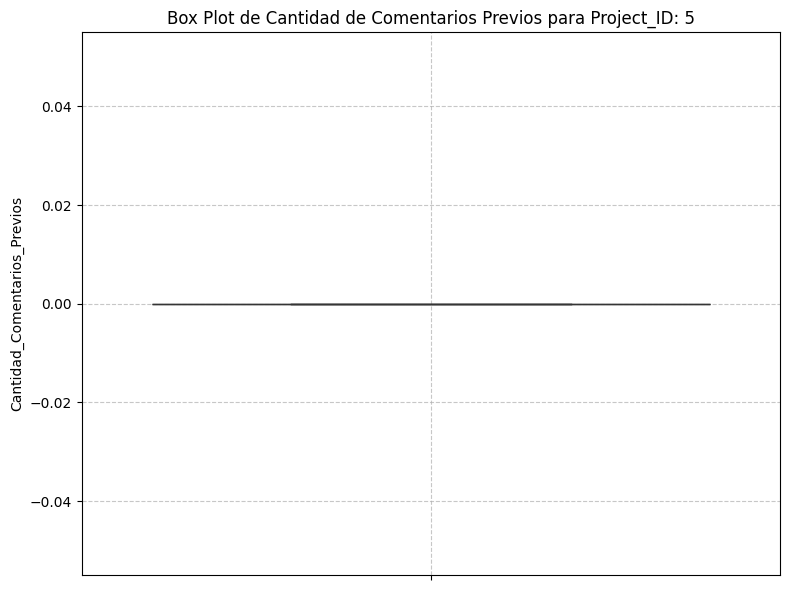

/tmp/ipykernel_5635/2851333979.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Cantidad_Comentarios_Previos'], palette='viridis')


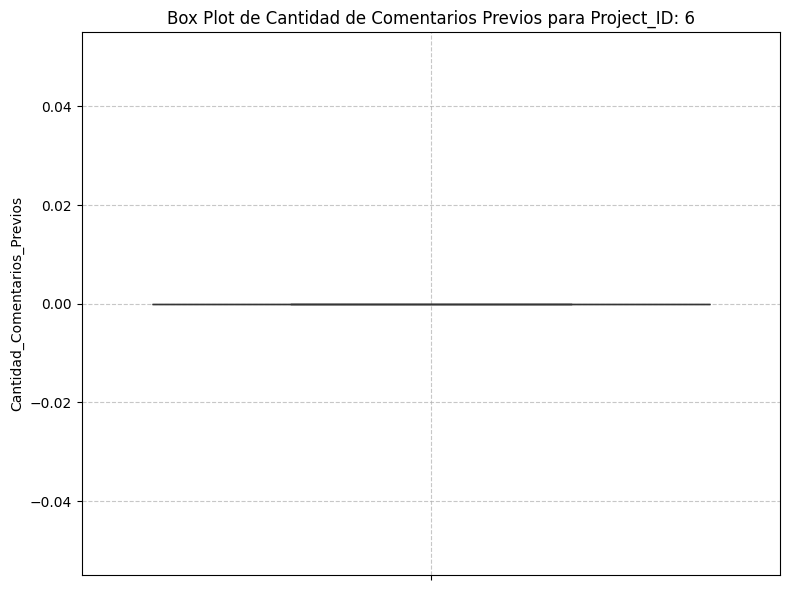

/tmp/ipykernel_5635/2851333979.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Cantidad_Comentarios_Previos'], palette='viridis')


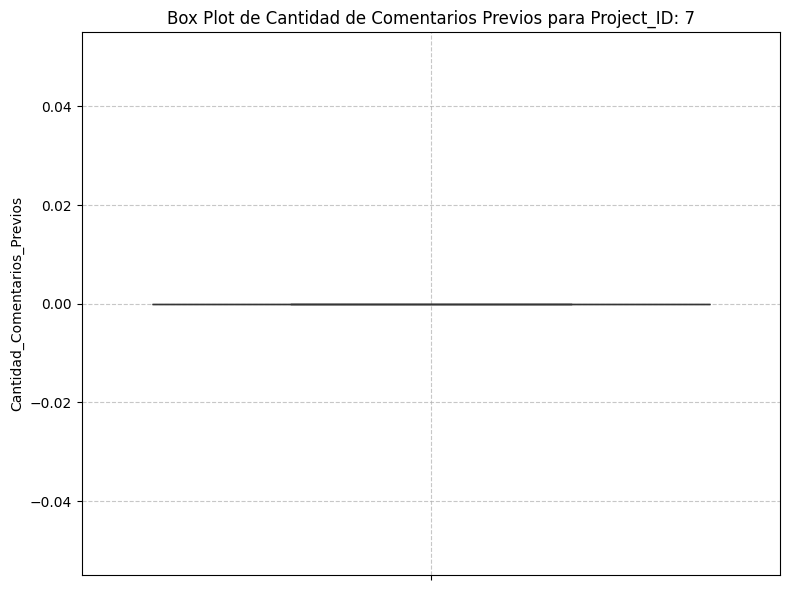

/tmp/ipykernel_5635/2851333979.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Cantidad_Comentarios_Previos'], palette='viridis')


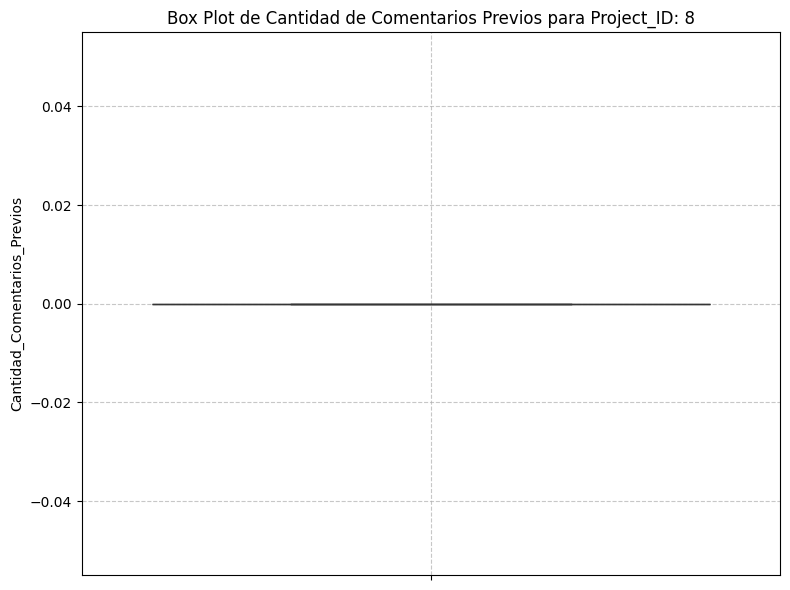

/tmp/ipykernel_5635/2851333979.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Cantidad_Comentarios_Previos'], palette='viridis')


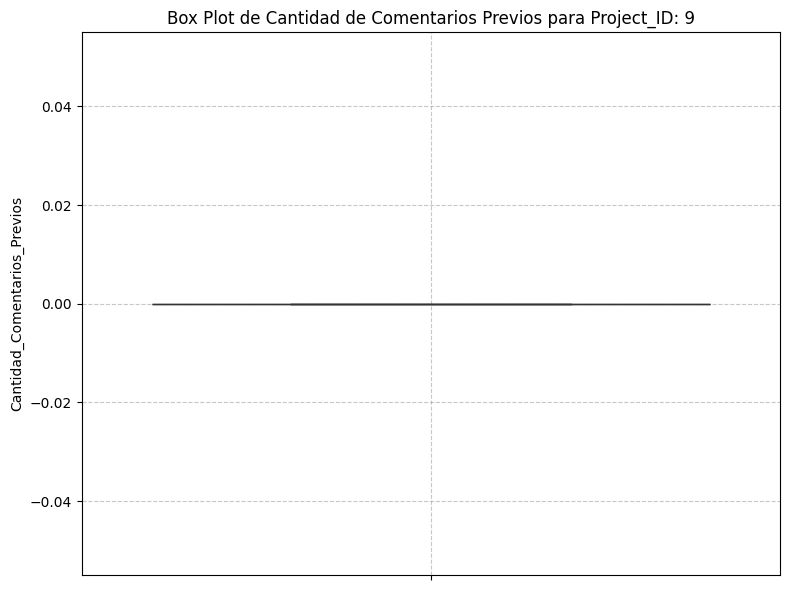

/tmp/ipykernel_5635/2851333979.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Cantidad_Comentarios_Previos'], palette='viridis')


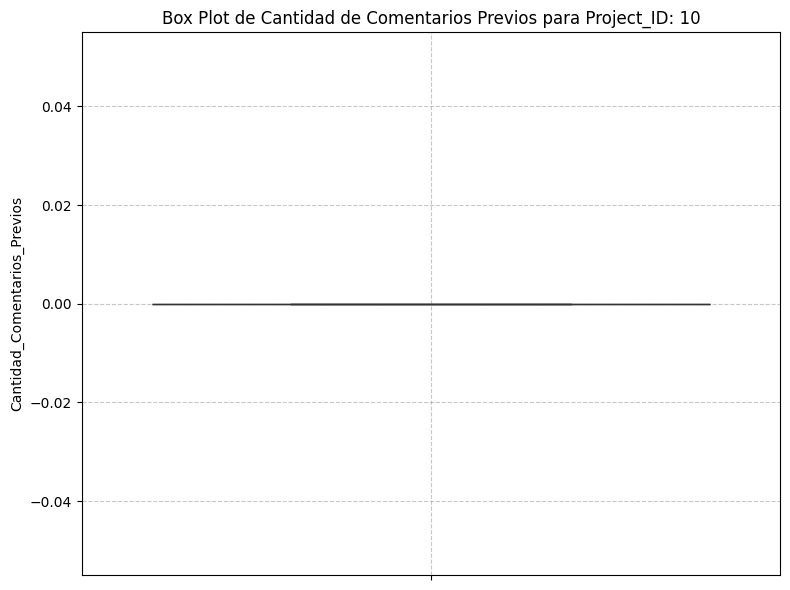

/tmp/ipykernel_5635/2851333979.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Cantidad_Comentarios_Previos'], palette='viridis')


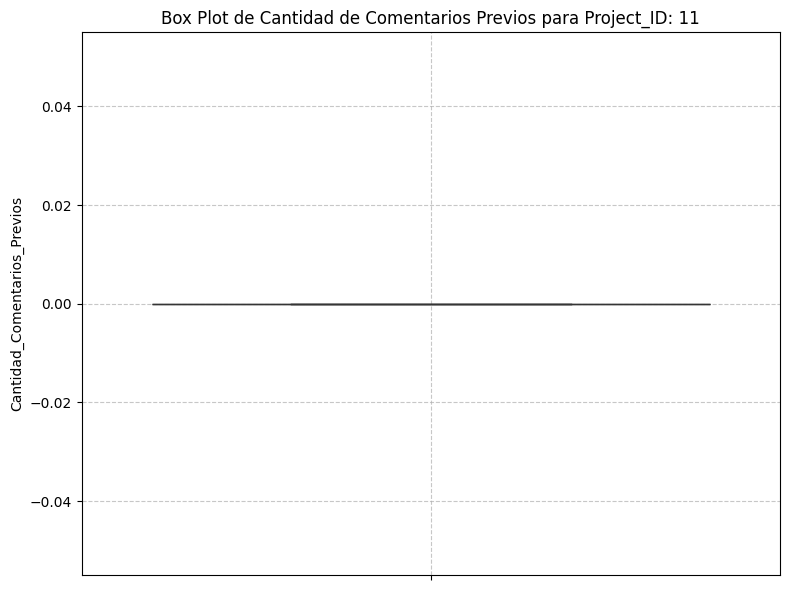

/tmp/ipykernel_5635/2851333979.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Cantidad_Comentarios_Previos'], palette='viridis')


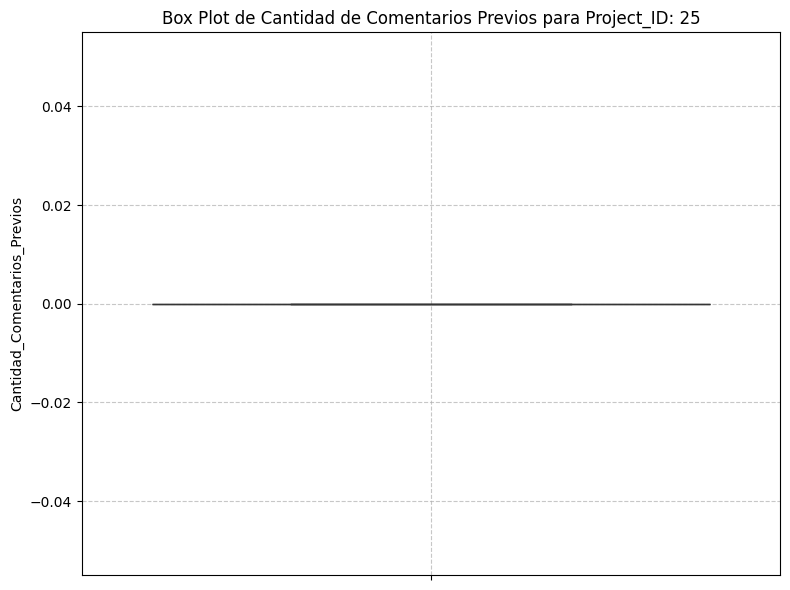

/tmp/ipykernel_5635/2851333979.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Cantidad_Comentarios_Previos'], palette='viridis')


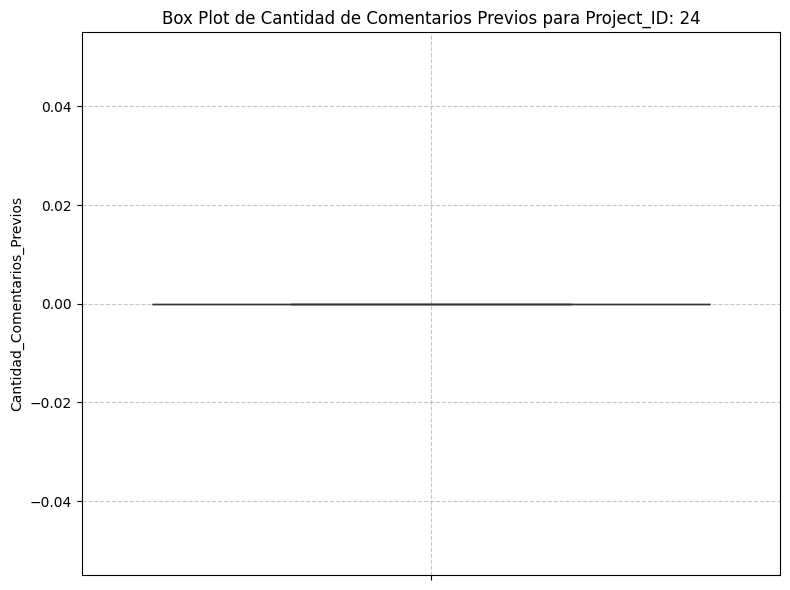

/tmp/ipykernel_5635/2851333979.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Cantidad_Comentarios_Previos'], palette='viridis')


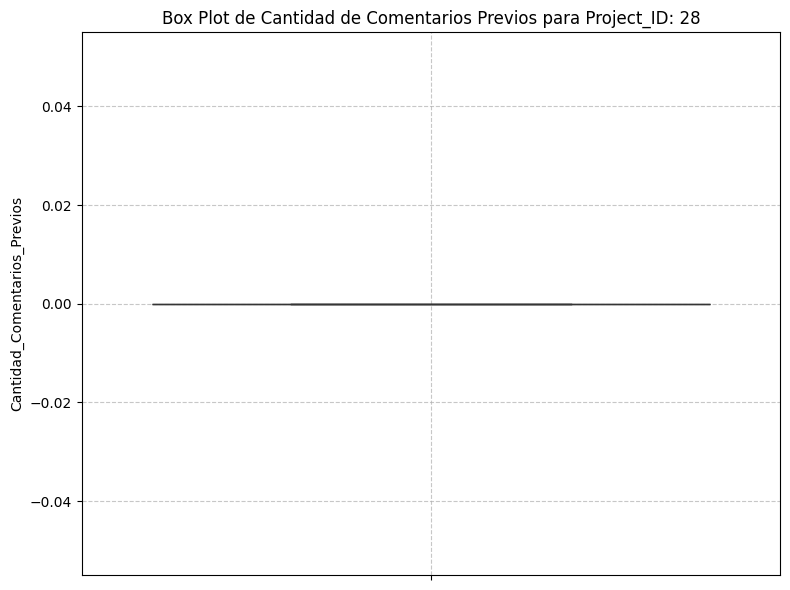

/tmp/ipykernel_5635/2851333979.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Cantidad_Comentarios_Previos'], palette='viridis')


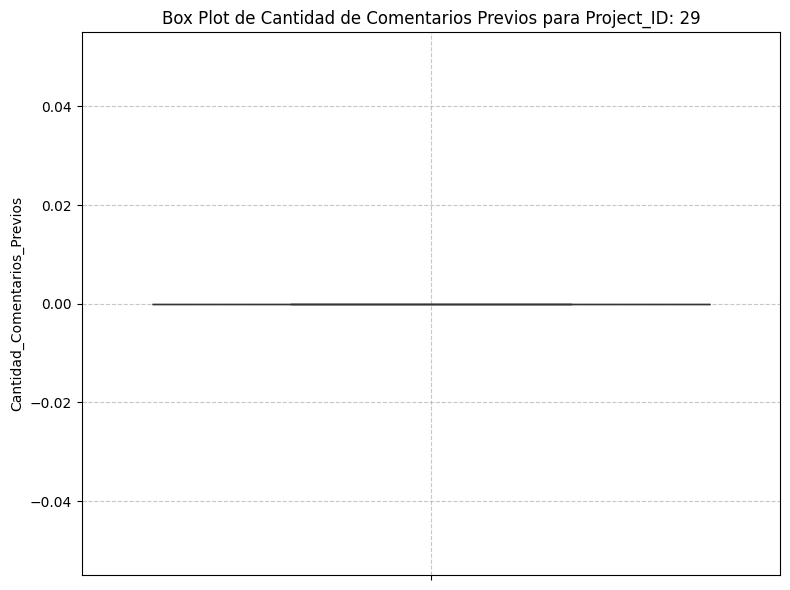

/tmp/ipykernel_5635/2851333979.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Cantidad_Comentarios_Previos'], palette='viridis')


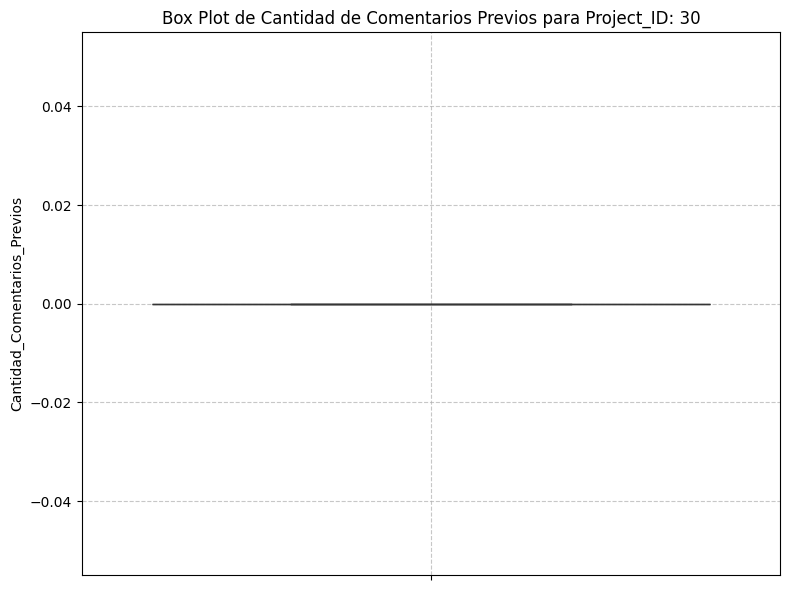

/tmp/ipykernel_5635/2851333979.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Cantidad_Comentarios_Previos'], palette='viridis')


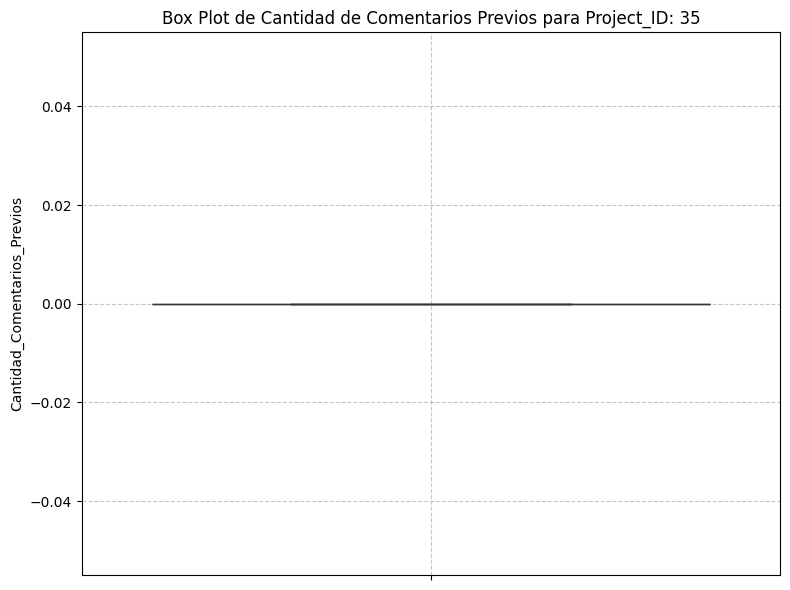

/tmp/ipykernel_5635/2851333979.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Cantidad_Comentarios_Previos'], palette='viridis')


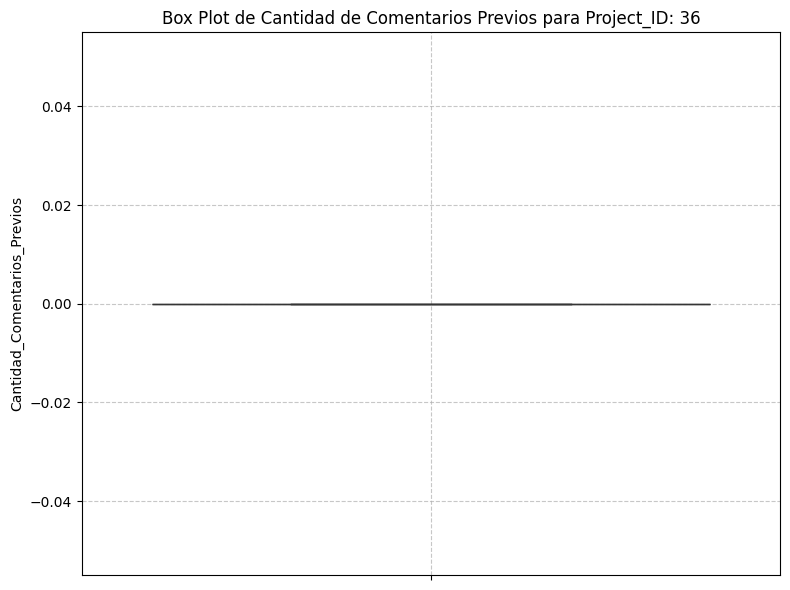

/tmp/ipykernel_5635/2851333979.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Cantidad_Comentarios_Previos'], palette='viridis')


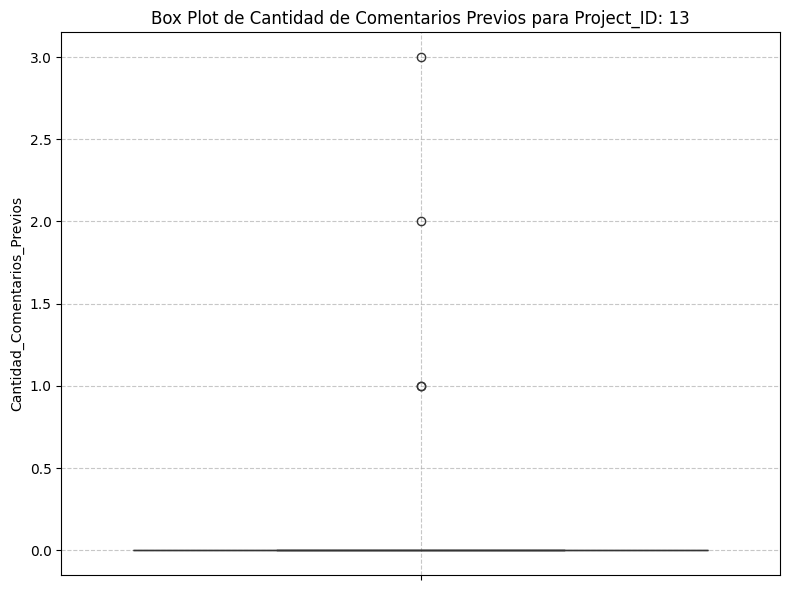

/tmp/ipykernel_5635/2851333979.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Cantidad_Comentarios_Previos'], palette='viridis')


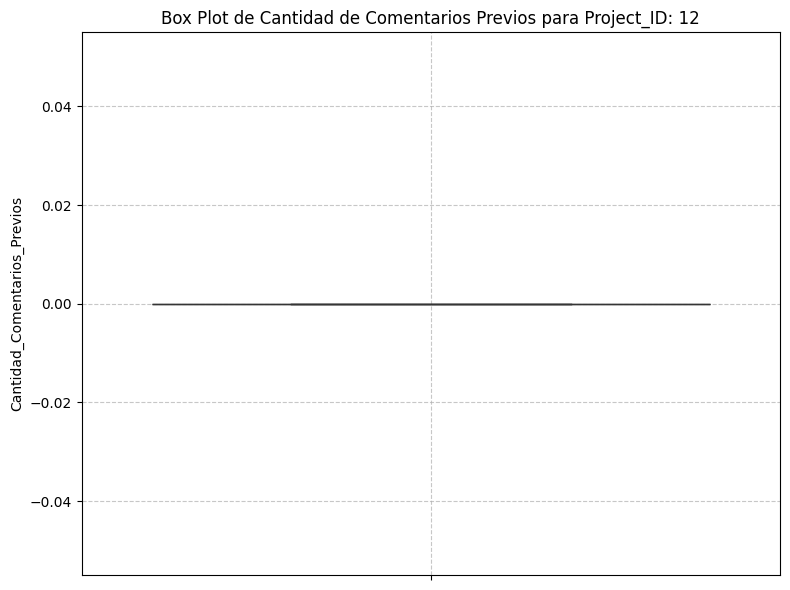

/tmp/ipykernel_5635/2851333979.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Cantidad_Comentarios_Previos'], palette='viridis')


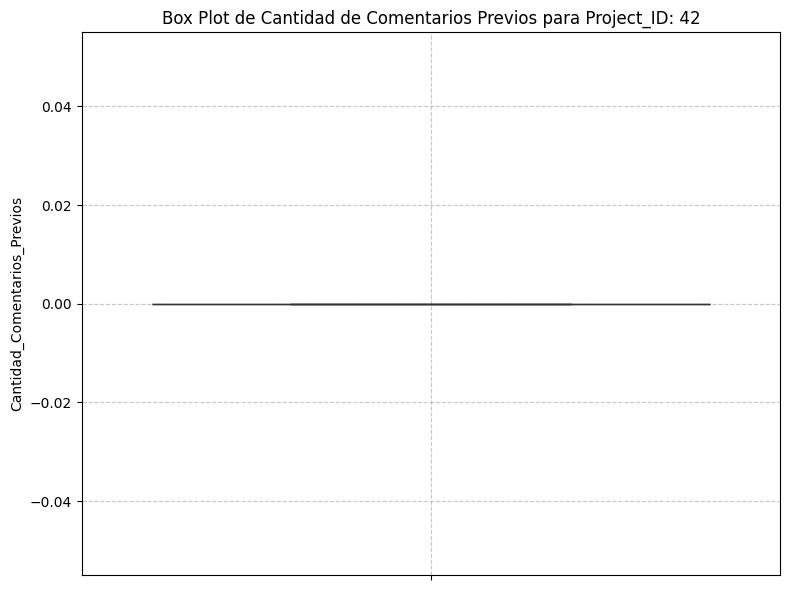

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

print("Generando box plot de 'Cantidad_Comentarios_Previos' individualmente por cada 'Project_ID'...")

unique_project_ids = df['Project_ID'].unique()

for project_id in unique_project_ids:
  subset_df = df[df['Project_ID'] == project_id]
  plt.figure(figsize=(8, 6))
  sns.boxplot(y=subset_df['Cantidad_Comentarios_Previos'], palette='viridis')
  plt.title(f'Box Plot de Cantidad de Comentarios Previos para Project_ID: {project_id}')
  plt.ylabel('Cantidad_Comentarios_Previos')
  plt.grid(True, linestyle='--', alpha=0.7)
  plt.tight_layout()
  plt.show()

/tmp/ipykernel_5635/2127696422.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Cantidad_Components'], palette='viridis')


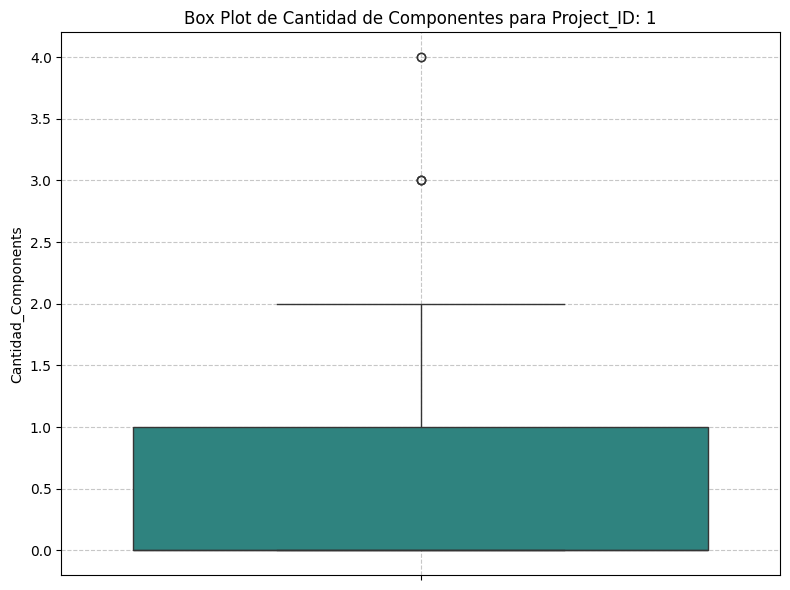

/tmp/ipykernel_5635/2127696422.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Cantidad_Components'], palette='viridis')


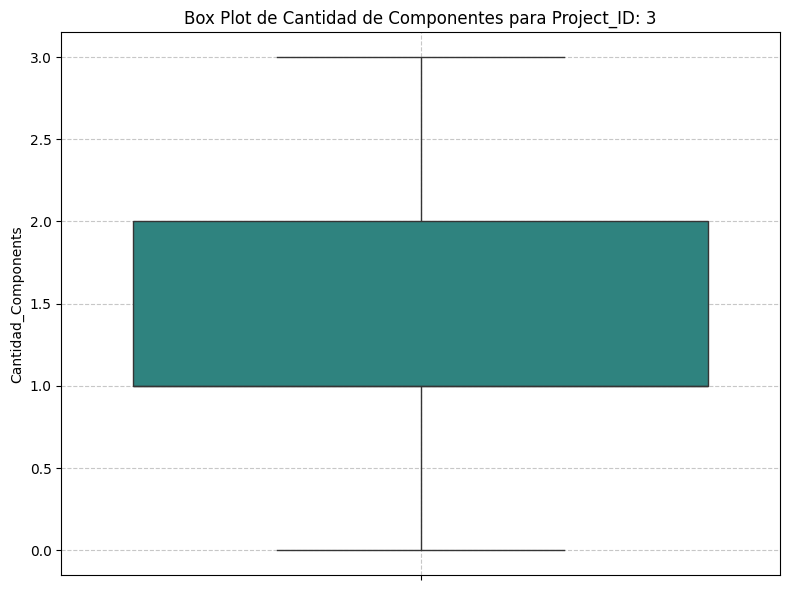

/tmp/ipykernel_5635/2127696422.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Cantidad_Components'], palette='viridis')


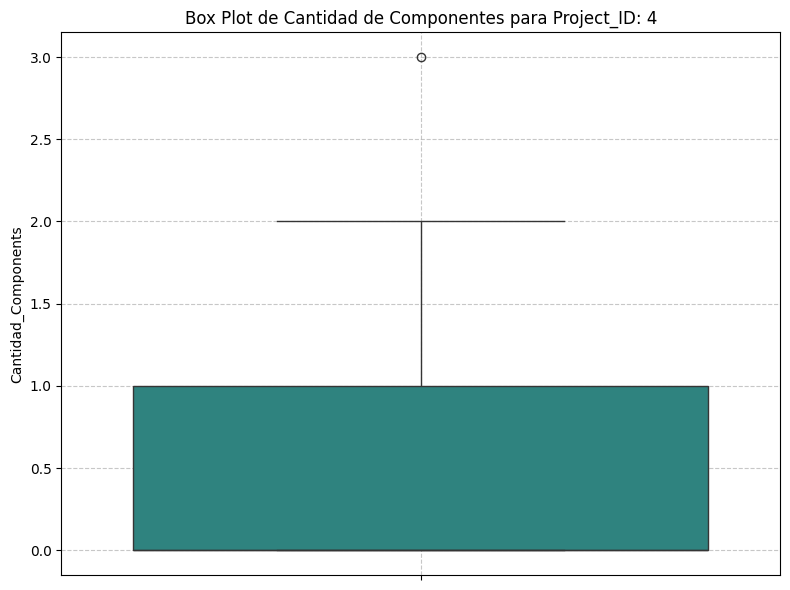

/tmp/ipykernel_5635/2127696422.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Cantidad_Components'], palette='viridis')


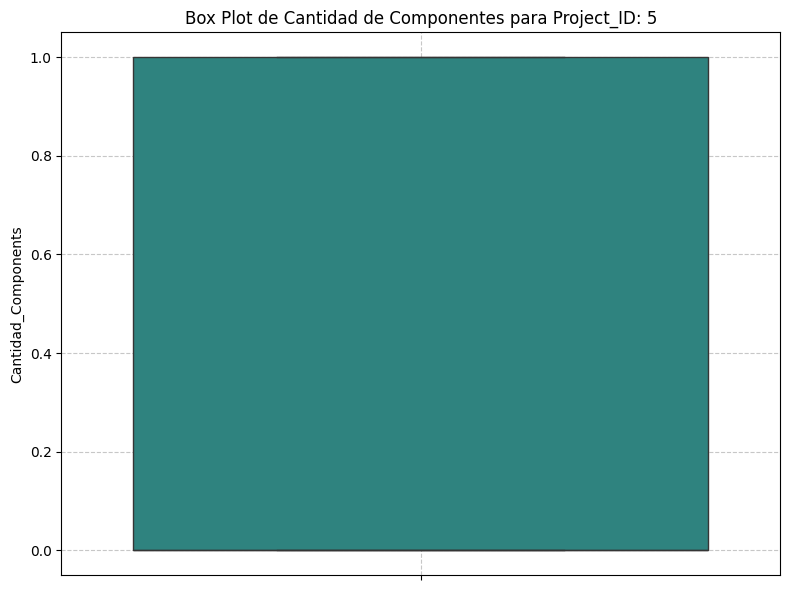

/tmp/ipykernel_5635/2127696422.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Cantidad_Components'], palette='viridis')


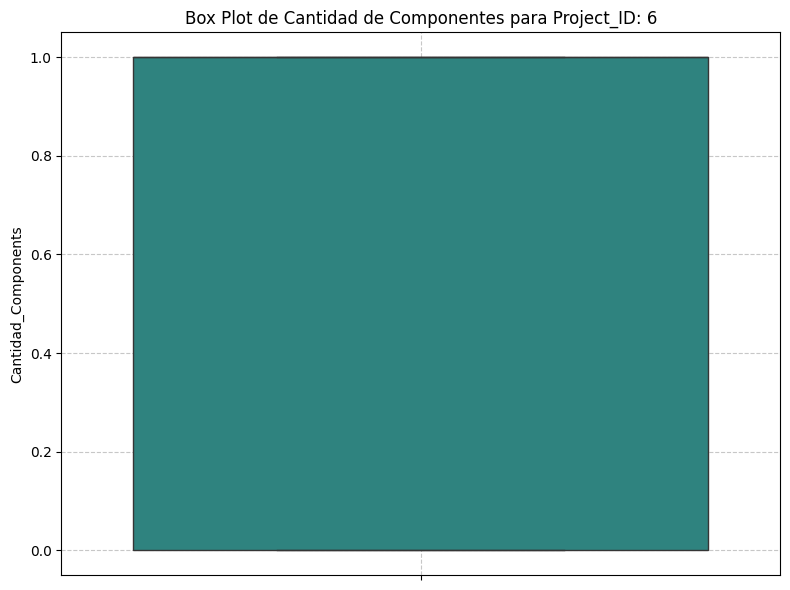

/tmp/ipykernel_5635/2127696422.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Cantidad_Components'], palette='viridis')


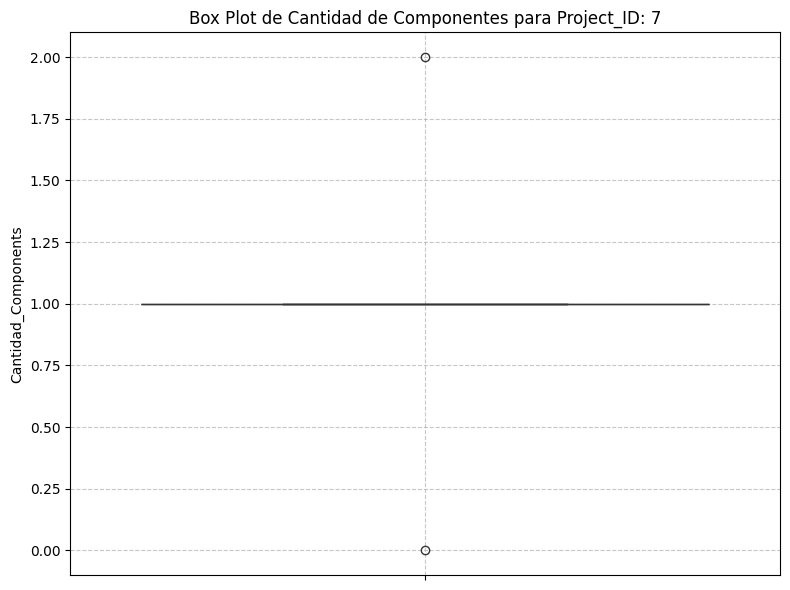

/tmp/ipykernel_5635/2127696422.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Cantidad_Components'], palette='viridis')


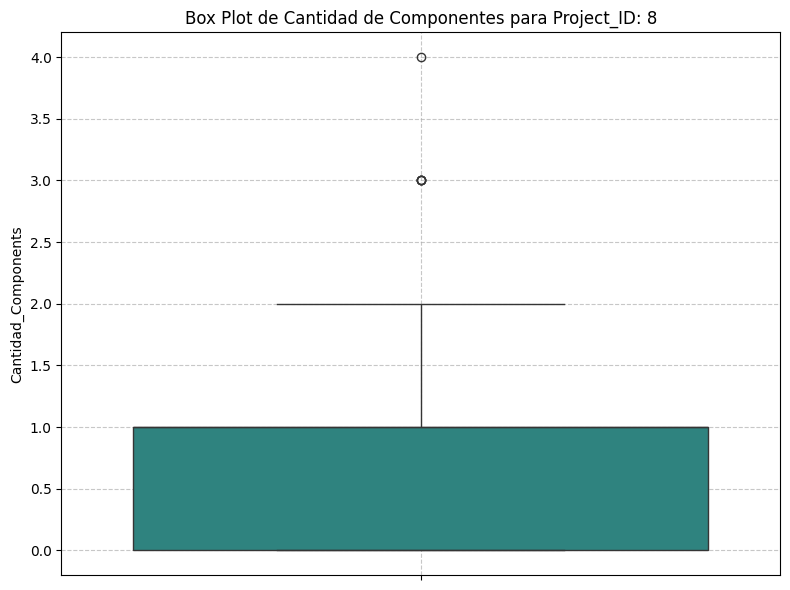

/tmp/ipykernel_5635/2127696422.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Cantidad_Components'], palette='viridis')


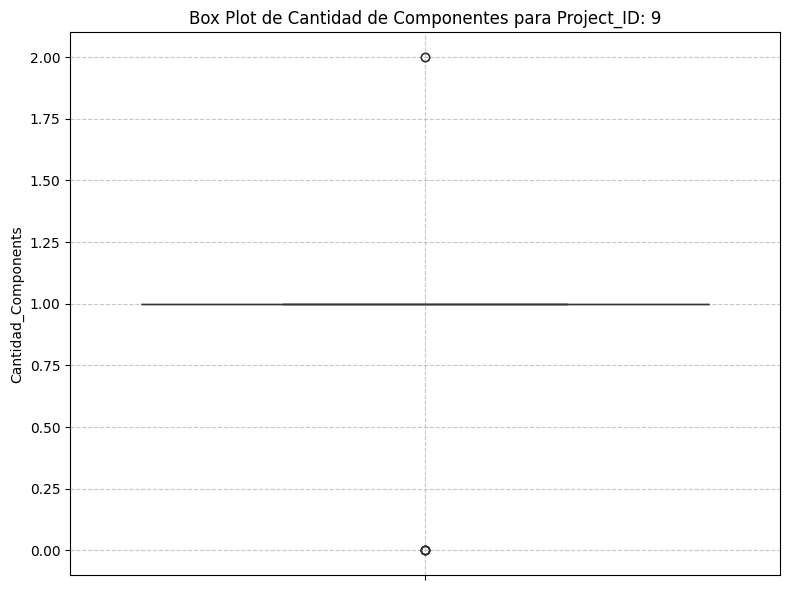

/tmp/ipykernel_5635/2127696422.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Cantidad_Components'], palette='viridis')


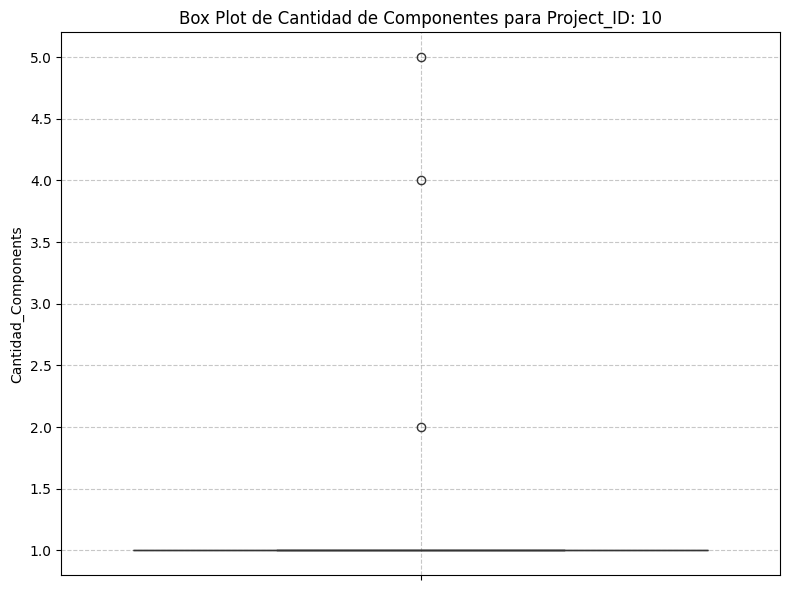

/tmp/ipykernel_5635/2127696422.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Cantidad_Components'], palette='viridis')


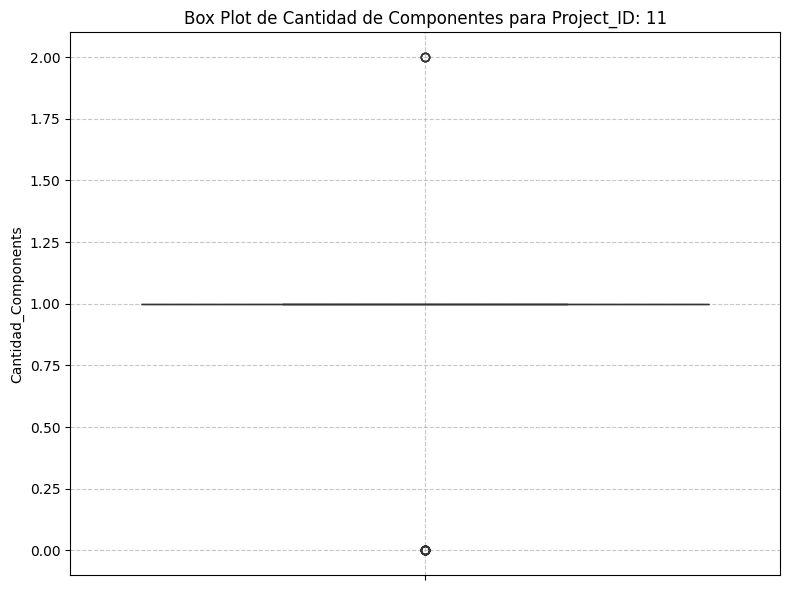

/tmp/ipykernel_5635/2127696422.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Cantidad_Components'], palette='viridis')


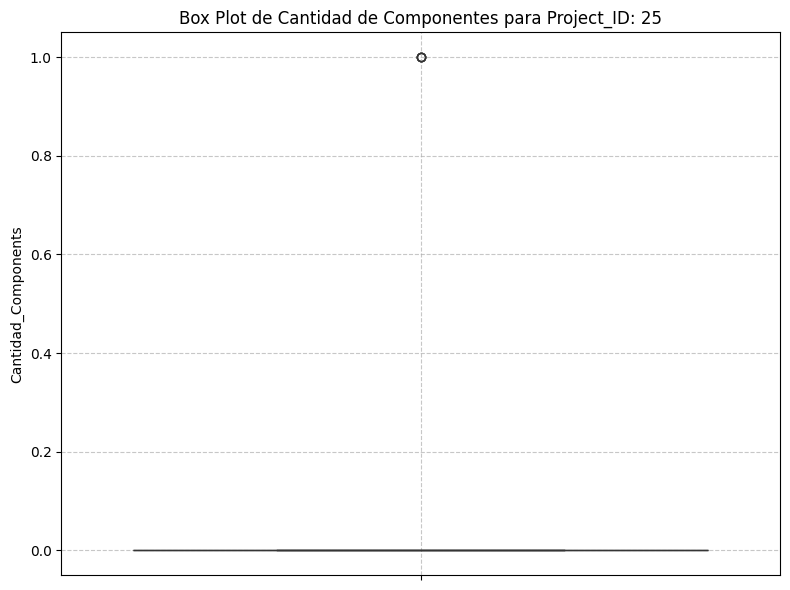

/tmp/ipykernel_5635/2127696422.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Cantidad_Components'], palette='viridis')


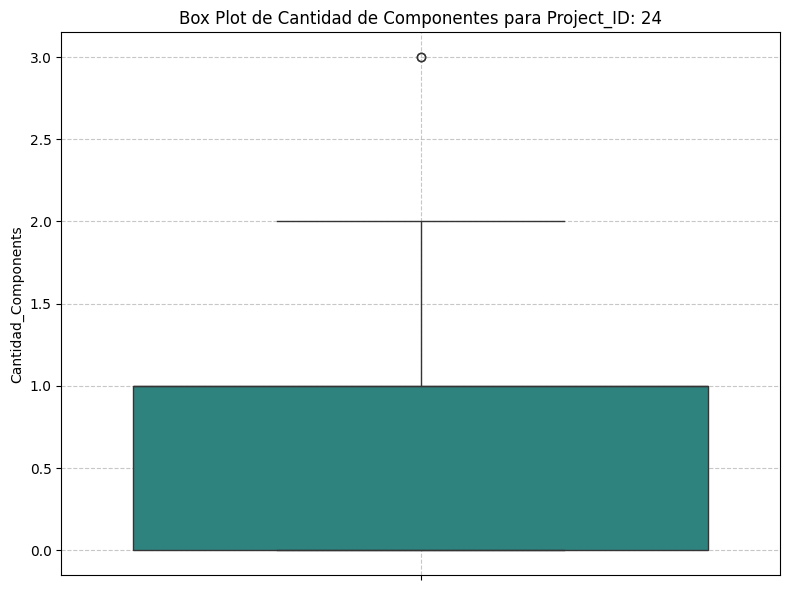

/tmp/ipykernel_5635/2127696422.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Cantidad_Components'], palette='viridis')


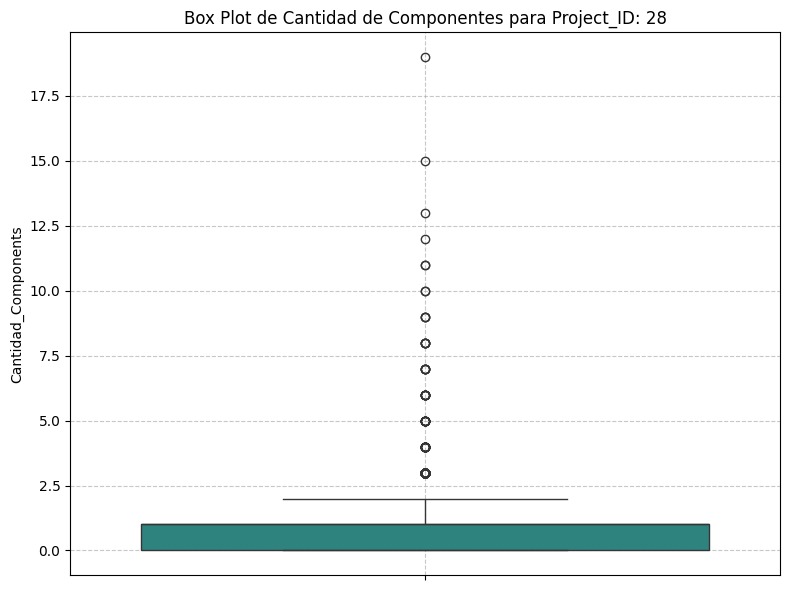

/tmp/ipykernel_5635/2127696422.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Cantidad_Components'], palette='viridis')


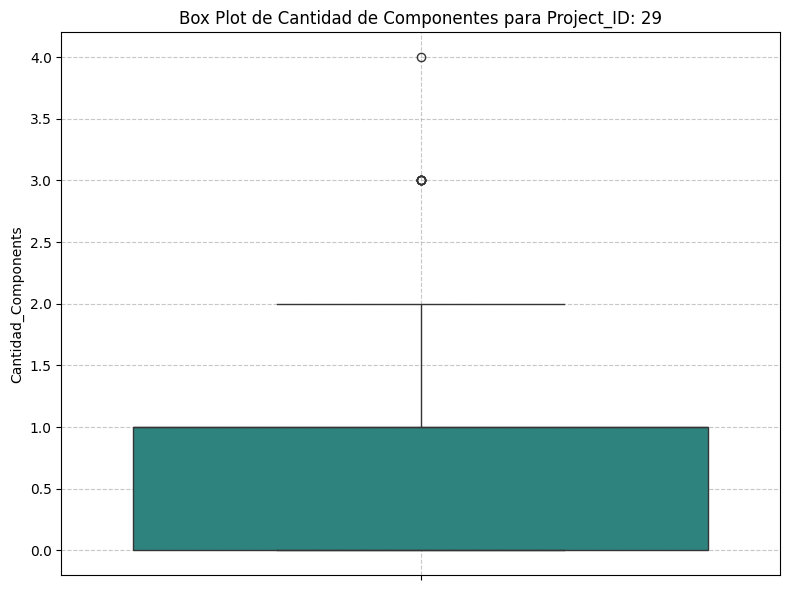

/tmp/ipykernel_5635/2127696422.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Cantidad_Components'], palette='viridis')


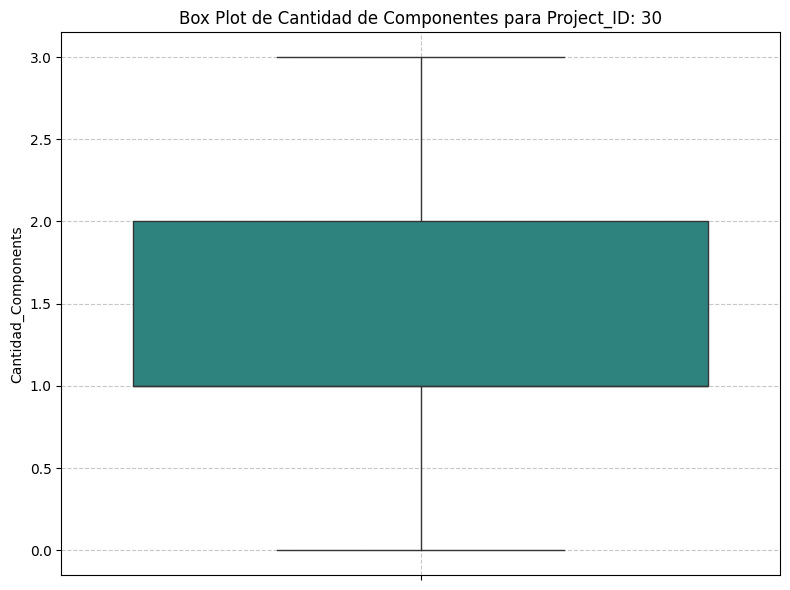

/tmp/ipykernel_5635/2127696422.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Cantidad_Components'], palette='viridis')


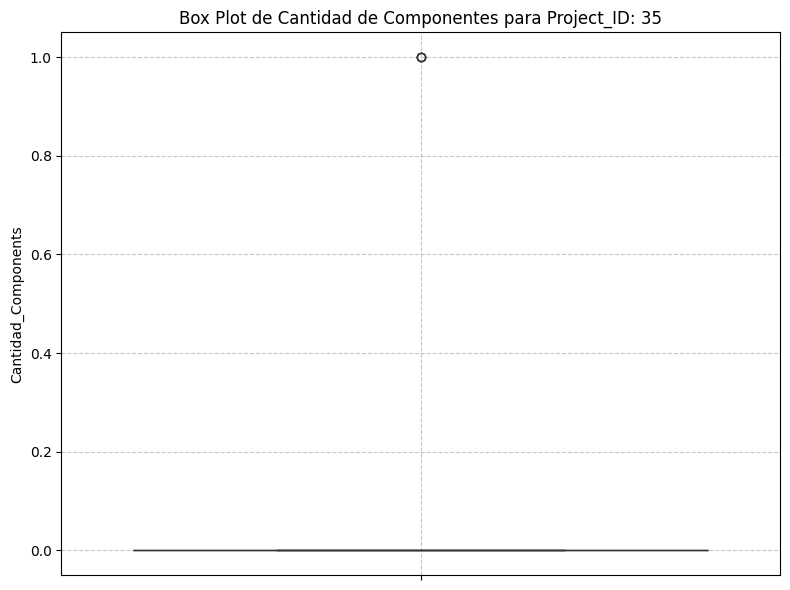

/tmp/ipykernel_5635/2127696422.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Cantidad_Components'], palette='viridis')


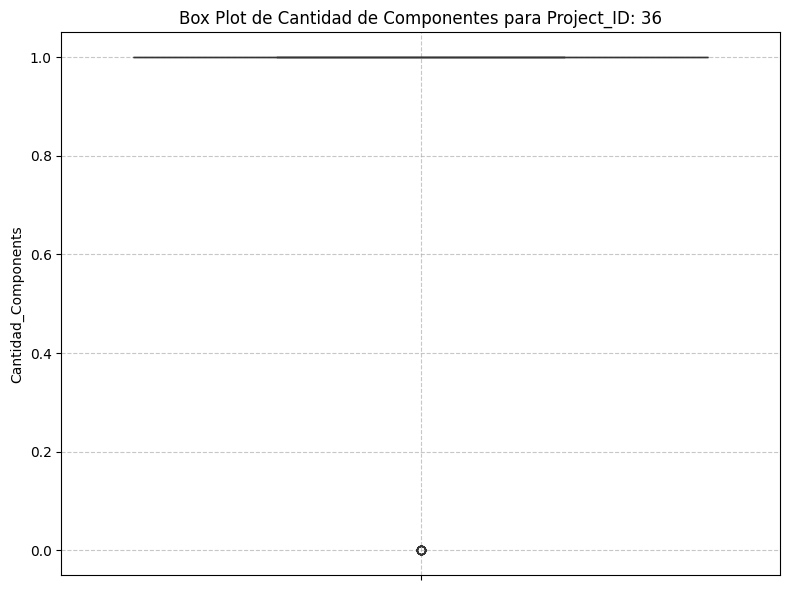

/tmp/ipykernel_5635/2127696422.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Cantidad_Components'], palette='viridis')


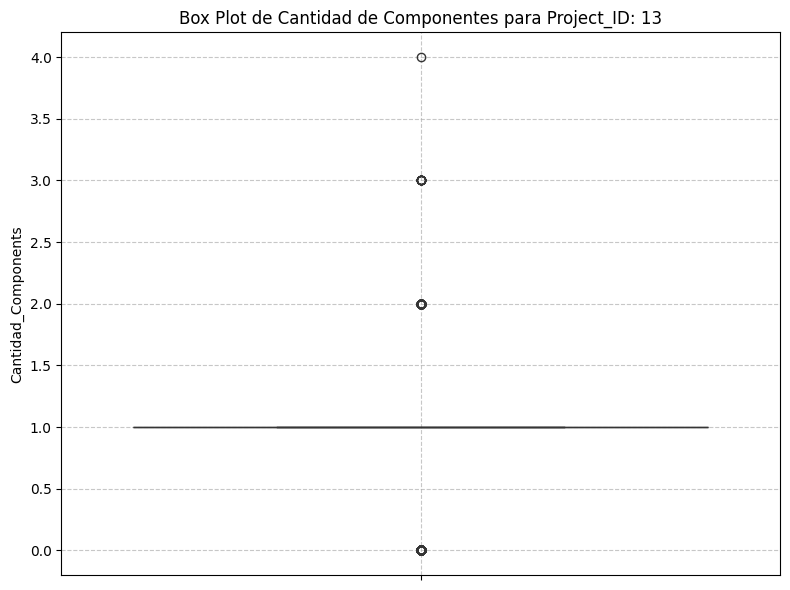

/tmp/ipykernel_5635/2127696422.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Cantidad_Components'], palette='viridis')


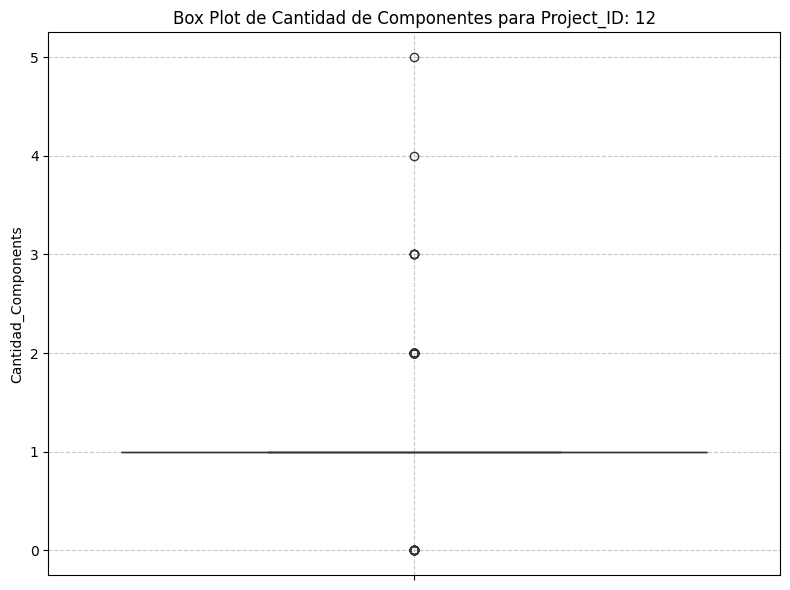

/tmp/ipykernel_5635/2127696422.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=subset_df['Cantidad_Components'], palette='viridis')


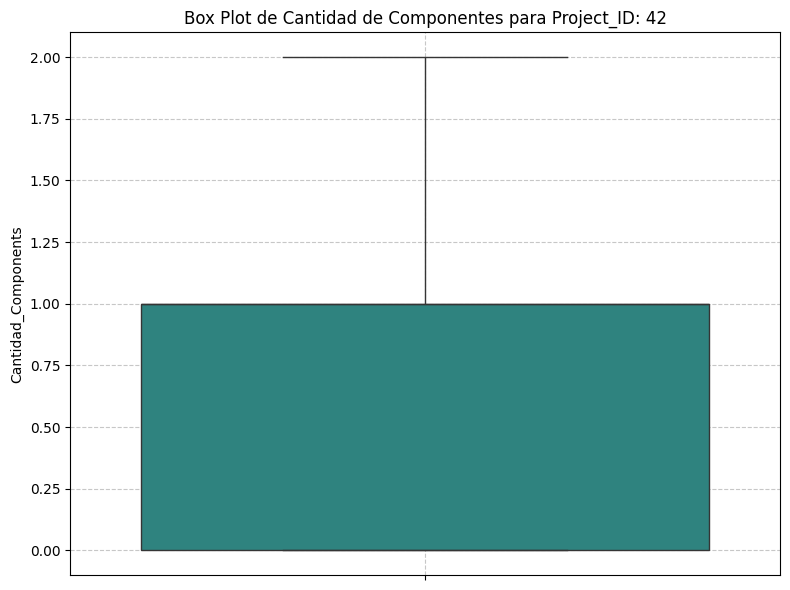

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

unique_project_ids = df['Project_ID'].unique()

for project_id in unique_project_ids:
  subset_df = df[df['Project_ID'] == project_id]

  plt.figure(figsize=(8, 6))
  sns.boxplot(y=subset_df['Cantidad_Components'], palette='viridis')
  plt.title(f'Box Plot de Cantidad de Componentes para Project_ID: {project_id}')
  plt.ylabel('Cantidad_Components')
  plt.grid(True, linestyle='--', alpha=0.7)
  plt.tight_layout()
  plt.show()


Generando histogramas de 'Cantidad_Comentarios_Previos' individualmente por cada 'Project_ID'...


/tmp/ipykernel_5635/2895575545.py:13: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(subset_df[column_to_histogram], bins=30, kde=True, palette='viridis')


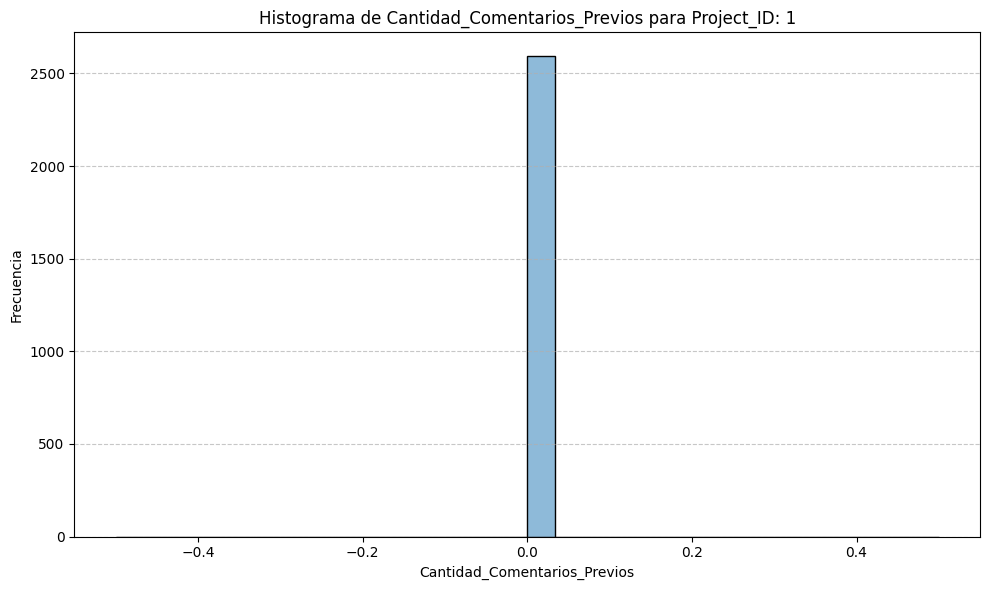

/tmp/ipykernel_5635/2895575545.py:13: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(subset_df[column_to_histogram], bins=30, kde=True, palette='viridis')


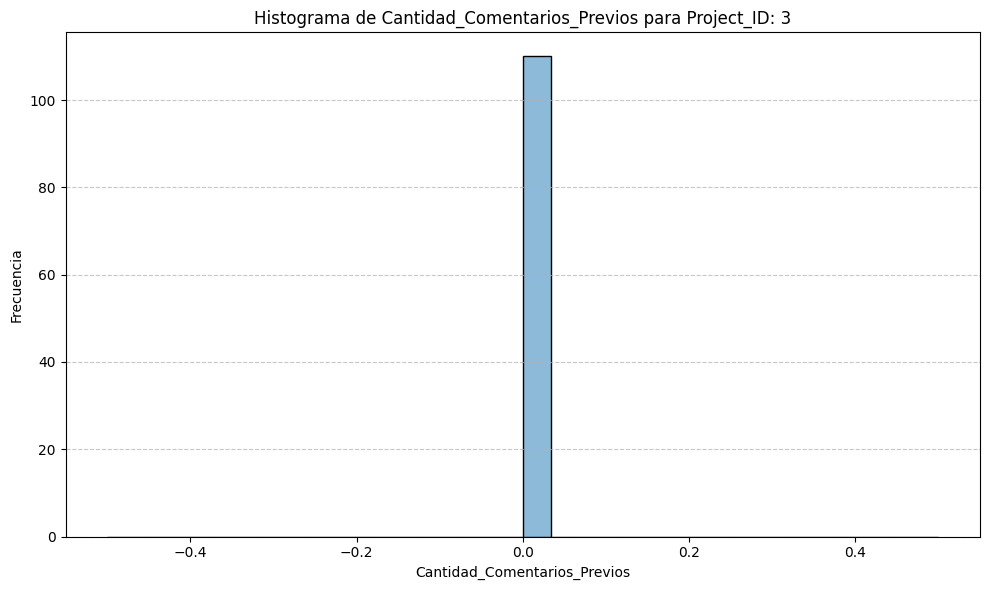

/tmp/ipykernel_5635/2895575545.py:13: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(subset_df[column_to_histogram], bins=30, kde=True, palette='viridis')


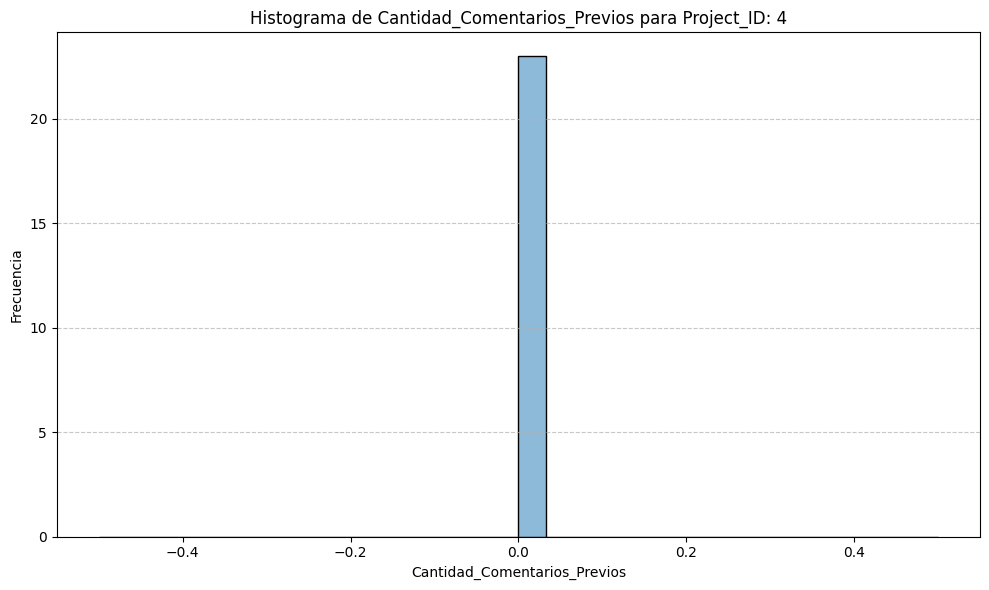

/tmp/ipykernel_5635/2895575545.py:13: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(subset_df[column_to_histogram], bins=30, kde=True, palette='viridis')


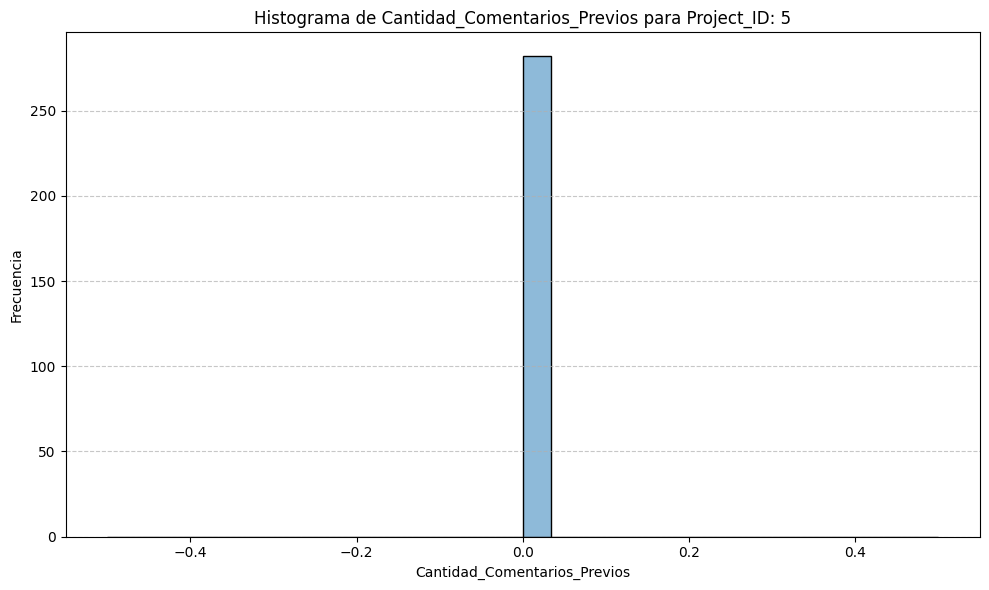

/tmp/ipykernel_5635/2895575545.py:13: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(subset_df[column_to_histogram], bins=30, kde=True, palette='viridis')


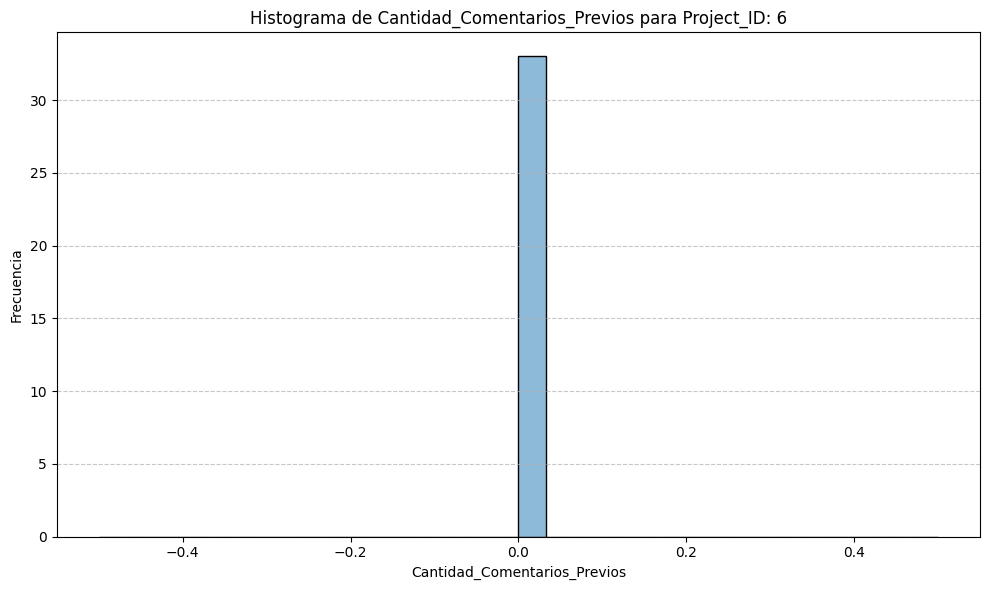

/tmp/ipykernel_5635/2895575545.py:13: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(subset_df[column_to_histogram], bins=30, kde=True, palette='viridis')


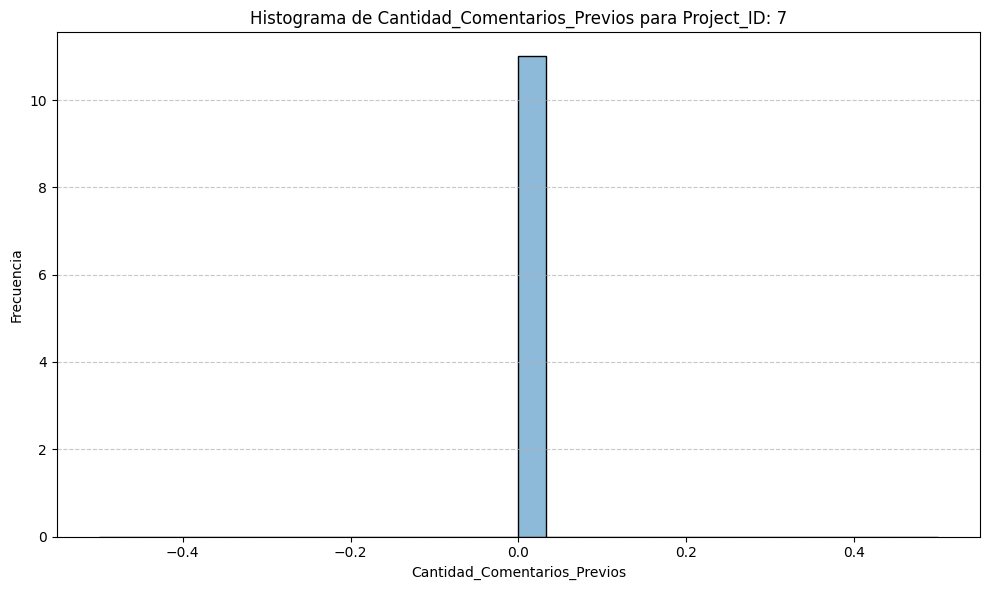

/tmp/ipykernel_5635/2895575545.py:13: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(subset_df[column_to_histogram], bins=30, kde=True, palette='viridis')


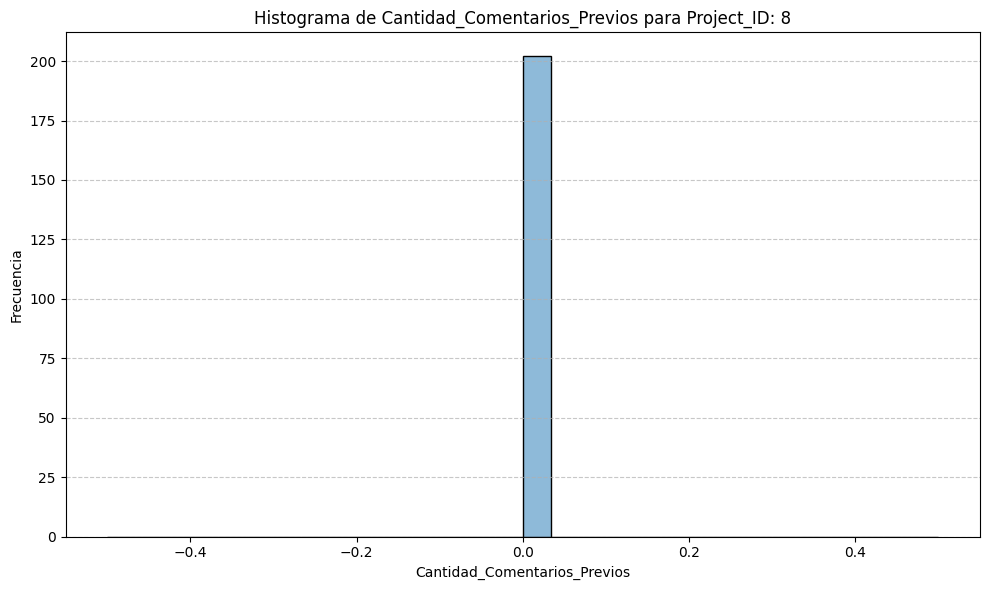

/tmp/ipykernel_5635/2895575545.py:13: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(subset_df[column_to_histogram], bins=30, kde=True, palette='viridis')


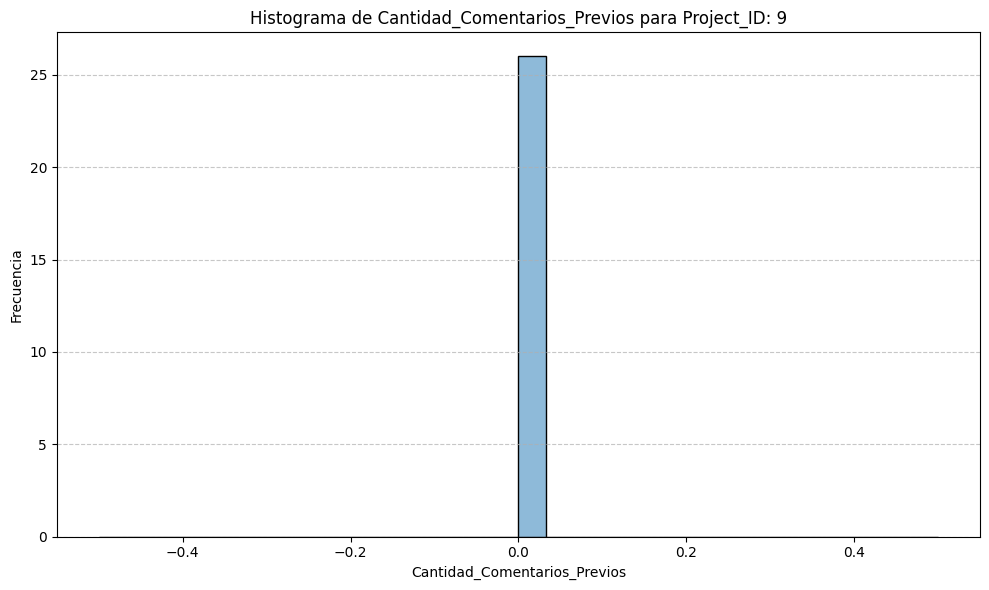

/tmp/ipykernel_5635/2895575545.py:13: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(subset_df[column_to_histogram], bins=30, kde=True, palette='viridis')


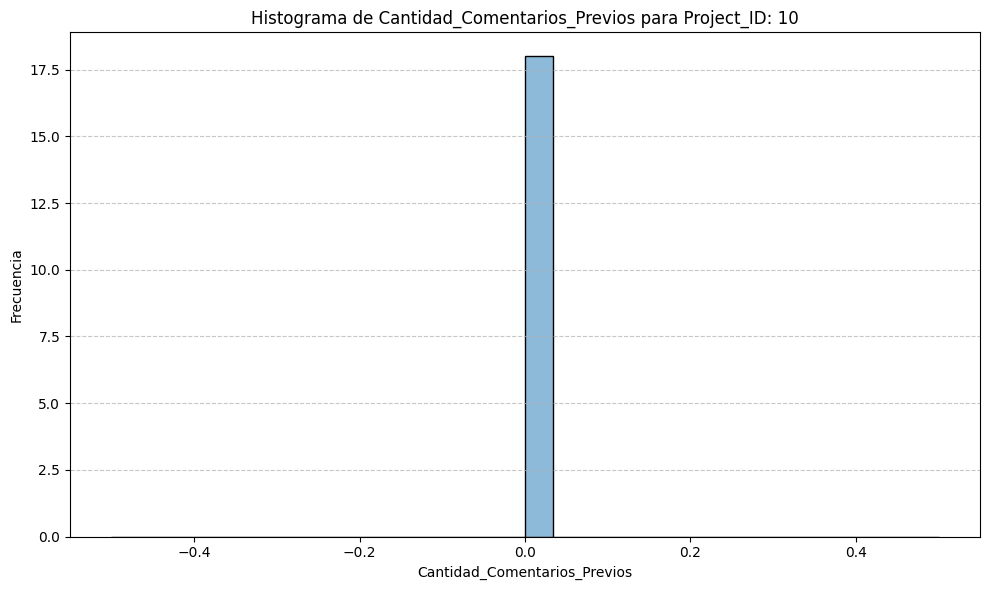

/tmp/ipykernel_5635/2895575545.py:13: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(subset_df[column_to_histogram], bins=30, kde=True, palette='viridis')


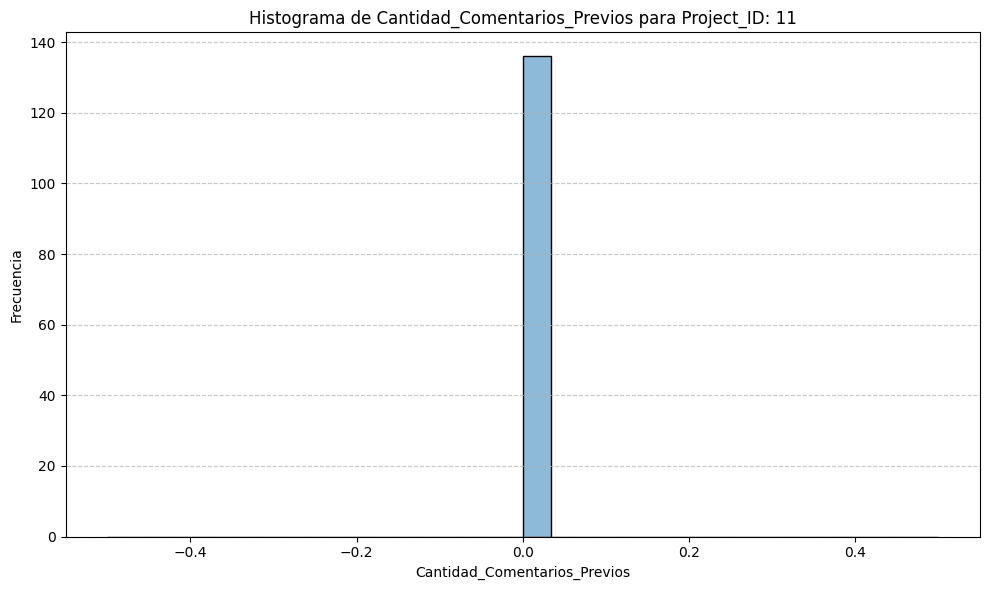

/tmp/ipykernel_5635/2895575545.py:13: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(subset_df[column_to_histogram], bins=30, kde=True, palette='viridis')


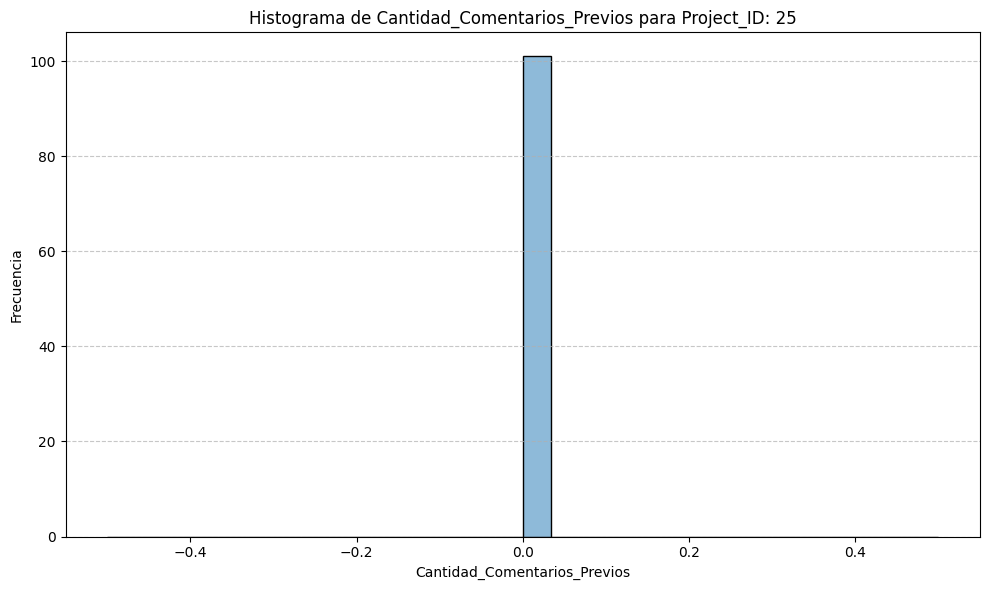

/tmp/ipykernel_5635/2895575545.py:13: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(subset_df[column_to_histogram], bins=30, kde=True, palette='viridis')


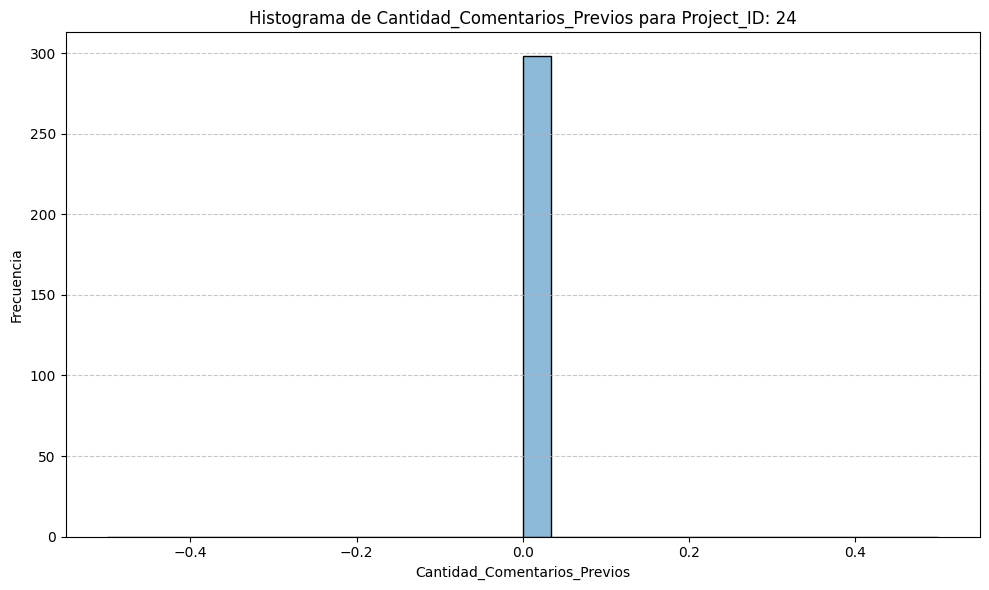

/tmp/ipykernel_5635/2895575545.py:13: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(subset_df[column_to_histogram], bins=30, kde=True, palette='viridis')


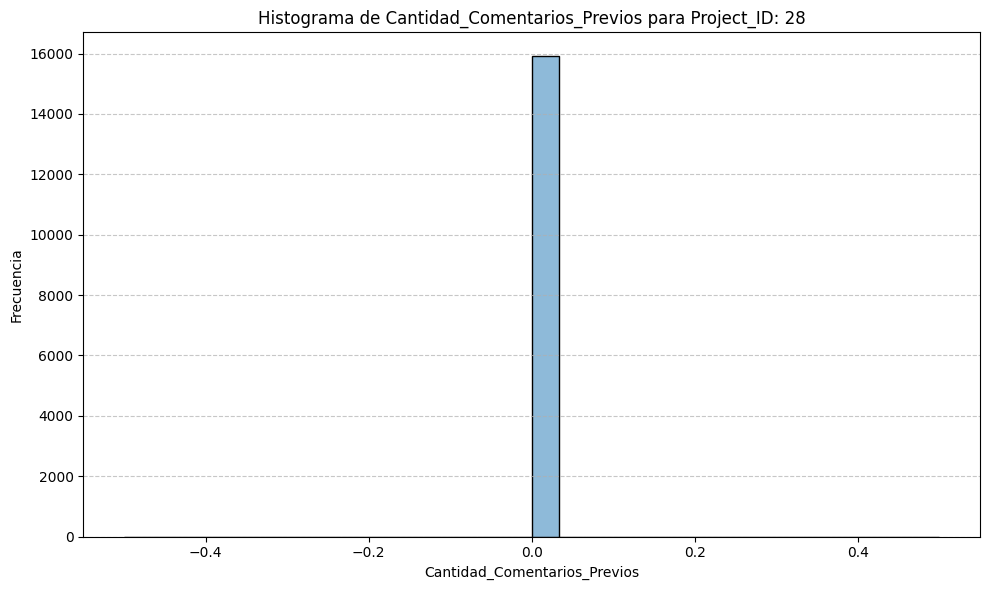

/tmp/ipykernel_5635/2895575545.py:13: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(subset_df[column_to_histogram], bins=30, kde=True, palette='viridis')


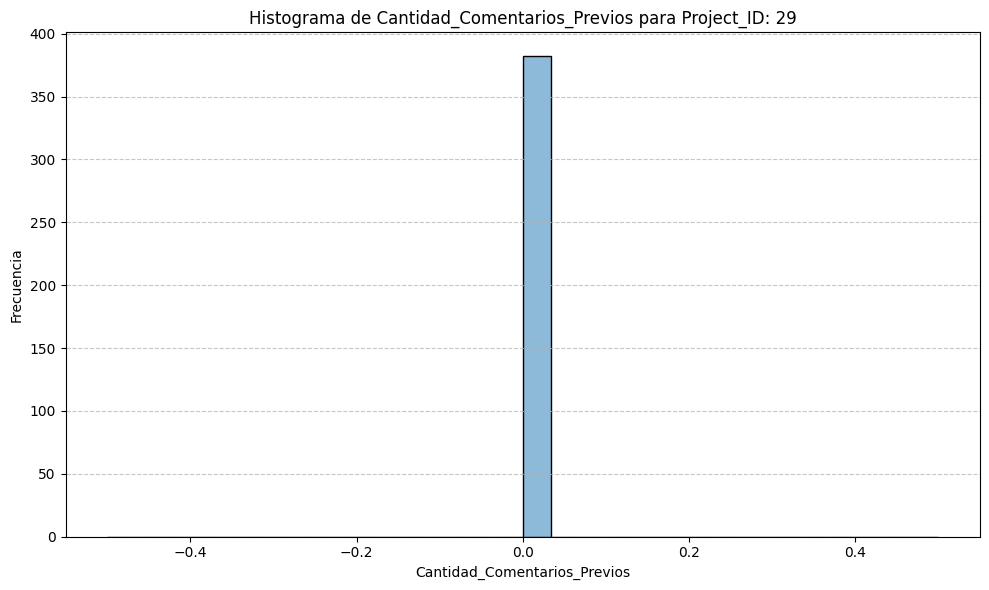

/tmp/ipykernel_5635/2895575545.py:13: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(subset_df[column_to_histogram], bins=30, kde=True, palette='viridis')


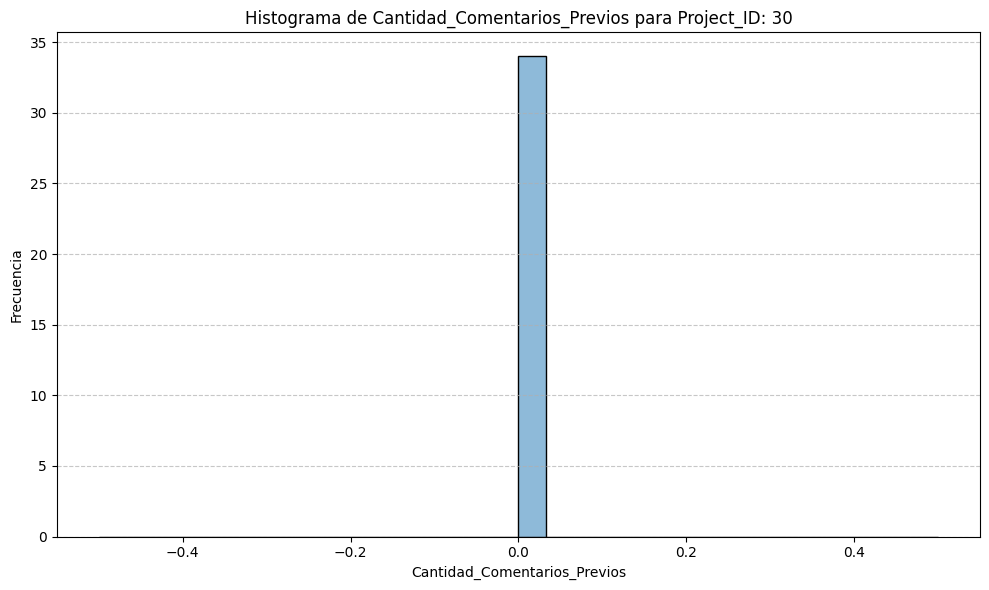

/tmp/ipykernel_5635/2895575545.py:13: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(subset_df[column_to_histogram], bins=30, kde=True, palette='viridis')


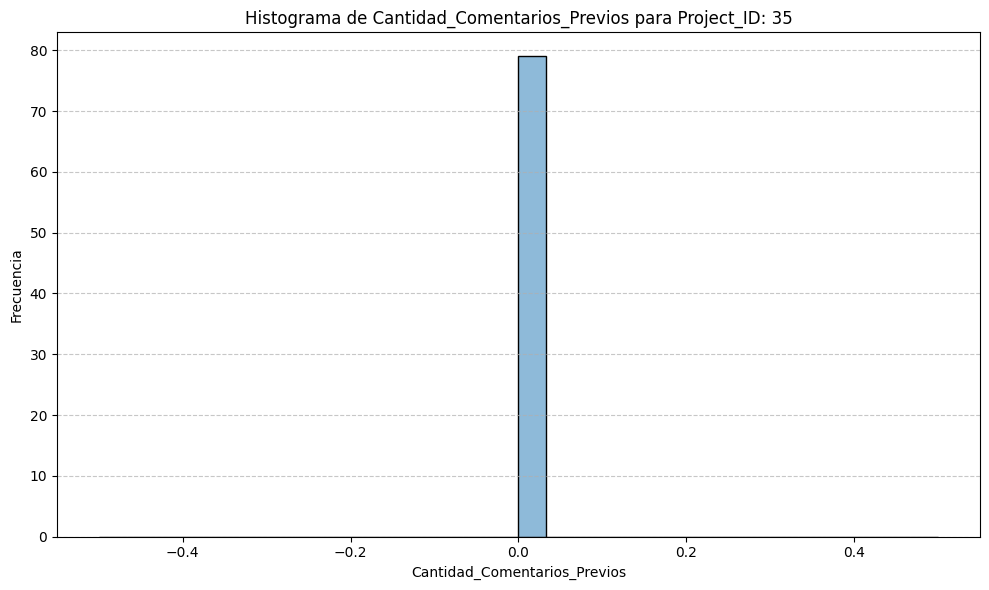

/tmp/ipykernel_5635/2895575545.py:13: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(subset_df[column_to_histogram], bins=30, kde=True, palette='viridis')


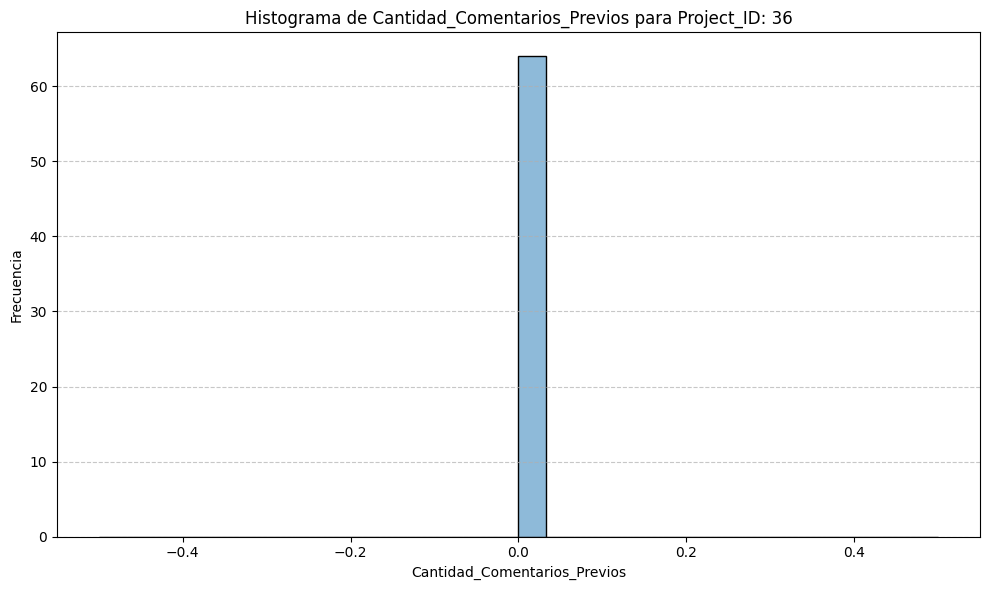

/tmp/ipykernel_5635/2895575545.py:13: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(subset_df[column_to_histogram], bins=30, kde=True, palette='viridis')


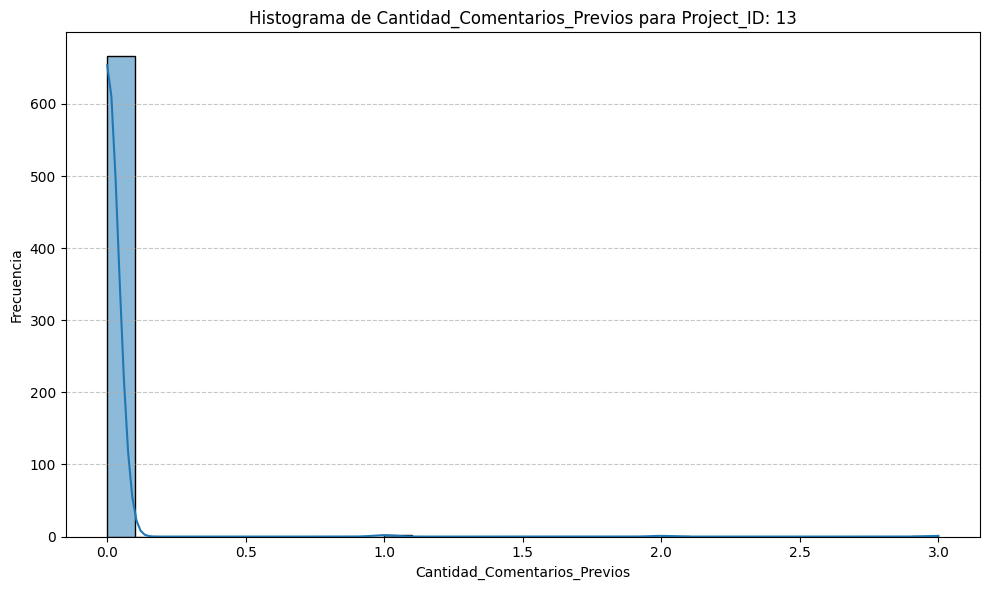

/tmp/ipykernel_5635/2895575545.py:13: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(subset_df[column_to_histogram], bins=30, kde=True, palette='viridis')


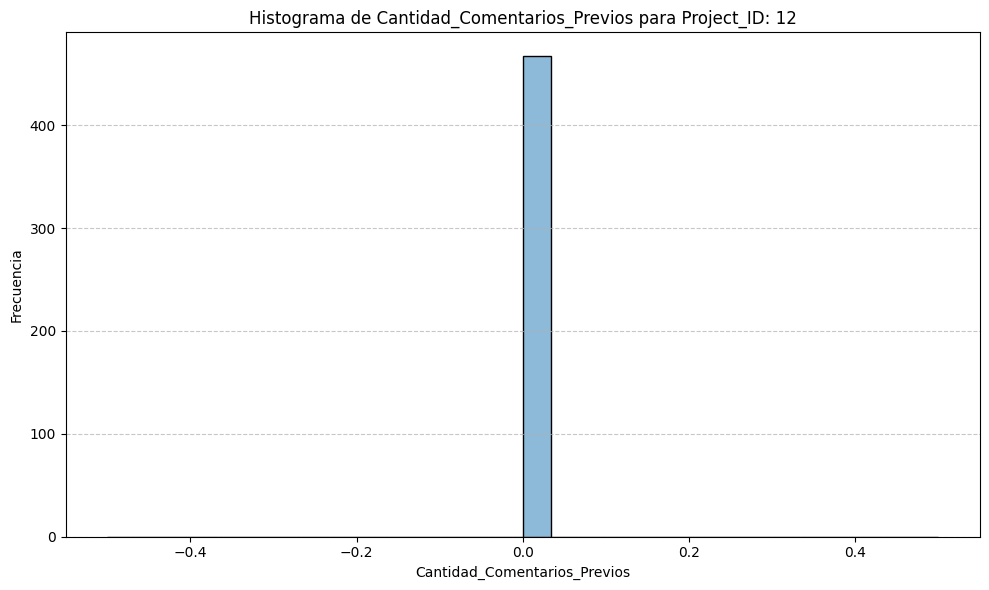

/tmp/ipykernel_5635/2895575545.py:13: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(subset_df[column_to_histogram], bins=30, kde=True, palette='viridis')


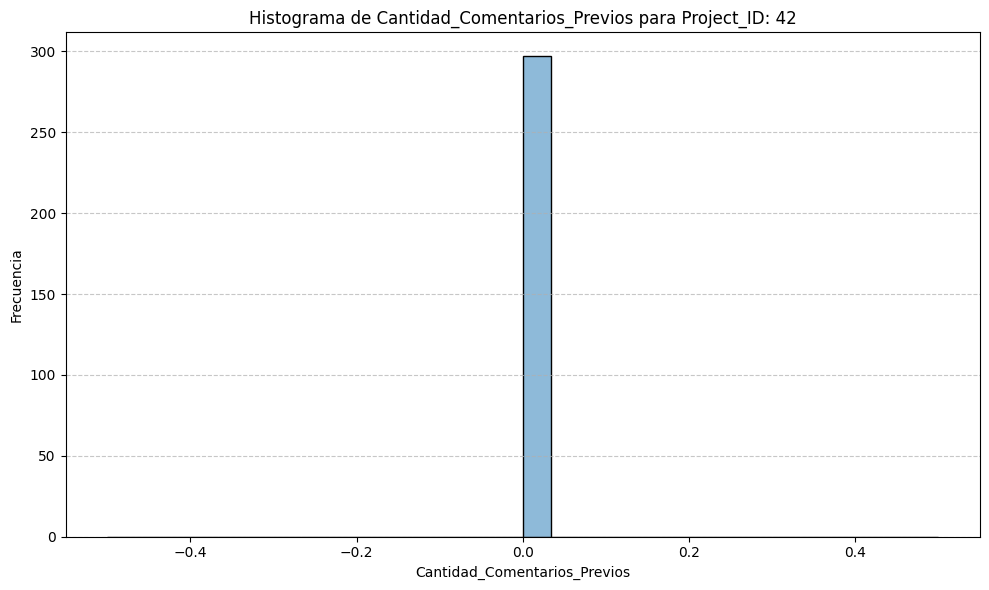

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

column_to_histogram = 'Cantidad_Comentarios_Previos'
print(f"Generando histogramas de '{column_to_histogram}' individualmente por cada 'Project_ID'...")

unique_project_ids = df['Project_ID'].unique()

for project_id in unique_project_ids:
  subset_df = df[df['Project_ID'] == project_id]

  plt.figure(figsize=(10, 6))
  sns.histplot(subset_df[column_to_histogram], bins=30, kde=True, palette='viridis')
  plt.title(f"Histograma de {column_to_histogram} para Project_ID: {project_id}")
  plt.xlabel(column_to_histogram)
  plt.ylabel('Frecuencia')
  plt.grid(axis='y', linestyle='--', alpha=0.7)
  plt.tight_layout()
  plt.show()


/tmp/ipykernel_5635/1808863845.py:11: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(subset_df[column_to_histogram], bins=30, kde=True, palette='viridis')


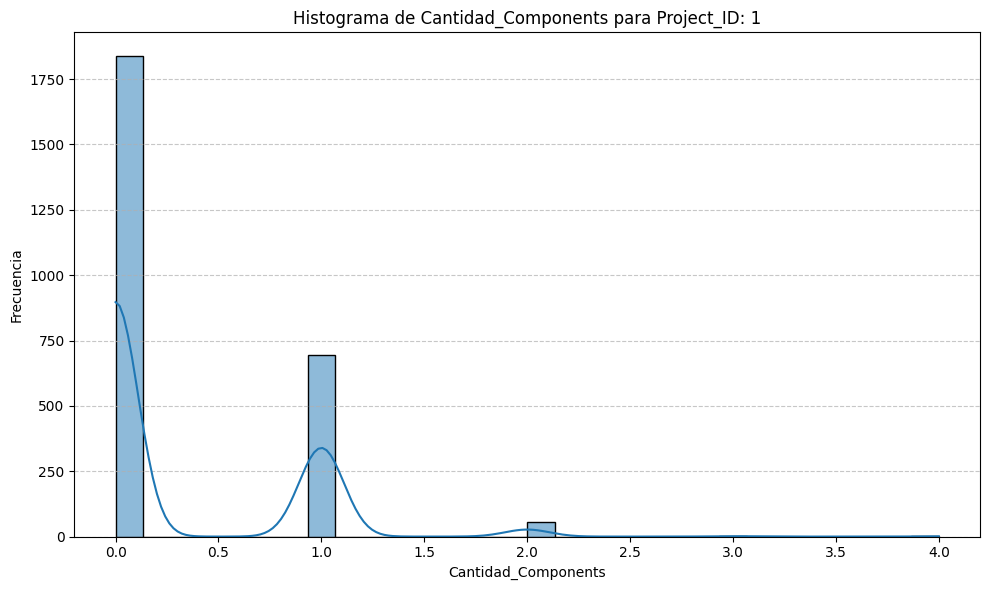

/tmp/ipykernel_5635/1808863845.py:11: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(subset_df[column_to_histogram], bins=30, kde=True, palette='viridis')


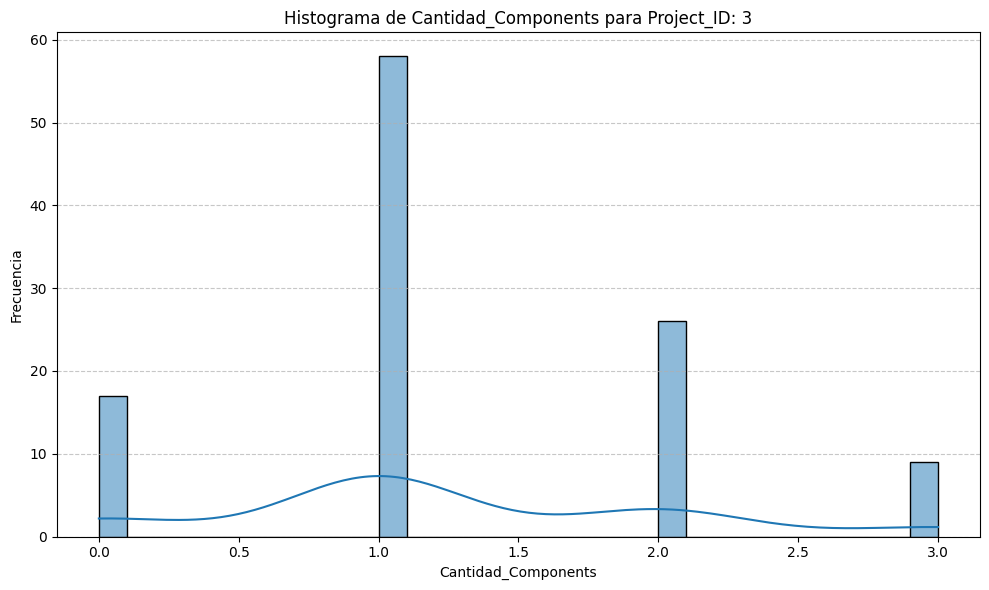

/tmp/ipykernel_5635/1808863845.py:11: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(subset_df[column_to_histogram], bins=30, kde=True, palette='viridis')


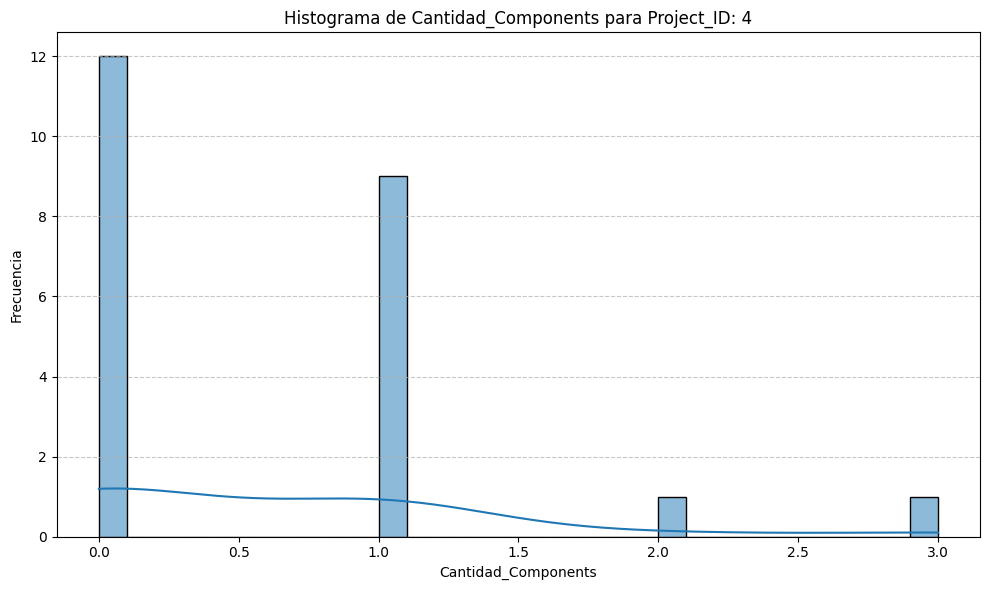

/tmp/ipykernel_5635/1808863845.py:11: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(subset_df[column_to_histogram], bins=30, kde=True, palette='viridis')


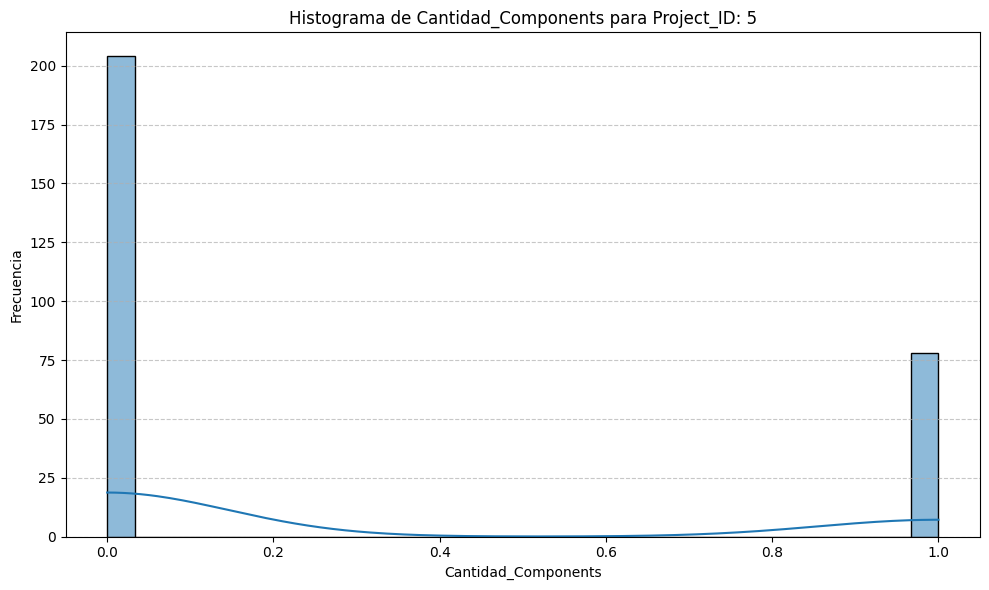

/tmp/ipykernel_5635/1808863845.py:11: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(subset_df[column_to_histogram], bins=30, kde=True, palette='viridis')


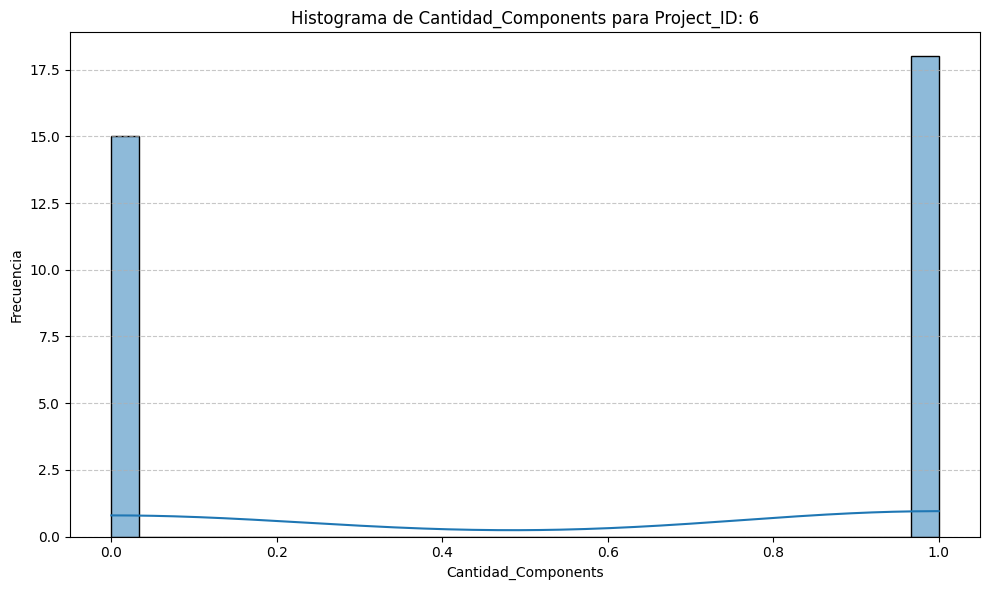

/tmp/ipykernel_5635/1808863845.py:11: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(subset_df[column_to_histogram], bins=30, kde=True, palette='viridis')


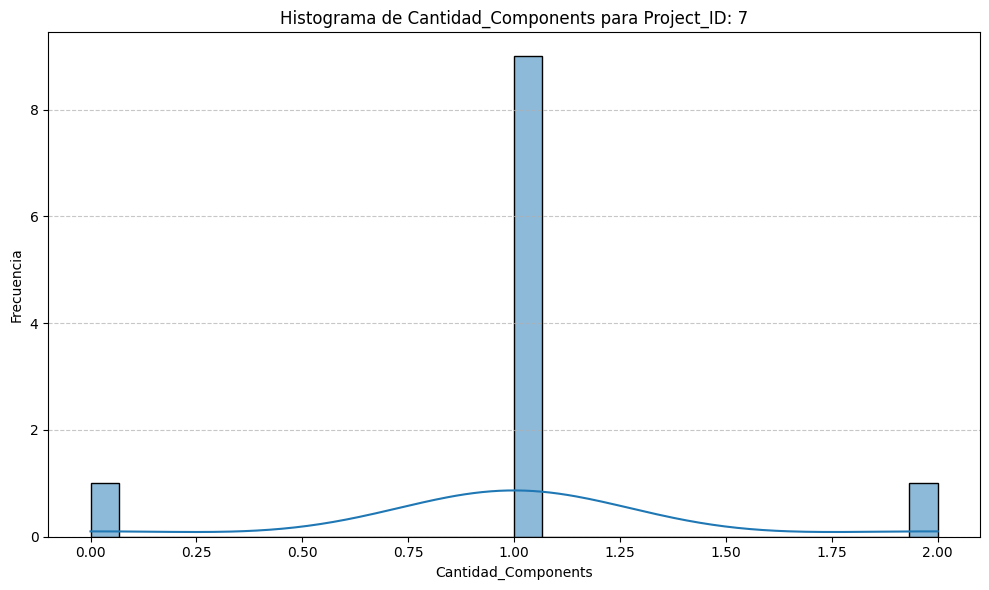

/tmp/ipykernel_5635/1808863845.py:11: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(subset_df[column_to_histogram], bins=30, kde=True, palette='viridis')


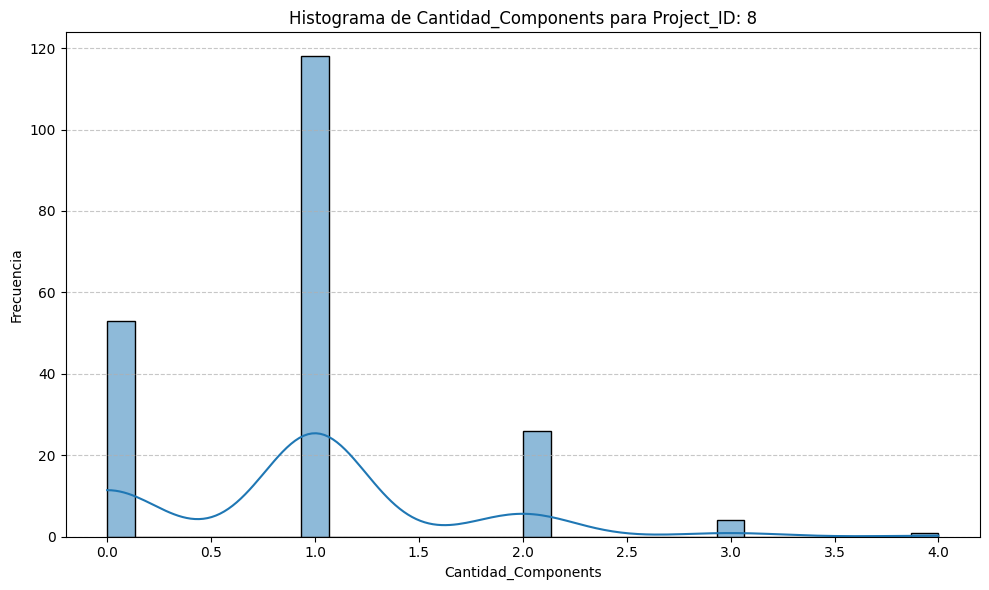

/tmp/ipykernel_5635/1808863845.py:11: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(subset_df[column_to_histogram], bins=30, kde=True, palette='viridis')


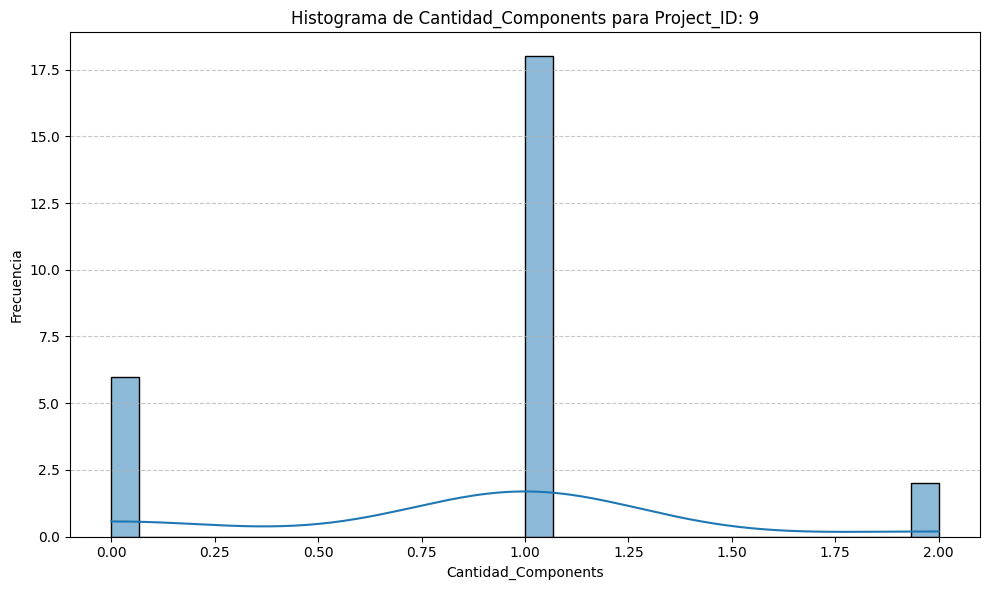

/tmp/ipykernel_5635/1808863845.py:11: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(subset_df[column_to_histogram], bins=30, kde=True, palette='viridis')


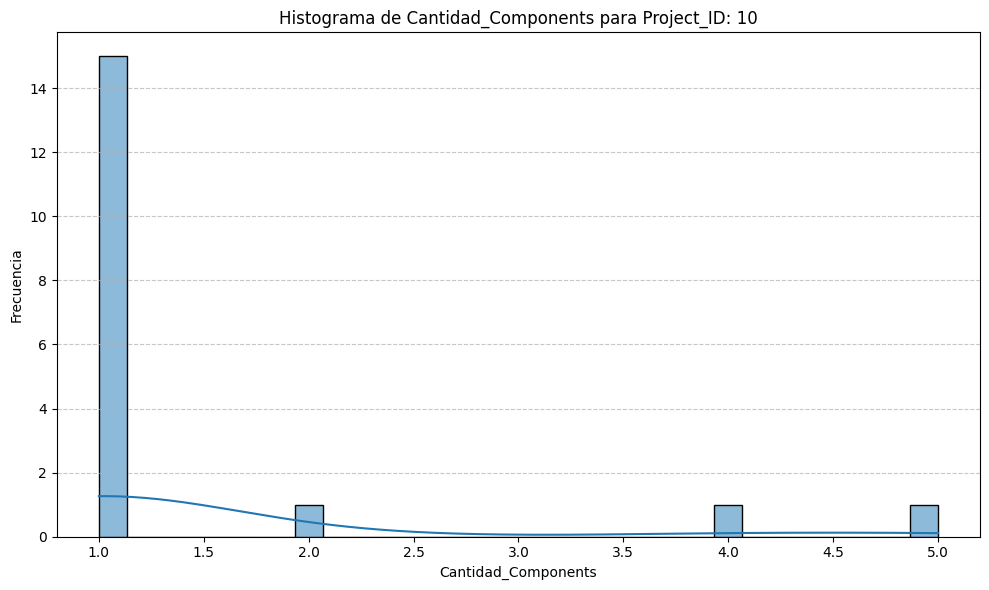

/tmp/ipykernel_5635/1808863845.py:11: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(subset_df[column_to_histogram], bins=30, kde=True, palette='viridis')


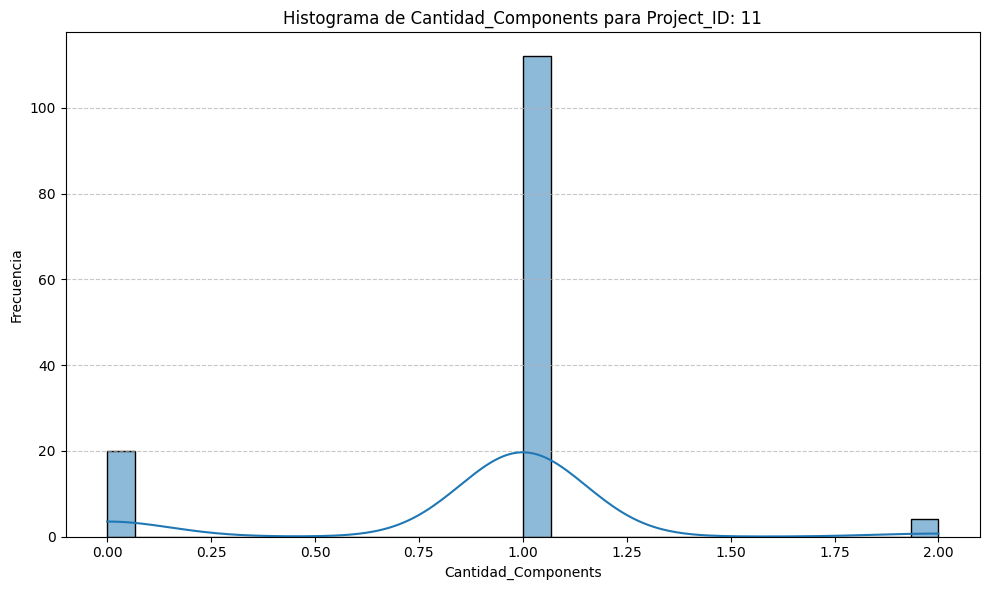

/tmp/ipykernel_5635/1808863845.py:11: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(subset_df[column_to_histogram], bins=30, kde=True, palette='viridis')


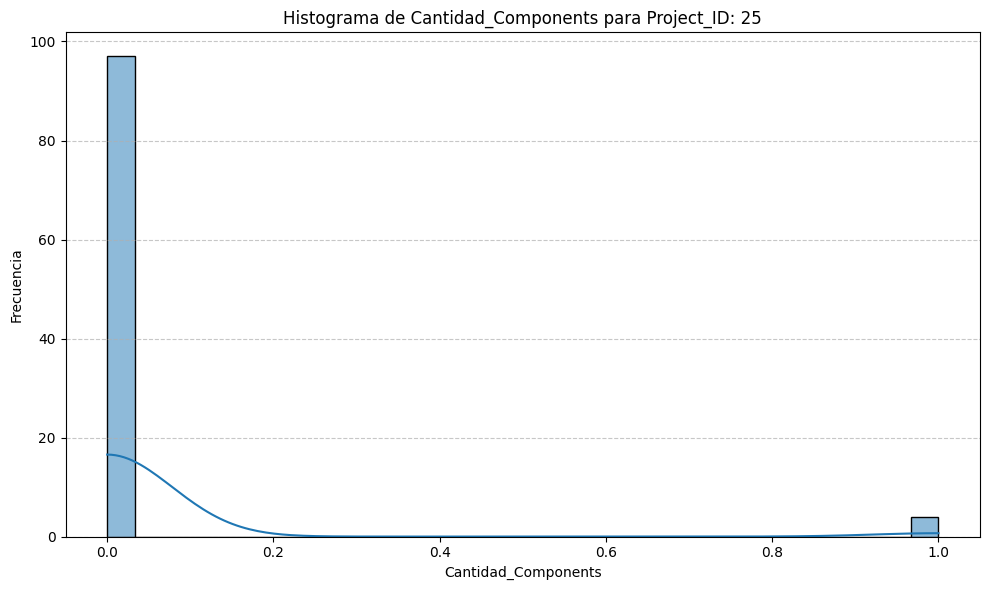

/tmp/ipykernel_5635/1808863845.py:11: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(subset_df[column_to_histogram], bins=30, kde=True, palette='viridis')


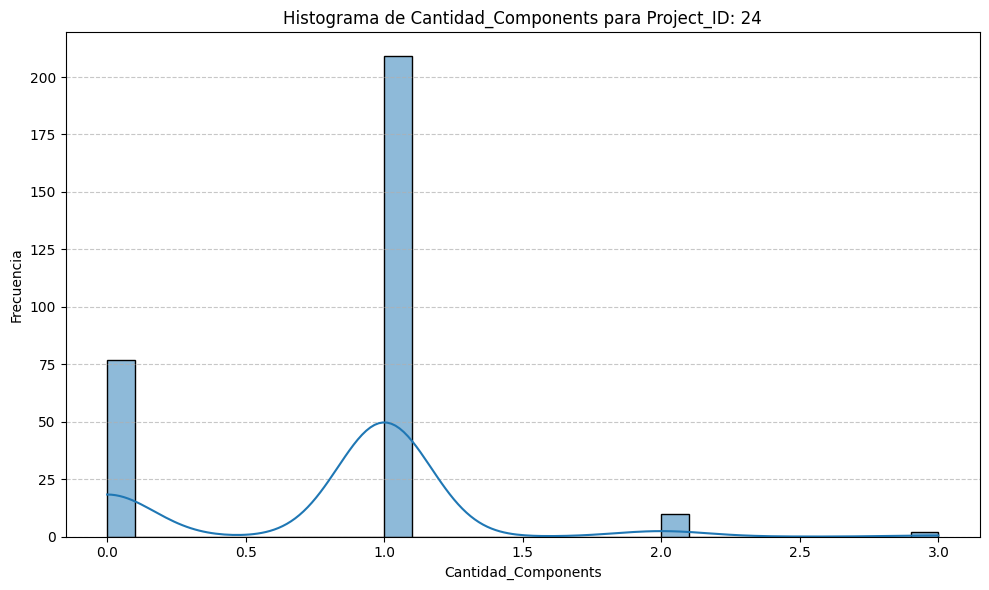

/tmp/ipykernel_5635/1808863845.py:11: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(subset_df[column_to_histogram], bins=30, kde=True, palette='viridis')


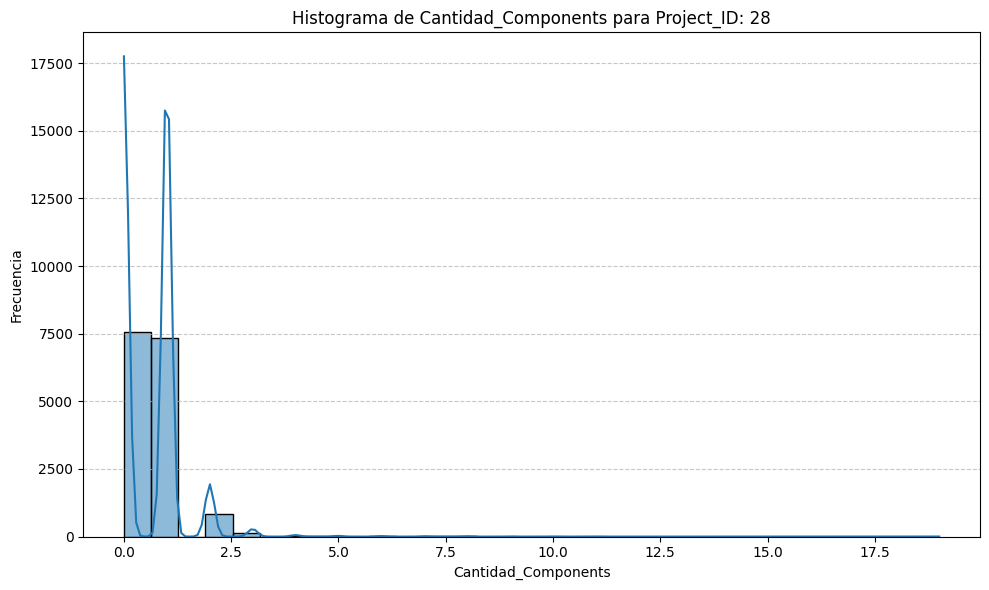

/tmp/ipykernel_5635/1808863845.py:11: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(subset_df[column_to_histogram], bins=30, kde=True, palette='viridis')


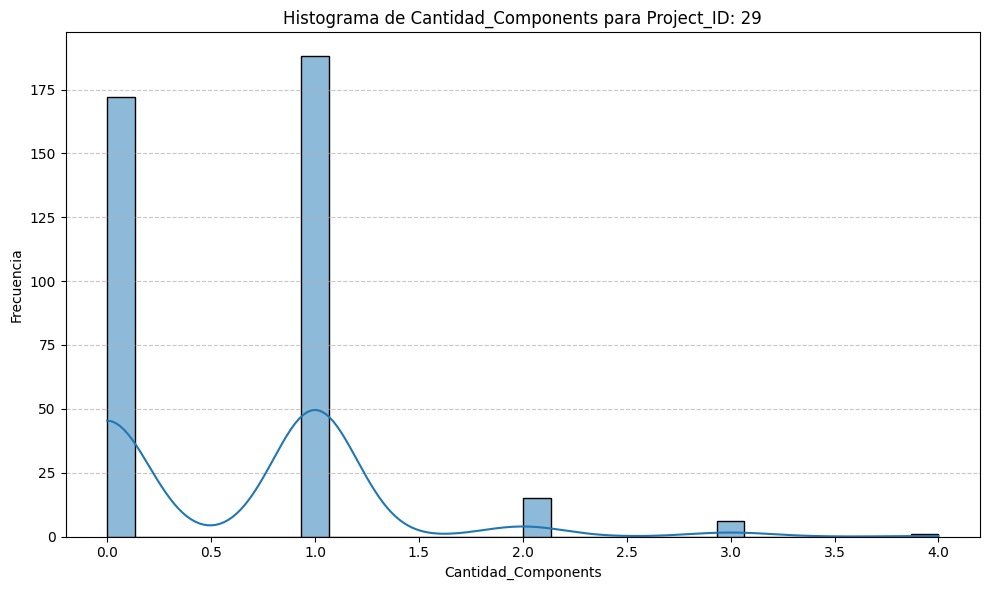

/tmp/ipykernel_5635/1808863845.py:11: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(subset_df[column_to_histogram], bins=30, kde=True, palette='viridis')


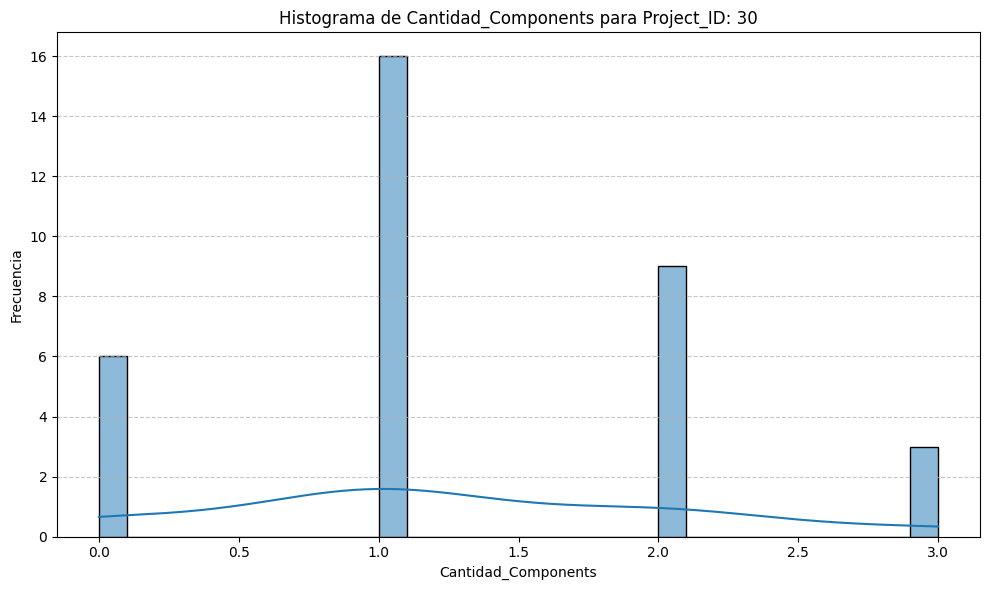

/tmp/ipykernel_5635/1808863845.py:11: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(subset_df[column_to_histogram], bins=30, kde=True, palette='viridis')


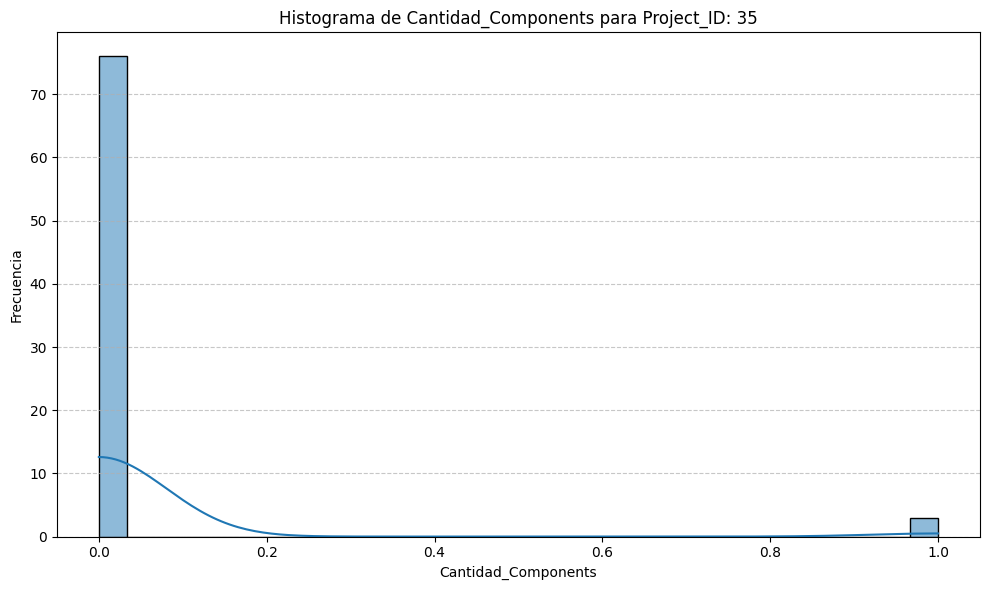

/tmp/ipykernel_5635/1808863845.py:11: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(subset_df[column_to_histogram], bins=30, kde=True, palette='viridis')


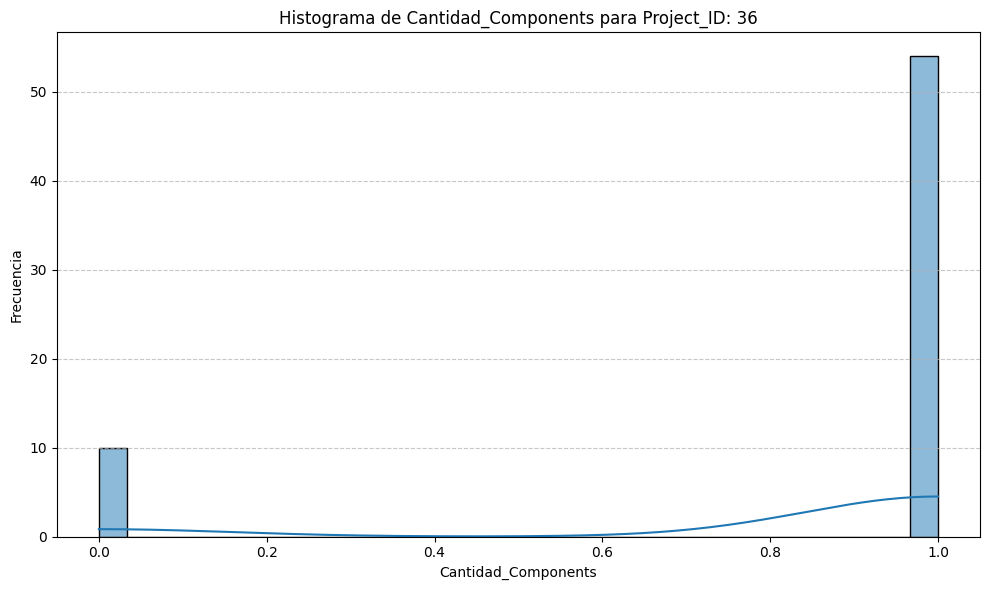

/tmp/ipykernel_5635/1808863845.py:11: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(subset_df[column_to_histogram], bins=30, kde=True, palette='viridis')


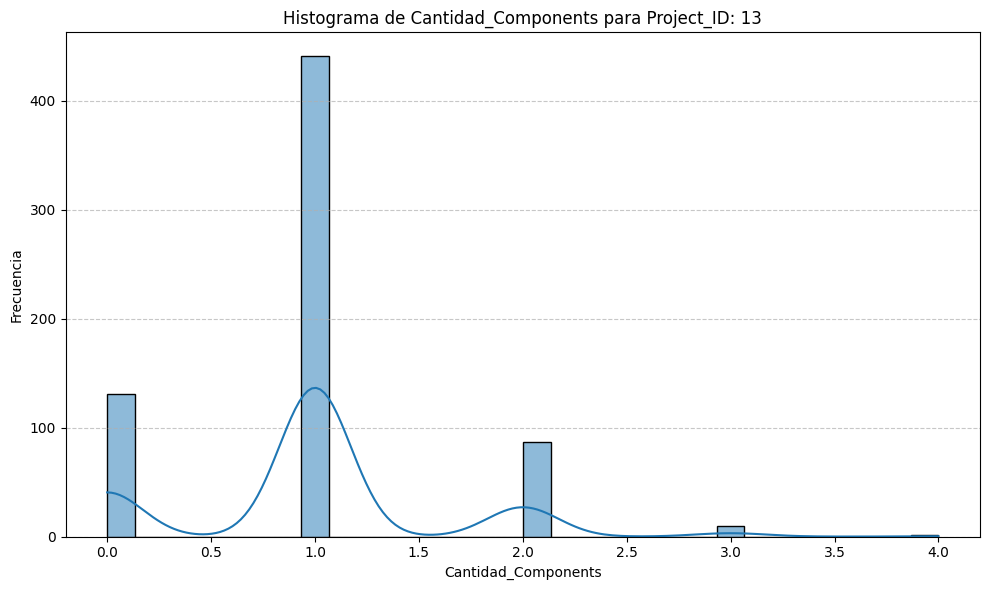

/tmp/ipykernel_5635/1808863845.py:11: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(subset_df[column_to_histogram], bins=30, kde=True, palette='viridis')


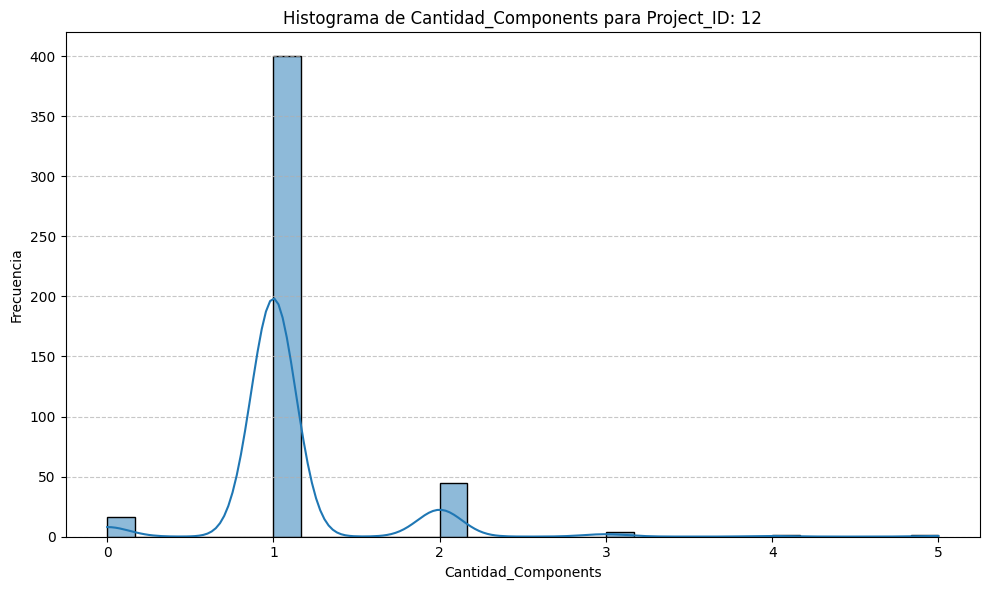

/tmp/ipykernel_5635/1808863845.py:11: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(subset_df[column_to_histogram], bins=30, kde=True, palette='viridis')


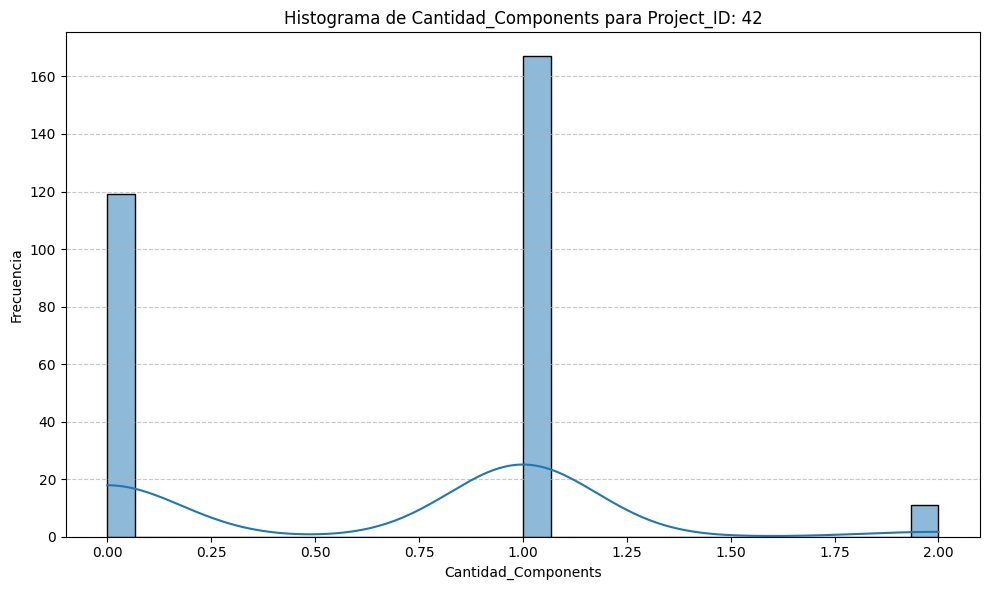

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

column_to_histogram = 'Cantidad_Components'
unique_project_ids = df['Project_ID'].unique()

for project_id in unique_project_ids:
  subset_df = df[df['Project_ID'] == project_id]

  plt.figure(figsize=(10, 6))
  sns.histplot(subset_df[column_to_histogram], bins=30, kde=True, palette='viridis')
  plt.title(f"Histograma de {column_to_histogram} para Project_ID: {project_id}")
  plt.xlabel(column_to_histogram)
  plt.ylabel('Frecuencia')
  plt.grid(axis='y', linestyle='--', alpha=0.7)
  plt.tight_layout()
  plt.show()

In [ ]:
print("Completando los valores nulos en la columna 'Components_Lista' con 'No Component'...")
df['Components_Lista'] = df['Components_Lista'].fillna('No Component')
print("Valores nulos en 'Components_Lista' completados. Mostrando el conteo de valores actualizado:")
display(df['Components_Lista'].value_counts(dropna=False).head(10))

Completando los valores nulos en la columna 'Components_Lista' con 'No Component'...
Valores nulos en 'Components_Lista' completados. Mostrando el conteo de valores actualizado:


,count
Components_Lista,
No Component,10435
Qserv,774
SUIT,629
afw,342
daf_butler,281
ts_main_telescope,276
Stack Documentation and UX,272
pipe_tasks,181
Firefly,181


In [ ]:
print("Completando los valores nulos en la columna 'Priority' con 'No Priority'...")
df['Priority'] = df['Priority'].fillna('No Priority')
print("Valores nulos en 'Priority' completados. Mostrando el conteo de valores actualizado:")
display(df['Priority'].value_counts(dropna=False).head(10))

Completando los valores nulos en la columna 'Priority' con 'No Priority'...
Valores nulos en 'Priority' completados. Mostrando el conteo de valores actualizado:


,count
Priority,
No Priority,15969
Minor,2594
High,967
Medium,827
Major,750
Critical,258
Low,250
To be reviewed,38
Trivial,33


In [ ]:
df['Description_Estimacion_Inicial'] = df['Description_Estimacion_Inicial'].fillna('No Description')
print("Valores nulos en 'Description_Estimacion_Inicial' completados. Mostrando el conteo de valores actualizado:")
display(df['Description_Estimacion_Inicial'].value_counts(dropna=False).head(10))

Valores nulos en 'Description_Estimacion_Inicial' completados. Mostrando el conteo de valores actualizado:


,count
Description_Estimacion_Inicial,
No Description,2791
"""""""No description provided! This ticket had been created automatically Primavera ID: None""""""",102
No description provided!\n\nThis ticket had been created automatically\nPrimavera ID: None,15
"""""""Collect, record, and verify financial data for the LSST Data Facility. Deliverable consists of a monthly financial report delivered to the Project Controls Specialist.""""""",14
"""""""Put on the guide as a section in an 'input-stream' wiki page. """"""",12
"""""""Collect, record, and verify technical progress data and narratives for the LSST Data Facility. Deliverable consists of updated JIRA issues and a Technical Progress Report.""""""",12
"""""""See https://confluence.lsstcorp.org/display/DM/Qserv+Release+Procedure for recipe.""""""",12
"""""""May not have any work associated with it, but is an {{lsst_distrib}} dependency. Investigate and update SP.""""""",10
"""""""Story added so epic is tracked by project controls.""""""",9


### 7. Manejo de Outliers en 'Story_Point_Original' (Z-score)


In [ ]:
import numpy as np

# Eliminar Story Points negativos
df = df[df['Story_Point_Original'] >= 0].copy()

# Z-score por proyecto
z_score_threshold = 3

media = df.groupby('Project_ID')['Story_Point_Original'].transform('mean')
std = df.groupby('Project_ID')['Story_Point_Original'].transform('std')

std = std.replace(0, np.nan)

z_scores = (
    (df['Story_Point_Original'] - media) / std
)

mask_outlier = z_scores.abs() > z_score_threshold
mask_outlier = mask_outlier.fillna(False)

print(f"Outliers eliminados: {mask_outlier.sum()}")

df = df.loc[~mask_outlier].copy()

print("Forma final:", df.shape)

Outliers eliminados: 132
Forma final: (21600, 9)


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, confusion_matrix, average_precision_score, roc_auc_score, balanced_accuracy_score
import warnings
warnings.filterwarnings('ignore') # Suppress warnings, especially from scikit-learn about convergence

if 'df' in locals() and df is not None:
    # 1. Definir la variable objetivo
    y = df['Story_Point_Changed_After_Estimation'].astype(int)

    # 2. Crear la característica de texto combinado en una copia del DataFrame para X
    df_model = df.copy()
    df_model['Texto_Combinado'] = (
        df_model['Title_Estimacion_Inicial'].fillna('') +''+
        df_model['Description_Estimacion_Inicial'].fillna('')
    )
    # Ensure 'Components_Lista' is treated as a string for TfidfVectorizer
    df_model['Components_Lista_Texto'] = df_model['Components_Lista'].fillna('').astype(str)

    # Fill NaN in 'Priority' with 'No Priority'
    df_model['Priority'] = df_model['Priority'].fillna('No Priority')

    # 3. Definir características numéricas, categóricas y de texto
    numerical_features = [
        'Story_Point_Original',
    ]
    categorical_features = [
        'Priority'
    ]

    text_feature_col = 'Texto_Combinado'
    components_text_col = 'Components_Lista_Texto' # New text feature for components

    # Combinar todas las características en un solo DataFrame para X
    features_to_use = numerical_features + categorical_features + [text_feature_col] + [components_text_col] # Updated features
    X = df_model[features_to_use]

    # 4. Dividir los datos en sets de entrenamiento y test
    # Usamos test_size=0.20 y stratify=y para consistencia con el modelo previo
    X_train_raw, X_test_raw, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=42, stratify=y
    )

    print("Forma de los datos después de la división:")
    print(f"X_train_raw: {X_train_raw.shape}, X_test_raw: {X_test_raw.shape}")
    print(f"y_train: {y_train.shape}, y_test: {y_test.shape}")

    # 5. Preprocesamiento usando ColumnTransformer
    preprocessor = ColumnTransformer(
        transformers=[
            ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=True), categorical_features),
            ('text_tfidf_desc_title', TfidfVectorizer(lowercase=True, strip_accents='unicode', sublinear_tf=True,
                                          min_df=3, max_df=0.95, ngram_range=(1, 2), max_features=10000), text_feature_col),
            ('text_tfidf_components', TfidfVectorizer(lowercase=True, strip_accents='unicode', sublinear_tf=True,
                                          min_df=1, max_df=0.95, ngram_range=(1, 1), max_features=1000), components_text_col) # Added for components
        ],
        remainder='passthrough',
        verbose_feature_names_out=False
    )

    # Fit and transform on training data, transform on test data
    X_train = preprocessor.fit_transform(X_train_raw)
    X_test = preprocessor.transform(X_test_raw)

    print("\nDimensiones de las características transformadas:")
    print(f"X_train: {X_train.shape}")
    print(f"X_test: {X_test.shape}")

    # Función para mostrar los resultados
    def mostrar_resultados(y_true, y_pred_values, y_pred_proba=None):
        LABELS = sorted(y_true.unique().astype(str))
        conf_matrix = confusion_matrix(y_true, y_pred_values)
        plt.figure(figsize=(12, 12))
        # Increased font size for annotations and tick labels
        ax = sns.heatmap(conf_matrix, xticklabels=LABELS, yticklabels=LABELS, annot=True, fmt="d",
                    annot_kws={"size": 20})
        ax.tick_params(axis='x', labelsize=18)
        ax.tick_params(axis='y', labelsize=18)
        plt.title("Confusion matrix")
        plt.ylabel('True class', fontsize=22)
        plt.xlabel('Predicted class', fontsize=22)
        plt.show()
        print(classification_report(y_true, y_pred_values))

        balanced_acc = balanced_accuracy_score(y_true, y_pred_values)
        print(f"Balanced Accuracy: {balanced_acc:.4f}")

        if y_pred_proba is not None:
            avg_precision = average_precision_score(y_true, y_pred_proba)
            roc_auc = roc_auc_score(y_true, y_pred_proba)
            print(f"Average Precision (PR-AUC): {avg_precision:.4f}")
            print(f"ROC AUC: {roc_auc:.4f}")
            print("\nPrimeras 10 predicciones - Real vs Predicha vs Probabilidad:")
            sample_df = pd.DataFrame({
                'Real': y_true.reset_index(drop=True).head(10),
                'Predicha': pd.Series(y_pred_values).head(10),
                'Probabilidad': pd.Series(y_pred_proba).head(10)
            })
            display(sample_df)

else:
    print("El DataFrame 'df' no está disponible o no se cargó correctamente.")

Forma de los datos después de la división:
X_train_raw: (17280, 4), X_test_raw: (4320, 4)
y_train: (17280,), y_test: (4320,)

Dimensiones de las características transformadas:
X_train: (17280, 10488)
X_test: (4320, 10488)



--- Entrenando Modelo Baseline (sin class_weight) ---
Modelo de Regresión Logística (baseline) entrenado.

--- Métricas de Evaluación en el Conjunto de Prueba (Modelo Baseline) ---


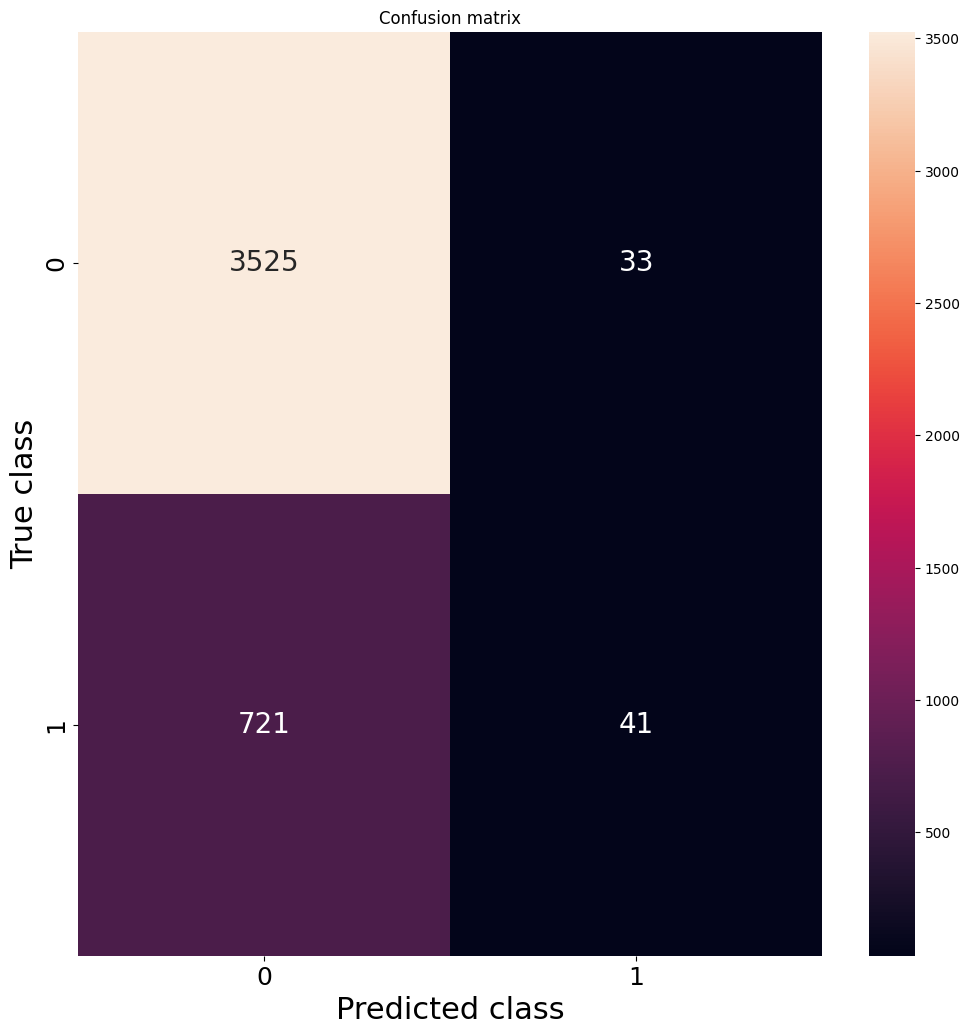

              precision    recall  f1-score   support

           0       0.83      0.99      0.90      3558
           1       0.55      0.05      0.10       762

    accuracy                           0.83      4320
   macro avg       0.69      0.52      0.50      4320
weighted avg       0.78      0.83      0.76      4320

Balanced Accuracy: 0.5223
Average Precision (PR-AUC): 0.3120
ROC AUC: 0.6727

Primeras 10 predicciones - Real vs Predicha vs Probabilidad:


,Real,Predicha,Probabilidad
0,0,0,0.126172
1,1,0,0.160377
2,1,0,0.108727
3,0,0,0.152876
4,0,0,0.104017
5,0,0,0.095196
6,0,0,0.324330
7,0,0,0.172544
8,1,0,0.289808
9,0,0,0.095387


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import warnings
warnings.filterwarnings('ignore') # Suprimir advertencias

# Asumiendo que X_train, X_test, y_train, y_test y la función mostrar_resultados
# han sido definidos en celdas anteriores, como en el código previamente adaptado.
# (Específicamente desde la celda 73171bc6 para los datos y la función mostrar_resultados)

# 1. Función para crear y entrenar el modelo baseline (sin class_weight='balanced')
def run_model(X_train_processed, y_train_data):
    clf = LogisticRegression(
        C=1.0,
        penalty='l2',
        random_state=1,
        solver="saga", # 'saga' es adecuado para datos dispersos y soporta la penalización l2.
        max_iter=2000 # Aumentar max_iter para asegurar la convergencia
    )
    clf.fit(X_train_processed, y_train_data)
    return clf

# 2. Ejecutar el modelo baseline
print("\n--- Entrenando Modelo Baseline (sin class_weight) ---")
# Usar las variables X_train, y_train disponibles globalmente que ya están preprocesadas
model_baseline = run_model(X_train, y_train)
print("Modelo de Regresión Logística (baseline) entrenado.")

# 3. Realizar predicciones y mostrar resultados
# Usar X_test y la función mostrar_resultados disponibles globalmente
pred_y_baseline = model_baseline.predict(X_test)
pred_proba_baseline = model_baseline.predict_proba(X_test)[:, 1]
print("\n--- Métricas de Evaluación en el Conjunto de Prueba (Modelo Baseline) ---")
mostrar_resultados(y_test, pred_y_baseline, pred_proba_baseline)




--- Realizando Randomized Search para Regresión Logística --- (Optimizado por Average Precision)
Fitting 3 folds for each of 10 candidates, totalling 30 fits

--- Resultados del Randomized Search --- (Optimizado por Average Precision)
Mejores parámetros: {'C': np.float64(1.0129197956845732), 'class_weight': 'balanced', 'penalty': 'l1', 'solver': 'liblinear'}
Mejor puntuación (Average Precision): 0.2780
Modelo de Regresión Logística (Randomized Search) entrenado con los mejores parámetros.

--- Métricas de Evaluación en el Conjunto de Prueba (Modelo Randomized Search) --- (Optimizado por Average Precision)


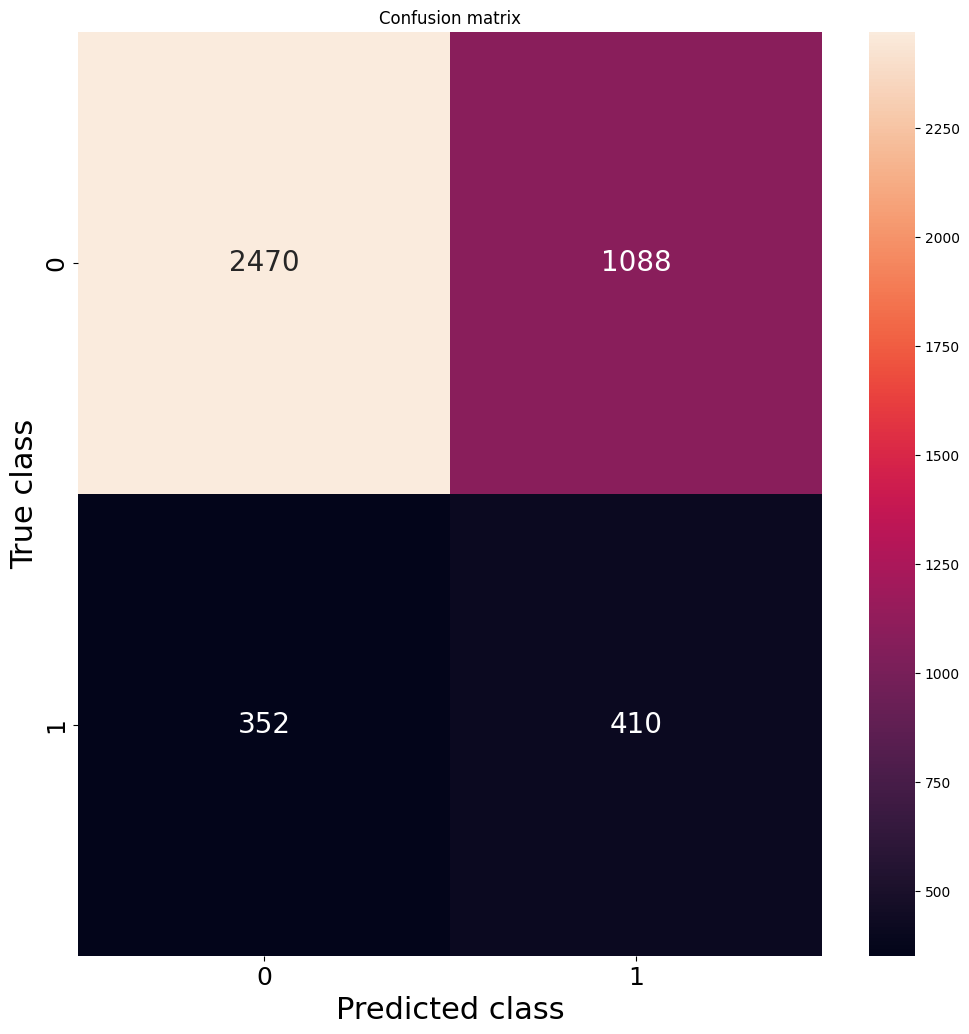

              precision    recall  f1-score   support

           0       0.88      0.69      0.77      3558
           1       0.27      0.54      0.36       762

    accuracy                           0.67      4320
   macro avg       0.57      0.62      0.57      4320
weighted avg       0.77      0.67      0.70      4320

Balanced Accuracy: 0.6161
Average Precision (PR-AUC): 0.2889
ROC AUC: 0.6615

Primeras 10 predicciones - Real vs Predicha vs Probabilidad:


,Real,Predicha,Probabilidad
0,0,0,0.311267
1,1,0,0.310139
2,1,0,0.291988
3,0,1,0.641039
4,0,0,0.323173
5,0,0,0.331426
6,0,1,0.570125
7,0,0,0.419212
8,1,1,0.584407
9,0,0,0.247645


In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, average_precision_score, roc_auc_score, recall_score
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import loguniform
import warnings
warnings.filterwarnings('ignore')

if 'X_train' in locals() and 'y_train' in locals() and 'X_test' in locals() and 'y_test' in locals() and 'mostrar_resultados' in globals():
    print("\n--- Realizando Randomized Search para Regresión Logística --- (Optimizado por Average Precision)")

    # CAMBIO: solver='saga' -> 'liblinear' (el cambio de mayor impacto en velocidad).
    # liblinear soporta l1 y l2 igual que saga, pero converge mucho más rápido en
    # datos dispersos de alta dimensión (TF-IDF) mediante descenso de coordenadas.
    log_reg = LogisticRegression(random_state=1, max_iter=500)  # max_iter bajado también, liblinear lo necesita menos

    param_distributions = {
        'C': loguniform(0.001, 100),
        'penalty': ['l1', 'l2'],
        'solver': ['liblinear'],  # CAMBIO
        'class_weight': [None, 'balanced']
    }

    random_search = RandomizedSearchCV(
        estimator=log_reg,
        param_distributions=param_distributions,
        n_iter=10,
        cv=3,
        scoring='average_precision', # REVERTIDO: Optimización por Average Precision
        verbose=2,
        random_state=42,
        n_jobs=-1
    )

    random_search.fit(X_train, y_train)

    print("\n--- Resultados del Randomized Search --- (Optimizado por Average Precision)")
    print(f"Mejores parámetros: {random_search.best_params_}")
    print(f"Mejor puntuación (Average Precision): {random_search.best_score_:.4f}")

    best_model_rs = random_search.best_estimator_
    print("Modelo de Regresión Logística (Randomized Search) entrenado con los mejores parámetros.")

    pred_y_random_search = best_model_rs.predict(X_test)
    pred_proba_random_search = best_model_rs.predict_proba(X_test)[:, 1]

    print("\n--- Métricas de Evaluación en el Conjunto de Prueba (Modelo Randomized Search) --- (Optimizado por Average Precision)")
    mostrar_resultados(y_test, pred_y_random_search, pred_proba_random_search)

else:
    print("Las variables X_train, y_train, X_test, y_test o la función mostrar_resultados no están disponibles.")


--- Entrenando Modelo con class_weight='balanced' ---
Modelo de Regresión Logística (balanced) entrenado.

--- Métricas de Evaluación en el Conjunto de Prueba (balanced) ---


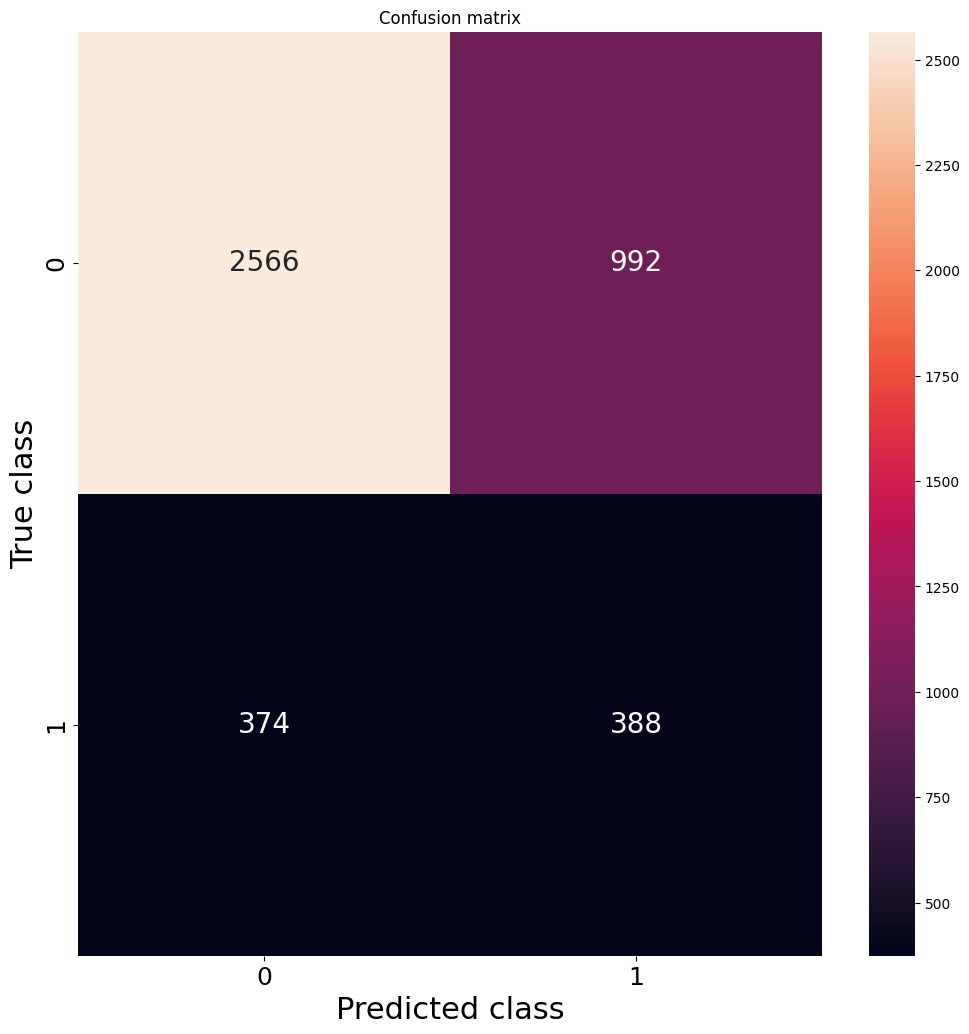

              precision    recall  f1-score   support

           0       0.87      0.72      0.79      3558
           1       0.28      0.51      0.36       762

    accuracy                           0.68      4320
   macro avg       0.58      0.62      0.58      4320
weighted avg       0.77      0.68      0.71      4320

Balanced Accuracy: 0.6152
Average Precision (PR-AUC): 0.3000
ROC AUC: 0.6652

Primeras 10 predicciones - Real vs Predicha vs Probabilidad:


,Real,Predicha,Probabilidad
0,0,0,0.335422
1,1,0,0.388307
2,1,0,0.339284
3,0,0,0.459206
4,0,0,0.258948
5,0,0,0.265403
6,0,1,0.679923
7,0,0,0.448529
8,1,1,0.598695
9,0,0,0.220239


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import warnings
warnings.filterwarnings('ignore') # Suprimir advertencias

# Asumiendo que X_train, X_test, y_train, y_test y la función mostrar_resultados
# han sido definidos en celdas anteriores, como en el código previamente adaptado.

# 1. Función para crear y entrenar el modelo con class_weight='balanced'
def run_model_balanced(X_train_processed, y_train_data):
    clf = LogisticRegression(
        C=1.0,
        penalty='l2',
        random_state=1,
        solver="saga", # Usar 'saga' para consistencia y soporte de 'balanced' class_weight
        max_iter=2000, # Aumentar max_iter para asegurar convergencia
        class_weight="balanced"
    )
    clf.fit(X_train_processed, y_train_data)
    return clf

# 2. Ejecutar el modelo con class_weight='balanced'
print("\n--- Entrenando Modelo con class_weight='balanced' ---")
model_balanced = run_model_balanced(X_train, y_train)
print("Modelo de Regresión Logística (balanced) entrenado.")

# 3. Realizar predicciones y mostrar resultados
pred_y_balanced = model_balanced.predict(X_test)
pred_proba_balanced = model_balanced.predict_proba(X_test)[:, 1]
print("\n--- Métricas de Evaluación en el Conjunto de Prueba (balanced) ---")
mostrar_resultados(y_test, pred_y_balanced, pred_proba_balanced)


Distribución antes del undersampling: Counter({0: 14233, 1: 3047})
Distribución después del undersampling: Counter({0: 6094, 1: 3047})

--- Entrenando Modelo con datos remuestreados (NearMiss, desde celda uvUjNRR6rHid) ---
Modelo de Regresión Logística (NearMiss) entrenado.

--- Métricas de Evaluación en el Conjunto de Prueba (Modelo NearMiss, desde celda uvUjNRR6rHid) ---


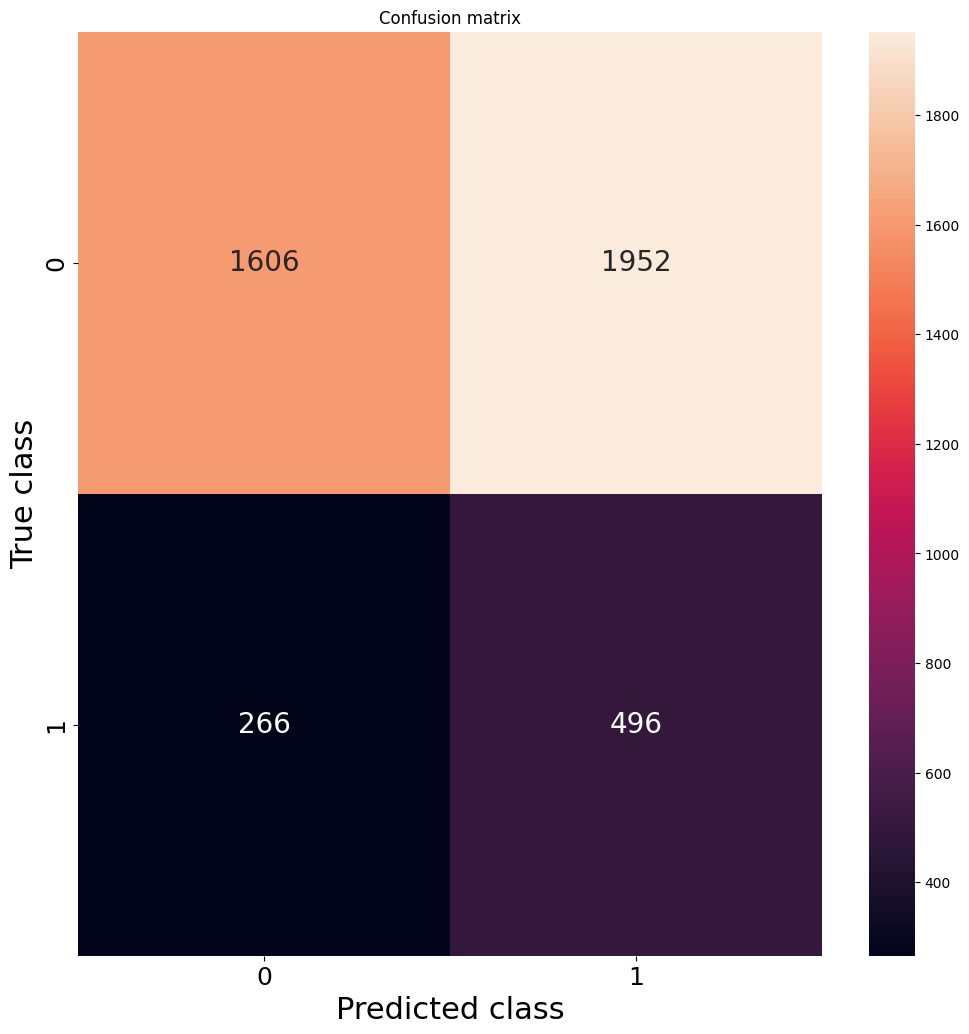

              precision    recall  f1-score   support

           0       0.86      0.45      0.59      3558
           1       0.20      0.65      0.31       762

    accuracy                           0.49      4320
   macro avg       0.53      0.55      0.45      4320
weighted avg       0.74      0.49      0.54      4320

Balanced Accuracy: 0.5511
Average Precision (PR-AUC): 0.2300
ROC AUC: 0.5793

Primeras 10 predicciones - Real vs Predicha vs Probabilidad:


,Real,Predicha,Probabilidad
0,0,0,0.311195
1,1,0,0.396337
2,1,0,0.480901
3,0,1,0.633739
4,0,1,0.556255
5,0,0,0.440367
6,0,1,0.571791
7,0,1,0.633559
8,1,1,0.673790
9,0,1,0.576895


In [ ]:
from imblearn.under_sampling import NearMiss
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import warnings
warnings.filterwarnings('ignore')

# Asegurarse de que X_train, y_train, X_test, y_test están disponibles del preprocesamiento anterior.
# Asegurarse de que run_model_balanced y mostrar_resultados están definidos en celdas anteriores.

# 1. Aplicar undersampling con NearMiss
print(f"Distribución antes del undersampling: {Counter(y_train)}")
us = NearMiss(sampling_strategy=0.5, n_neighbors=3, version=2)
X_train_res, y_train_res = us.fit_resample(X_train, y_train)
print(f"Distribución después del undersampling: {Counter(y_train_res)}")

# 2. Entrenar el modelo con los datos remuestreados
print("\n--- Entrenando Modelo con datos remuestreados")
# Usar la función run_model_balanced definida previamente
model_resampled_uv = run_model_balanced(X_train_res, y_train_res)
print("Modelo de Regresión Logística (NearMiss) entrenado.")

# 3. Realizar predicciones y mostrar resultados en el conjunto de prueba original
pred_y_resampled_uv = model_resampled_uv.predict(X_test)
pred_proba_resampled_uv = model_resampled_uv.predict_proba(X_test)[:, 1]
print("\n--- Métricas de Evaluación en el Conjunto de Prueba")
mostrar_resultados(y_test, pred_y_resampled_uv, pred_proba_resampled_uv)


Distribución antes del oversampling: Counter({0: 14233, 1: 3047})
Distribución después del oversampling: Counter({0: 14233, 1: 7116})

--- Entrenando Modelo con datos remuestreados (RandomOverSampler) ---
Modelo de Regresión Logística (RandomOverSampler) entrenado.

--- Métricas de Evaluación en el Conjunto de Prueba (Modelo RandomOverSampler) ---


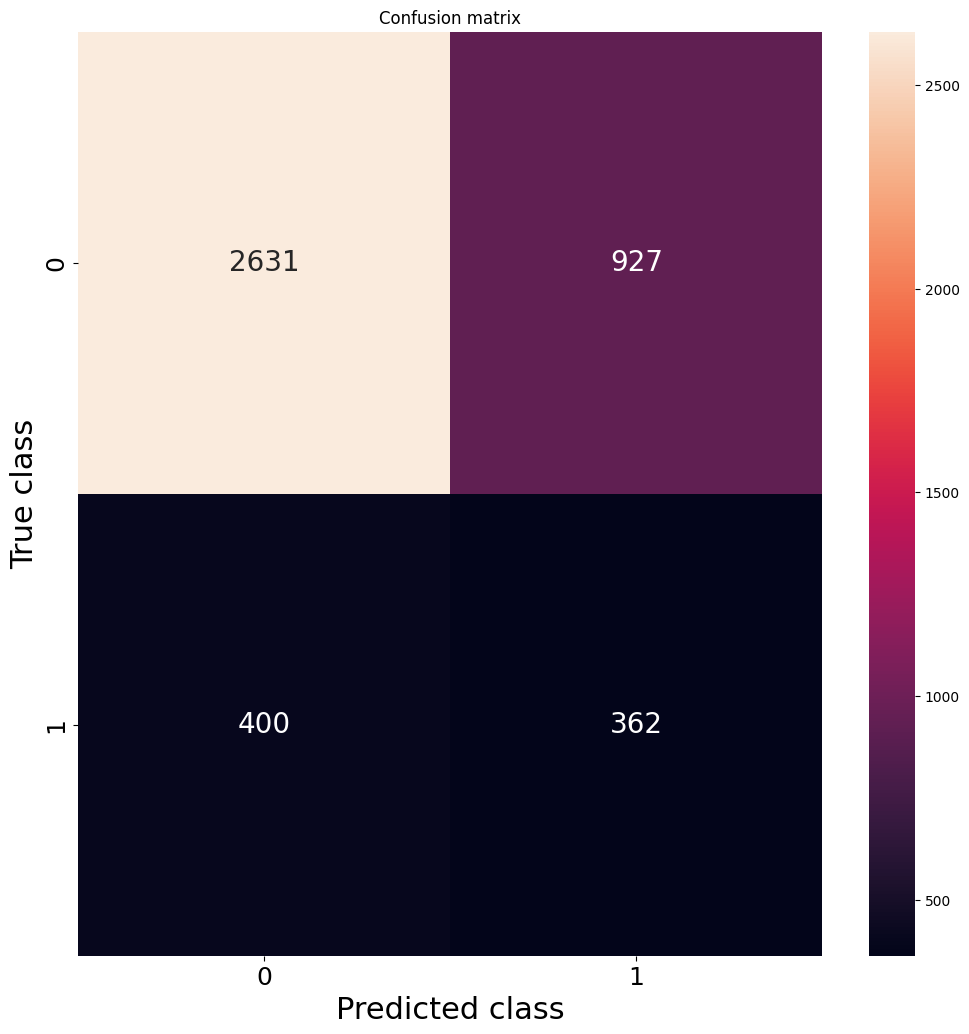

              precision    recall  f1-score   support

           0       0.87      0.74      0.80      3558
           1       0.28      0.48      0.35       762

    accuracy                           0.69      4320
   macro avg       0.57      0.61      0.58      4320
weighted avg       0.76      0.69      0.72      4320

Balanced Accuracy: 0.6073
Average Precision (PR-AUC): 0.2928
ROC AUC: 0.6600

Primeras 10 predicciones - Real vs Predicha vs Probabilidad:


,Real,Predicha,Probabilidad
0,0,0,0.296565
1,1,0,0.334974
2,1,0,0.322549
3,0,0,0.441724
4,0,0,0.221291
5,0,0,0.239554
6,0,1,0.698948
7,0,0,0.439926
8,1,1,0.551567
9,0,0,0.180738


In [ ]:
from imblearn.over_sampling import RandomOverSampler
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import warnings
warnings.filterwarnings('ignore')

# Asegurarse de que X_train, y_train, X_test, y_test están disponibles del preprocesamiento anterior.
# Asegurarse de que run_model_balanced y mostrar_resultados están definidos en celdas anteriores.

# 1. Aplicar oversampling con RandomOverSampler
print(f"Distribución antes del oversampling: {Counter(y_train)}")
os = RandomOverSampler(sampling_strategy=0.5, random_state=42) # Usar sampling_strategy y random_state para reproducibilidad
X_train_res, y_train_res = os.fit_resample(X_train, y_train)
print(f"Distribución después del oversampling: {Counter(y_train_res)}")

# 2. Entrenar el modelo con los datos remuestreados
print("\n--- Entrenando Modelo con datos remuestreados (RandomOverSampler) ---")
# Usar la función run_model_balanced definida previamente
model_oversampled = run_model_balanced(X_train_res, y_train_res)
print("Modelo de Regresión Logística (RandomOverSampler) entrenado.")

# 3. Realizar predicciones y mostrar resultados en el conjunto de prueba original
pred_y_oversampled = model_oversampled.predict(X_test)
pred_proba_oversampled = model_oversampled.predict_proba(X_test)[:, 1]
print("\n--- Métricas de Evaluación en el Conjunto de Prueba (Modelo RandomOverSampler) ---")
mostrar_resultados(y_test, pred_y_oversampled, pred_proba_oversampled)


### 9. Modelo con Sentence Embeddings


--- Modelo con Sentence Embeddings de Título y Descripción Combinados ---
Forma de los datos después de la división (ST Título y Descripción):
X_train_raw_desc_st: (17280, 3), X_test_raw_desc_st: (4320, 3)
y_train_desc_st: (17280,), y_test_desc_st: (4320,)

Cargando modelo Sentence Transformer...


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Generando embeddings del título y la descripción combinados...


Batches:   0%|          | 0/270 [00:00<?, ?it/s]

Batches:   0%|          | 0/68 [00:00<?, ?it/s]

Forma de los embeddings de entrenamiento: (17280, 384)
Forma de los embeddings de prueba: (4320, 384)
Forma de las características num/cat transformadas (entrenamiento): (17280, 12)
Forma de las características num/cat transformadas (prueba): (4320, 12)

Dimensiones de las características combinadas (ST Título y Descripción):
X_train_processed_st: (17280, 396)
X_test_processed_st: (4320, 396)

--- Entrenando Modelo con datos (ST Título y Descripción) y class_weight='balanced' ---
Modelo de Regresión Logística (ST Título y Descripción) entrenado.

--- Métricas de Evaluación en el Conjunto de Prueba (Modelo ST Título y Descripción) ---


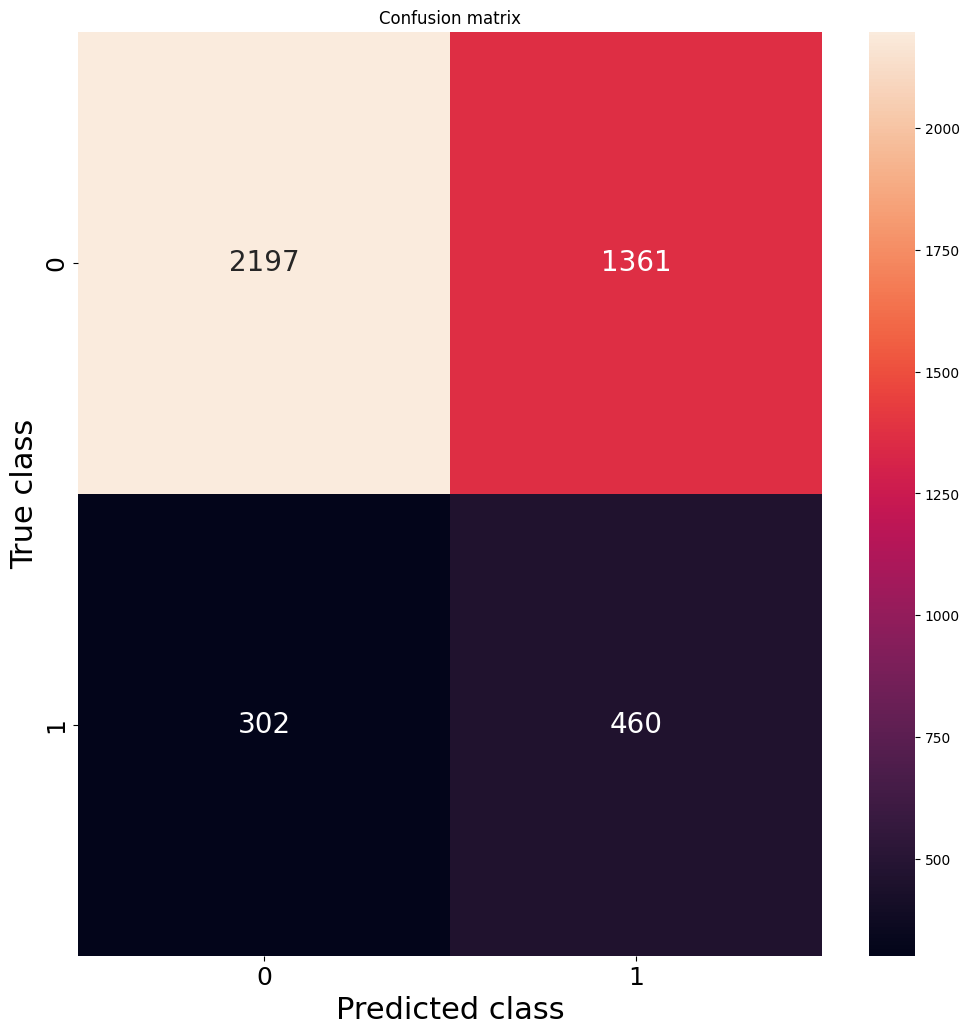

              precision    recall  f1-score   support

           0       0.88      0.62      0.73      3558
           1       0.25      0.60      0.36       762

    accuracy                           0.62      4320
   macro avg       0.57      0.61      0.54      4320
weighted avg       0.77      0.62      0.66      4320

Balanced Accuracy: 0.6106
Average Precision (PR-AUC): 0.2733
ROC AUC: 0.6471

Primeras 10 predicciones - Real vs Predicha vs Probabilidad:


,Real,Predicha,Probabilidad
0,0,1,0.504925
1,1,1,0.578820
2,1,1,0.534482
3,0,0,0.263242
4,0,0,0.478968
5,0,0,0.251885
6,0,1,0.720129
7,0,0,0.458643
8,1,1,0.664746
9,0,0,0.243784


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from sentence_transformers import SentenceTransformer
import warnings
warnings.filterwarnings('ignore') # Suprimir advertencias

if 'df' in locals() and df is not None:
    print("\n--- Modelo con Sentence Embeddings de Título y Descripción Combinados ---")

    # 1. Definir la variable objetivo (usamos y_desc del modelo anterior para consistencia)
    y_desc_st = df['Story_Point_Changed_After_Estimation'].astype(int)

    # 2. Crear una copia del DataFrame para X y asegurar el manejo de NaN en 'Priority'
    df_model_desc_only_st = df.copy()
    df_model_desc_only_st['Priority'] = df_model_desc_only_st['Priority'].fillna('No Priority')

    # Combinar 'Title_Estimacion_Inicial' y 'Description_Estimacion_Inicial'
    df_model_desc_only_st['Title_Description_Combined_ST'] = \
        df_model_desc_only_st['Title_Estimacion_Inicial'].fillna('') + ' ' + \
        df_model_desc_only_st['Description_Estimacion_Inicial'].fillna('')

    # 3. Definir características numéricas, categóricas y de texto para este modelo
    numerical_features_desc_st = [
        'Story_Point_Original',
    ]
    categorical_features_desc_st = [
        'Priority'
    ]
    combined_text_feature_col_st = 'Title_Description_Combined_ST' # Usar la nueva columna combinada

    # Combinar todas las características en un solo DataFrame para X
    features_to_use_desc_st = numerical_features_desc_st + categorical_features_desc_st + [combined_text_feature_col_st]
    X_st = df_model_desc_only_st[features_to_use_desc_st]

    # 4. Dividir los datos en sets de entrenamiento y test
    X_train_raw_desc_st, X_test_raw_desc_st, y_train_desc_st, y_test_desc_st = train_test_split(
        X_st, y_desc_st, test_size=0.20, random_state=42, stratify=y_desc_st
    )

    print("Forma de los datos después de la división (ST Título y Descripción):")
    print(f"X_train_raw_desc_st: {X_train_raw_desc_st.shape}, X_test_raw_desc_st: {X_test_raw_desc_st.shape}")
    print(f"y_train_desc_st: {y_train_desc_st.shape}, y_test_desc_st: {y_test_desc_st.shape}")

    # 5. Cargar el modelo Sentence Transformer y generar embeddings
    print("\nCargando modelo Sentence Transformer...")
    st_model = SentenceTransformer('all-MiniLM-L6-v2') # Cambiado a un modelo más rápido y en inglés
    print("Generando embeddings del título y la descripción combinados...")
    # Asegurarse de que los textos no son NaN antes de codificar
    train_texts = X_train_raw_desc_st[combined_text_feature_col_st].fillna('').tolist()
    test_texts = X_test_raw_desc_st[combined_text_feature_col_st].fillna('').tolist()

    X_train_desc_embeddings = st_model.encode(train_texts, show_progress_bar=True, batch_size=64)
    X_test_desc_embeddings = st_model.encode(test_texts, show_progress_bar=True, batch_size=64)

    print(f"Forma de los embeddings de entrenamiento: {X_train_desc_embeddings.shape}")
    print(f"Forma de los embeddings de prueba: {X_test_desc_embeddings.shape}")

    # 6. Preprocesamiento para características numéricas y categóricas
    preprocessor_num_cat_st = ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), numerical_features_desc_st),
            ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features_desc_st) # sparse_output=False para concatenar con embeddings densos
        ],
        remainder='drop',
        verbose_feature_names_out=False
    )

    # Transformar características numéricas y categóricas
    X_train_num_cat_st = preprocessor_num_cat_st.fit_transform(X_train_raw_desc_st)
    X_test_num_cat_st = preprocessor_num_cat_st.transform(X_test_raw_desc_st)

    print(f"Forma de las características num/cat transformadas (entrenamiento): {X_train_num_cat_st.shape}")
    print(f"Forma de las características num/cat transformadas (prueba): {X_test_num_cat_st.shape}")

    # 7. Concatenar todas las características
    X_train_processed_st = np.hstack((X_train_num_cat_st, X_train_desc_embeddings))
    X_test_processed_st = np.hstack((X_test_num_cat_st, X_test_desc_embeddings))

    print("\nDimensiones de las características combinadas (ST Título y Descripción):")
    print(f"X_train_processed_st: {X_train_processed_st.shape}")
    print(f"X_test_processed_st: {X_test_processed_st.shape}")

    # 8. Función para crear y entrenar el modelo con class_weight='balanced'
    # Re-utilizamos la función run_model_balanced si ya está definida
    if 'run_model_balanced' not in globals():
        def run_model_balanced(X_train_processed, y_train_data):
            clf = LogisticRegression(
                C=1.0,
                penalty='l2',
                random_state=1,
                solver="saga",
                max_iter=2000,
                class_weight="balanced"
            )
            clf.fit(X_train_processed, y_train_data)
            return clf

    # 9. Entrenar el modelo
    print("\n--- Entrenando Modelo con datos (ST Título y Descripción) y class_weight='balanced' ---")
    model_desc_only_st = run_model_balanced(X_train_processed_st, y_train_desc_st)
    print("Modelo de Regresión Logística (ST Título y Descripción) entrenado.")

    # 10. Realizar predicciones y mostrar resultados
    pred_y_desc_only_st = model_desc_only_st.predict(X_test_processed_st)
    pred_proba_desc_only_st = model_desc_only_st.predict_proba(X_test_processed_st)[:, 1]
    print("\n--- Métricas de Evaluación en el Conjunto de Prueba (Modelo ST Título y Descripción) ---")

    # Re-utilizamos la función mostrar_resultados si ya está definida
    if 'mostrar_resultados' in globals():
        mostrar_resultados(y_test_desc_st, pred_y_desc_only_st, pred_proba_desc_only_st)
    else:
        # Definir una versión simplificada si no está disponible (para evitar errores)
        LABELS_st = y_test_desc_st.unique().astype(str)
        conf_matrix_st = confusion_matrix(y_test_desc_st, pred_y_desc_only_st)
        plt.figure(figsize=(12, 12))
        sns.heatmap(conf_matrix_st, xticklabels=LABELS_st, yticklabels=LABELS_st, annot=True, fmt="d")
        plt.title("Confusion matrix (Modelo ST Título y Descripción)")
        plt.ylabel('True class')
        plt.xlabel('Predicted class')
        plt.show()
        print(classification_report(y_test_desc_st, pred_y_desc_only_st))

else:
    print("El DataFrame 'df' no está disponible o no se cargó correctamente.")


--- Realizando Randomized Search para Regresión Logística con Sentence Embeddings --- (Optimizado por Average Precision)
Fitting 3 folds for each of 10 candidates, totalling 30 fits

--- Resultados del Randomized Search con Sentence Embeddings --- (Optimizado por Average Precision)
Mejores parámetros: {'C': np.float64(1.0129197956845732), 'class_weight': 'balanced', 'penalty': 'l1', 'solver': 'liblinear'}
Mejor puntuación (Average Precision): 0.2599
Modelo de Regresión Logística (Randomized Search con Sentence Embeddings) entrenado con los mejores parámetros.

--- Métricas de Evaluación en el Conjunto de Prueba (Modelo Randomized Search con Sentence Embeddings) --- (Optimizado por Average Precision)


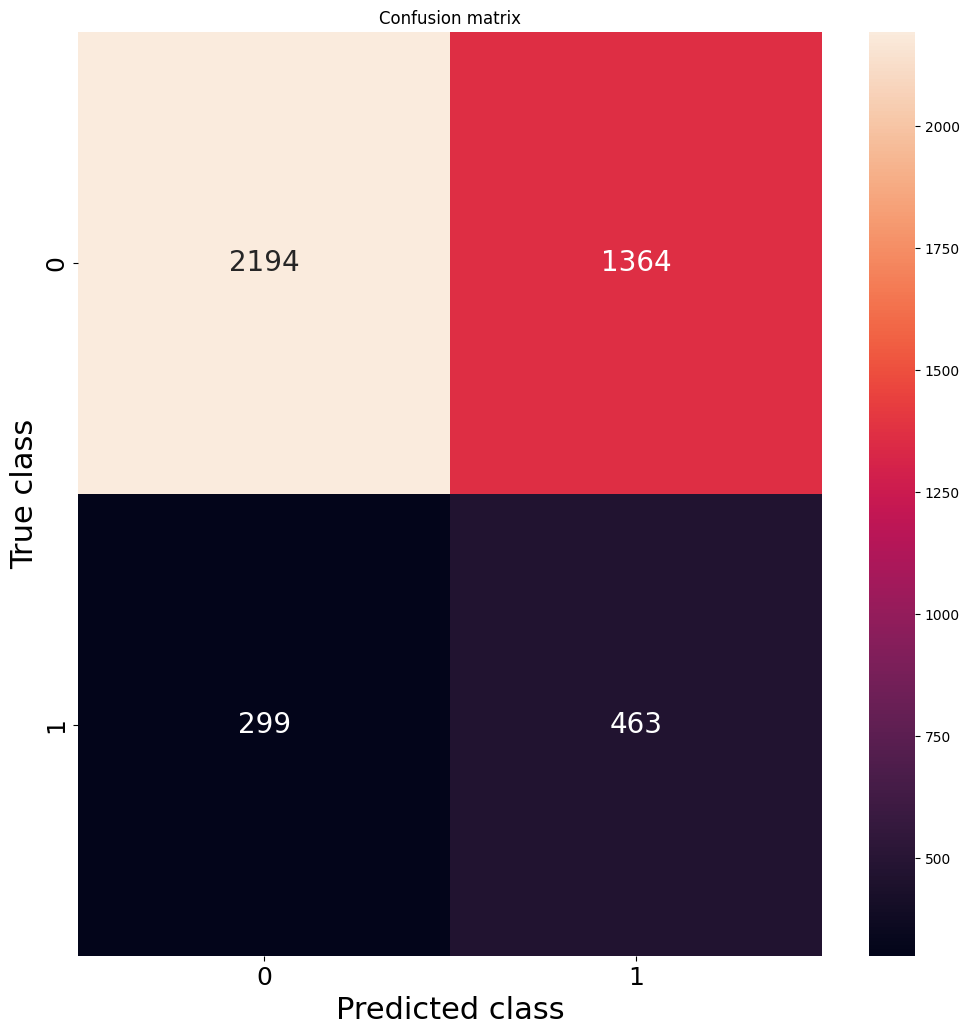

              precision    recall  f1-score   support

           0       0.88      0.62      0.73      3558
           1       0.25      0.61      0.36       762

    accuracy                           0.62      4320
   macro avg       0.57      0.61      0.54      4320
weighted avg       0.77      0.62      0.66      4320

Balanced Accuracy: 0.6121
Average Precision (PR-AUC): 0.2711
ROC AUC: 0.6458

Primeras 10 predicciones - Real vs Predicha vs Probabilidad:


,Real,Predicha,Probabilidad
0,0,1,0.513697
1,1,1,0.586166
2,1,1,0.535293
3,0,0,0.265275
4,0,0,0.496541
5,0,0,0.259365
6,0,1,0.708671
7,0,0,0.458433
8,1,1,0.665580
9,0,0,0.246022


In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, average_precision_score, roc_auc_score, recall_score
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import loguniform
import warnings
warnings.filterwarnings('ignore')

# Modificar la condición para usar las variables del modelo con Sentence Transformers
if 'X_train_processed_st' in locals() and 'y_train_desc_st' in locals() and \
   'X_test_processed_st' in locals() and 'y_test_desc_st' in locals() and 'mostrar_resultados' in globals():
    print("\n--- Realizando Randomized Search para Regresión Logística con Sentence Embeddings --- (Optimizado por Average Precision)")

    # CAMBIO: solver='saga' -> 'liblinear' (el cambio de mayor impacto en velocidad).
    # liblinear soporta l1 y l2 igual que saga, pero converge mucho más rápido en
    # datos dispersos de alta dimensión (TF-IDF) mediante descenso de coordenadas.
    log_reg = LogisticRegression(random_state=1, max_iter=500)  # max_iter bajado también, liblinear lo necesita menos

    param_distributions = {
        'C': loguniform(0.001, 100),
        'penalty': ['l1', 'l2'],
        'solver': ['liblinear'],  # CAMBIO
        'class_weight': [None, 'balanced']
    }

    random_search = RandomizedSearchCV(
        estimator=log_reg,
        param_distributions=param_distributions,
        n_iter=10,
        cv=3,
        scoring='average_precision', # REVERTIDO: Optimización por Average Precision
        verbose=2,
        random_state=42,
        n_jobs=-1
    )

    # Usar los datos con Sentence Transformers para el ajuste
    random_search.fit(X_train_processed_st, y_train_desc_st)

    print("\n--- Resultados del Randomized Search con Sentence Embeddings --- (Optimizado por Average Precision)")
    print(f"Mejores parámetros: {random_search.best_params_}")
    print(f"Mejor puntuación (Average Precision): {random_search.best_score_:.4f}")

    best_model_rs = random_search.best_estimator_
    print("Modelo de Regresión Logística (Randomized Search con Sentence Embeddings) entrenado con los mejores parámetros.")

    # Realizar predicciones usando los datos de prueba con Sentence Transformers
    pred_y_random_search = best_model_rs.predict(X_test_processed_st)
    pred_proba_random_search = best_model_rs.predict_proba(X_test_processed_st)[:, 1]

    print("\n--- Métricas de Evaluación en el Conjunto de Prueba (Modelo Randomized Search con Sentence Embeddings) --- (Optimizado por Average Precision)")
    mostrar_resultados(y_test_desc_st, pred_y_random_search, pred_proba_random_search)

else:
    print("Las variables para el modelo con Sentence Embeddings (X_train_processed_st, y_train_desc_st, X_test_processed_st, y_test_desc_st) o la función mostrar_resultados no están disponibles.")

Distribución antes del undersampling (ST): Counter({0: 14233, 1: 3047})
Distribución después del undersampling (ST): Counter({0: 6094, 1: 3047})

--- Entrenando Modelo con datos remuestreados (NearMiss con ST) ---
Modelo de Regresión Logística (NearMiss con ST) entrenado.

--- Métricas de Evaluación en el Conjunto de Prueba (Modelo NearMiss con ST) ---


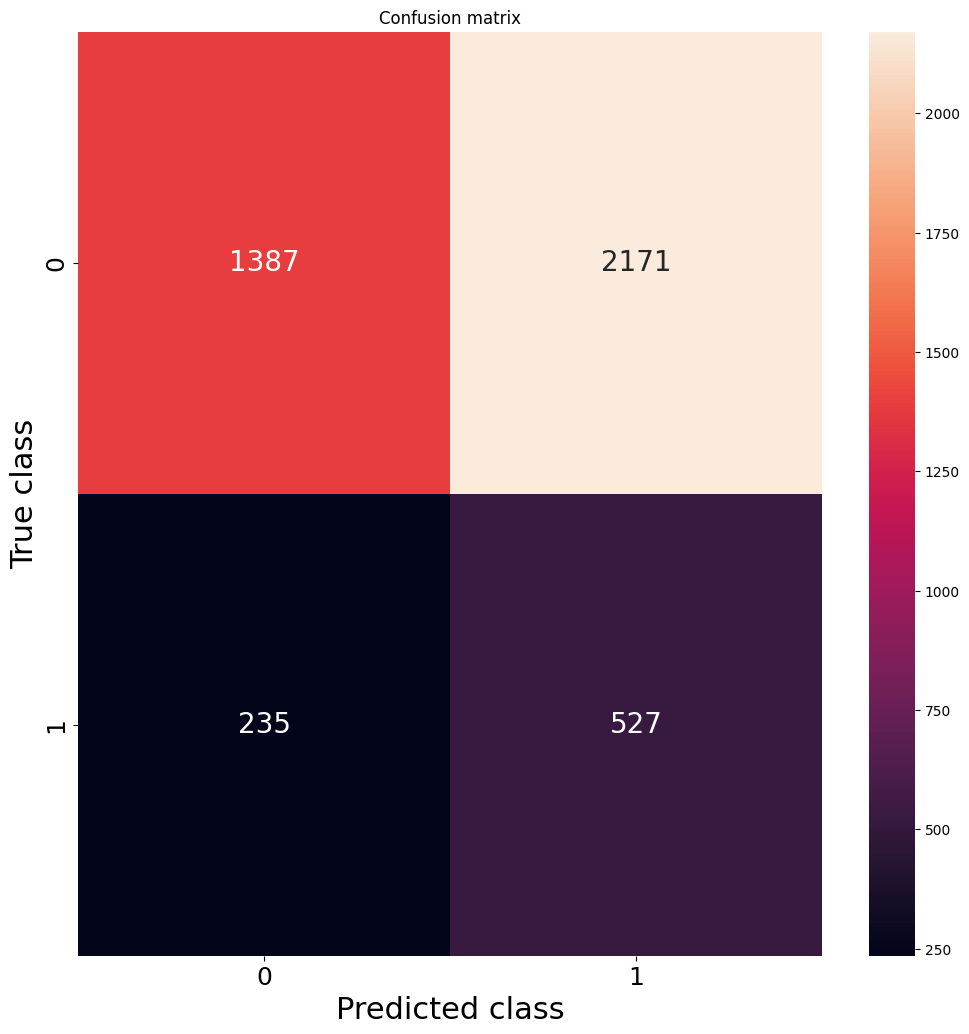

              precision    recall  f1-score   support

           0       0.86      0.39      0.54      3558
           1       0.20      0.69      0.30       762

    accuracy                           0.44      4320
   macro avg       0.53      0.54      0.42      4320
weighted avg       0.74      0.44      0.49      4320

Balanced Accuracy: 0.5407
Average Precision (PR-AUC): 0.1988
ROC AUC: 0.5386

Primeras 10 predicciones - Real vs Predicha vs Probabilidad:


,Real,Predicha,Probabilidad
0,0,0,0.407883
1,1,1,0.518464
2,1,1,0.629399
3,0,1,0.581642
4,0,1,0.613840
5,0,0,0.291688
6,0,1,0.639458
7,0,1,0.580789
8,1,1,0.551426
9,0,1,0.537443


In [ ]:
from imblearn.under_sampling import NearMiss
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import warnings
warnings.filterwarnings('ignore')

# Asegurarse de que X_train_processed_st, y_train_desc_st, X_test_processed_st, y_test_desc_st están disponibles del preprocesamiento anterior.
# Asegurarse de que run_model_balanced y mostrar_resultados están definidos en celdas anteriores.

# 1. Aplicar undersampling con NearMiss
print(f"Distribución antes del undersampling (ST): {Counter(y_train_desc_st)}")
us = NearMiss(sampling_strategy=0.5, n_neighbors=3, version=2)
X_train_res_st, y_train_res_st = us.fit_resample(X_train_processed_st, y_train_desc_st)
print(f"Distribución después del undersampling (ST): {Counter(y_train_res_st)}")

# 2. Entrenar el modelo con los datos remuestreados
print("\n--- Entrenando Modelo con datos remuestreados (NearMiss con ST) ---")
# Usar la función run_model_balanced definida previamente
model_resampled_st = run_model_balanced(X_train_res_st, y_train_res_st)
print("Modelo de Regresión Logística (NearMiss con ST) entrenado.")

# 3. Realizar predicciones y mostrar resultados en el conjunto de prueba original
pred_y_resampled_st = model_resampled_st.predict(X_test_processed_st)
pred_proba_resampled_st = model_resampled_st.predict_proba(X_test_processed_st)[:, 1]
print("\n--- Métricas de Evaluación en el Conjunto de Prueba (Modelo NearMiss con ST) ---")
mostrar_resultados(y_test_desc_st, pred_y_resampled_st, pred_proba_resampled_st)


Distribución antes del oversampling (ST): Counter({0: 14233, 1: 3047})
Distribución después del oversampling (ST): Counter({0: 14233, 1: 7116})

--- Entrenando Modelo con datos remuestreados (RandomOverSampler con ST) ---
Modelo de Regresión Logística (RandomOverSampler con ST) entrenado.

--- Métricas de Evaluación en el Conjunto de Prueba (Modelo RandomOverSampler con ST) ---


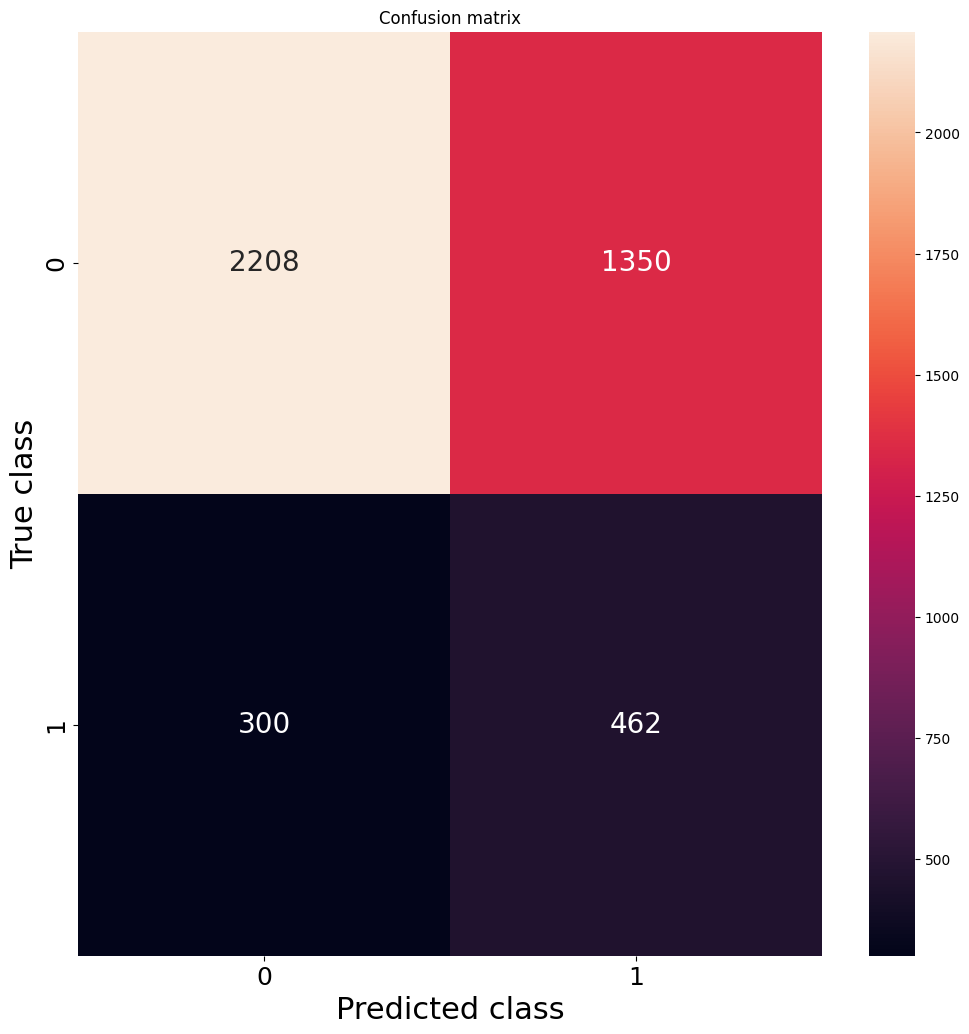

              precision    recall  f1-score   support

           0       0.88      0.62      0.73      3558
           1       0.25      0.61      0.36       762

    accuracy                           0.62      4320
   macro avg       0.57      0.61      0.54      4320
weighted avg       0.77      0.62      0.66      4320

Balanced Accuracy: 0.6134
Average Precision (PR-AUC): 0.2687
ROC AUC: 0.6397

Primeras 10 predicciones - Real vs Predicha vs Probabilidad:


,Real,Predicha,Probabilidad
0,0,1,0.544557
1,1,1,0.537630
2,1,1,0.535507
3,0,0,0.247427
4,0,0,0.475935
5,0,0,0.261984
6,0,1,0.713808
7,0,0,0.492636
8,1,1,0.675207
9,0,0,0.237716


In [ ]:
from imblearn.over_sampling import RandomOverSampler
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import warnings
warnings.filterwarnings('ignore')

# Asegurarse de que X_train_processed_st, y_train_desc_st, X_test_processed_st, y_test_desc_st están disponibles del preprocesamiento anterior.
# Asegurarse de que run_model_balanced y mostrar_resultados están definidos en celdas anteriores.

# 1. Aplicar oversampling con RandomOverSampler
print(f"Distribución antes del oversampling (ST): {Counter(y_train_desc_st)}")
os = RandomOverSampler(sampling_strategy=0.5, random_state=42) # Usar sampling_strategy y random_state para reproducibilidad
X_train_res_st_os, y_train_res_st_os = os.fit_resample(X_train_processed_st, y_train_desc_st)
print(f"Distribución después del oversampling (ST): {Counter(y_train_res_st_os)}")

# 2. Entrenar el modelo con los datos remuestreados
print("\n--- Entrenando Modelo con datos remuestreados (RandomOverSampler con ST) ---")
# Usar la función run_model_balanced definida previamente
model_oversampled_st = run_model_balanced(X_train_res_st_os, y_train_res_st_os)
print("Modelo de Regresión Logística (RandomOverSampler con ST) entrenado.")

# 3. Realizar predicciones y mostrar resultados en el conjunto de prueba original
pred_y_oversampled_st = model_oversampled_st.predict(X_test_processed_st)
pred_proba_oversampled_st = model_oversampled_st.predict_proba(X_test_processed_st)[:, 1]
print("\n--- Métricas de Evaluación en el Conjunto de Prueba (Modelo RandomOverSampler con ST) ---")
mostrar_resultados(y_test_desc_st, pred_y_oversampled_st, pred_proba_oversampled_st)
